# Handcrafted EEG features on TUAB: what works for pathology and brain-age?

This notebook (1) **summarises the state of the art** in feature extraction for EEG machine
learning, with an emphasis on **multi-scale methods** (wavelets, multiscale entropy, filter
banks), and (2) **benchmarks those features on the TUH Abnormal EEG Corpus (TUAB v3.0.0)**
for two targets:

* **pathology** — normal vs abnormal recording (the TUAB label), scored by AUROC / balanced accuracy;
* **age** — brain-age regression on *normal* recordings, scored by MAE / R².

Besides the classical wavelets (DWT, wavelet packets, Morlet CWT) it covers
**wavelet scattering networks** (Mallat's scattering transform), the multi-scale
representation that sits between handcrafted wavelets and CNNs.

It also audits the **data preparation**: what the stored TUAB pipeline did, what the signals
look like after it, and which preparation steps (crop, re-reference, band-pass, artifact
rejection, aggregation, recording length) change the result.

Everything runs on the full corpus (2,990 recordings). Feature extraction lives in
[`labram/features/`](../labram/features/) (`extractors.py` = per-window feature functions,
`tuab.py` = corpus runner with a cache, `riemann.py` = tangent-space mapping); this notebook only loads the cached features and
does the analysis.

**Contents**
1. State of the art: feature families, multi-scale methods, best practice, age-specific findings
2. Data, cohort and splits
3. Data-preparation audit (line noise, artifacts, channels, preparation ablation, recording length)
4. Visual analytics of features vs pathology and age
5. Benchmark: one model per feature family
6. Multi-scale deep dive: mother wavelet, depth, DWT vs WPD vs CWT, Morlet bandwidth, wavelet scattering, spectrogram features
7. Combined model, family ablation and the brain-age gap of abnormal EEGs
8. Conclusions and recommendations

Section 1.6 gives the **mathematical definition of every feature** as implemented. Figures
are numbered and their panels lettered: "Fig. 3b" is panel (b) of Figure 3.

<details><summary><b>List of figures</b></summary>

| Fig. | Section | Content |
|---|---|---|
| 1 | §2 | Cohort: age by label (a), abnormal rate by age (b) |
| 2 | §3.1 | Stored-signal PSD with 50/60/75 Hz markers (a), 60 Hz line index (b) |
| 3 | §3.2 | Window peak amplitude (a), rejection rate vs time (b), amplitude vs time (c), effect of the first minute on aggregated features (d) |
| 4 | §3.3 | Per-channel power of the stored 23 channels |
| 5 | §3.4 | Preparation ablation P0–P5: pathology (a), age (b) |
| 6 | §3.5 | Performance vs EEG duration: pathology (a), age (b) |
| 7 | §4 | Spectrum by age (a), normal vs abnormal (b), DWT relative energy (c) |
| 8 | §4 | Peak alpha frequency (a), 1/f exponent (b), multiscale PE (c) |
| 9 | §4.1 | Concrete example as heatmaps: STFT, multitaper, Morlet and DWT time–frequency tilings (a–h) |
| 10 | §4.2 | Spectral feature × channel maps: age ρ (a), pathology AUROC (b) |
| 11 | §5 | Benchmark of all families: pathology (a), age (b) |
| 12 | §5.2 | Performance curves: ROC CV (a) and test (b), precision–recall (c), REC CV (d) and test (e), age calibration (f) |
| 13 | §6.1 | DWT frequency selectivity of four mother wavelets (a–d) |
| 14 | §6.1 | Mother wavelet: pathology (a), age (b); DWT depth (c) |
| 15 | §6.2 | Fourier vs DWT/WPD/CWT/MSPE: pathology (a), age (b) |
| 16 | §6.3 | Scattering orders and scales: pathology (a), age (b) |
| 17 | §6.3 | Second-order scattering maps: pathology (a), age (b) |
| 18 | §6.4 | Spectrogram features (STFT, multitaper, dynamics, cepstra): pathology (a), age (b) |
| 19 | §7.2 | Brain-age: predicted vs true (a), corrected gap (b) |
</details>

### Key results (TUAB v3.0.0, 2,990 recordings; CV = subject-grouped 5-fold on the train pool, test = official eval set)

| | Pathology AUROC, CV / test | Age MAE in years (normal EEG), CV / test |
|---|---|---|
| baseline (age + sex / median age) | 0.675 / 0.714 | 13.2 / 13.7 |
| best single family: **filterbank Riemann**, linear | **0.922 / 0.918** | **8.22 / 7.58** |
| **all families combined** (12 families, 9,728 features) | **0.926 / 0.930** (gradient boosting; BAcc 0.85 / 0.84, sens 0.81 / 0.77, spec 0.89 / 0.91) | **7.87 / 7.21** (ridge) |
| published deep CNNs on TUAB-normal age (Engemann 2022, 10-fold CV) | – | 7.75–7.80 |
| spectral-type families (Welch, DWT, WPD, CWT, scattering, STFT/multitaper spectrograms, cepstra) | 0.898–0.917 | 8.5–9.3 (best variants: multitaper mean 8.43, 1 Hz Welch 8.48, scattering S1 8.49) |
| time domain / multiscale permutation entropy | 0.89–0.90 / 0.88 | 10.3–11.2 |

* **Preparation matters more than the wavelet** (Fig. 5). 19 channels + common average reference: +0.02 AUROC and −0.9 years. A 1–45 Hz band-pass: a further +0.045 AUROC for time features and −0.07 to −0.55 years depending on the family. The stored data is notched at 50 Hz, but TUH mains is **60 Hz**: 20% of recordings carry a strong 60 Hz line, and its level alone predicts the label (AUROC 0.61), so it is a confound (Fig. 2).
* **Multi-scale vs Fourier.** At recording level, DWT, WPD, CWT and scattering are **not better** than a good Fourier spectrum. What helps age is **frequency resolution** (1 Hz Welch bins, 10-cycle Morlet, 8-per-octave scattering S1). The mother wavelet barely matters for pathology (0.905–0.914). For age, Haar and bior3.5 are worst and db8/sym/coif are about 0.5 y better. 5–7 DWT levels are equivalent (Fig. 13–15).
* **Spectrograms.** Multitaper and STFT mean log-spectrograms (8.43 / 8.50 y) and 247 cepstral coefficients (8.53 y) match the 1 Hz Welch spectrum for age. Their std over time *hurts* age, but band-power **dynamics** add pathology information: STFT mean + dynamics reaches 0.915 / 0.916 AUROC vs 0.909 / 0.902 without (Fig. 18).
* **Errors are mostly missed abnormal recordings:** sensitivity is below specificity for every model; for the spectral, wavelet and Riemann families the test values are 0.73–0.80 vs 0.85–0.91 (Fig. 12).
* **Wavelet scattering.** Order 1 is a strong, compact spectral representation (age CV 8.49 y, test 7.51 y). Order 2 carries real but **redundant** information (AUROC 0.85–0.88 alone), and adding it to order 1 hurts linear models. Its strongest effects are slow-delta envelope modulations (Fig. 16–17).
* **Brain-age gap.** A normal-trained age model does **not** make abnormal EEGs look older (bias-corrected gap −1.8 y vs −0.6 y, AUROC 0.47, p = 0.36). Every normal-trained model *under*-estimates abnormal ages, by 6–15 y. Pathological slowing mimics the signature of a younger EEG (Fig. 19).

## 1. State of the art in EEG feature extraction

### 1.1 Feature families

| Family | What it captures | Typical implementation | Evidence |
|---|---|---|---|
| **Time domain** | amplitude, roughness, non-Gaussianity | variance, line length, skew/kurtosis, **Hjorth** activity/mobility/complexity (Hjorth 1970), zero crossings | cheap baseline; strong for seizures / artifacts |
| **Spectral (Fourier)** | oscillatory power per rhythm | **Welch PSD** (2–4 s Hann, 50% overlap), absolute & **relative band power** δ θ α β γ, ratios (θ/α, slowing ratio), spectral edge, spectral entropy, **peak alpha frequency** | the clinical workhorse; most pathology signal in TUAB is **slowing** (δ/θ) |
| **Aperiodic (1/f)** | broadband "background" | exponent + offset of a power-law fit (**FOOOF/specparam**, Donoghue 2020) | exponent **flattens with age** (Voytek 2015) |
| **Filter bank** | band-limited signals | zero-phase IIR/FIR band-pass → log-variance (≡ band power) or envelope | the input to CSP and Riemannian methods |
| **Spatial covariance (Riemannian)** | power **and** cross-channel coupling per band | covariance per band → **tangent space** projection (Barachant 2012) | **best non-deep brain-age model** (Sabbagh 2020; Engemann 2022) and best feature model on TUAB in Gemein 2020 |
| **Connectivity** | phase/amplitude coupling between channels | coherence, PLV, wPLI, AEC | informative but high-dimensional, volume-conduction confounds |
| **Spectrogram (STFT / multitaper)** | time-resolved spectrum at a *fixed* resolution | log-spectrogram (1–2 s windows) summarised over time (mean, std); multitaper (DPSS) for lower variance (Thomson 1982; Babadi & Brown 2014); band-power dynamics (variability, persistence, spectral flux) | standard in sleep EEG (Prerau et al. 2017) |
| **Cepstral coefficients** | spectral *envelope* in a few decorrelated numbers | MFCC-style: log filter-bank energies → DCT (Davis & Mermelstein 1980) | the first TUAB baseline: cepstra + CNN-MLP, 78.8% accuracy (Lopez de Diego 2017) |
| **Wavelet: DWT** | dyadic multi-resolution energy | multilevel decomposition (`db4` most common), per-level **energy / relative energy / wavelet entropy** (Rosso 2001) | the classic epilepsy feature (Adeli 2003; Subasi 2007) |
| **Wavelet: WPD** | uniform sub-bands, finer high-freq resolution | wavelet-packet tree, energy per node | used when β/γ detail matters |
| **Wavelet: CWT** | time–frequency scalogram | **complex Morlet**, 5–7 cycles; summary stats over time (mean, std, percentiles) | captures **non-stationarity** (bursts, intermittent slowing) that Welch averages away |
| **Wavelet scattering** | multi-scale energy **plus envelope modulations**, deformation-stable | fixed 2-layer "CNN" of Morlet filter banks + modulus + averaging (Mallat 2012; Andén & Mallat 2014; `kymatio`) | seizure / epileptiform-discharge detection (Ahmad 2017; ScatterFormer, Zheng 2023), audio/biomedical texture |
| **Other time–frequency** | adaptive / non-dyadic decomposition | S-transform (Stockwell 1996), EMD/HHT (Huang 1998), multitaper | niche; more parameters, less standard |
| **Complexity / multiscale entropy** | irregularity across time scales | sample/permutation entropy (Bandt & Pompe 2002) on **coarse-grained** signals (**MSE**, Costa 2002), Higuchi FD, DFA | age shifts entropy from coarse to fine scales (McIntosh 2014) |
| **Learned** | everything above, end-to-end | ShallowConvNet / Deep4 / TCN, foundation models (LaBraM, CBraMod) | ≈ equal to good features on TUAB pathology (Gemein 2020); small edge for age (Engemann 2022) |

### 1.2 Multi-scale methods: how they are used in practice

**Discrete wavelet transform (DWT).** Repeated high-/low-pass splitting gives a *dyadic*
tiling. At *f*<sub>s</sub> = 200 Hz, 6 levels give
A6 0–1.6 · D6 1.6–3.1 · D5 3.1–6.3 · D4 6.3–12.5 · D3 12.5–25 · D2 25–50 · D1 50–100 Hz,
which roughly matches δ/θ/α/β/γ. That is why **5–6 levels** (more for higher *f*<sub>s</sub>) is the
rule: pick the level *L* so that A<sub>L</sub> ends near 1–2 Hz.
* **Mother wavelets used in the literature:** Daubechies **db4** is the de-facto default
  (Adeli et al. 2003; Subasi 2007 and much of the seizure literature), followed by db2–db8,
  Symlets (sym4–sym9), Coiflets (coif1–coif5) and biorthogonal (bior/rbio) wavelets; Haar is
  used as a crude baseline. Systematic comparisons find **no universal winner** and small
  differences. Al-Qazzaz et al. (2015) ranked 45 orthogonal wavelets on how well they
  represent EEG; **sym9, coif3 and db7** came out on top. The usual selection criteria are
  similarity to the signal (cross-correlation, reconstruction error), the energy-to-Shannon-entropy
  ratio, and downstream accuracy.
* What matters physically is **filter length / vanishing moments**. Short wavelets (Haar, db2)
  have poor frequency selectivity, so energy leaks between levels. Longer ones (db8, sym9,
  dmey) separate bands better but suffer more boundary effects on short windows. Section 6.1
  measures both.
* **Features:** log energy (or mean |coef|, std) per level, **relative energy** per level,
  **wavelet entropy** (Rosso 2001). Sometimes skew/kurtosis of the coefficients is added.

**Wavelet packet decomposition (WPD)** splits both branches, so it gives 2<sup>L</sup>
equal-width bands (3.125 Hz at L = 5) with finer β/γ resolution. It is common in
BCI/emotion work; the same mother-wavelet choices apply.

**Continuous wavelet transform (CWT).** The standard EEG choice is the **complex Morlet**
wavelet (a Gaussian-windowed complex sinusoid) on log-spaced frequencies, with **3–7
cycles** (Cohen 2019 argues for specifying it by its FWHM). Fewer cycles give better
time resolution; more cycles give better frequency resolution. In PyWavelets this is
`cmorB-C` with *n*<sub>cycles</sub> = π·C·√(2B). Mexican-hat / Paul / Gaussian-derivative
wavelets are used for transient detection, not band power. For ML, the scalogram is
summarised per frequency by its **mean over time** (≈ a smoothed spectrum) and its
**variability over time** (std / percentiles). The variability is the information a
Welch PSD cannot carry.

**Spectrograms vs scalograms.** A short-time Fourier transform (STFT) uses **one window length
for all frequencies**, giving a fixed Heisenberg box $\Delta t\times\Delta f$ (1 s × 1 Hz for a 1 s Hann window;
$\sigma_t\sigma_f \ge 1/4\pi$ in general). Wavelets keep the **relative** bandwidth constant ($Q = f/\Delta f$): long
windows at low frequencies, short ones at high frequencies. A **multitaper** spectrogram averages
$K = 2NW-1$ orthogonal Slepian (DPSS) tapers. This lowers the variance of every time-frequency
pixel about $K$-fold, at the cost of a fixed smoothing of $\pm W = NW/T_{\text{seg}}$ Hz, and is the standard for
sleep EEG (Prerau et al. 2017). Summarised over time, a spectrogram gives
* the average spectrum (≈ Welch);
* its **temporal variability** (how intermittent each rhythm is);
* the **spectral flux** (how fast the spectrum changes).

**Cepstral coefficients** (MFCC-style) compress each frame's log filter-bank spectrum with a DCT,
the same trick as in speech: $c_0$ is the overall level, $c_1$ the tilt, and higher $c_k$ finer shape.

**Wavelet scattering networks.** A scattering network is a cascade of wavelet transforms and
modulus non-linearities with *fixed* Morlet filters, so it is a CNN with no learned weights
(Mallat 2012; Bruna & Mallat 2013):
* order 0: S0 = x ∗ φ (local mean, ~0 for band-passed EEG);
* order 1: S1(λ1) = |x ∗ ψλ1| ∗ φ, a constant-Q band energy, close to the Morlet CWT mean (and to mel-spectra in audio);
* order 2: S2(λ1, λ2) = ||x ∗ ψλ1| ∗ ψλ2| ∗ φ, the **modulation spectrum** of each rhythm's envelope. It encodes *how* alpha waxes and wanes, or how delta comes in bursts, at modulation frequency λ2 < λ1. The averaging φ in order 1 throws this information away.

The averaging scale 2<sup>J</sup> sets the time invariance and the slowest modulation; Q is the
number of wavelets per octave (Q1 = 8 is the audio standard; Q2 = 1). Andén & Mallat (2014)
**renormalise** order 2 by its parent (S2/S1) and take logs, which decorrelates it from band
power. The coefficients are Lipschitz-stable to small time-warps and translation-invariant up
to 2<sup>J</sup>, which suits EEG (rhythms drift in phase and frequency). In EEG they have
mostly been used for seizure and epileptiform-discharge detection (Ahmad et al. 2017;
ScatterFormer, Zheng et al. 2023). §6.3 checks whether second order adds anything for
pathology or age beyond first order and CWT statistics.

**Multiscale entropy (MSE).** Coarse-graining (averaging non-overlapping blocks of *s*
samples) followed by sample or permutation entropy gives an entropy-vs-scale curve.
**Multiscale permutation entropy** is the fast, robust variant. Fine scales reflect local,
fast dynamics; coarse scales reflect slow, distributed ones.

**Filter bank + Riemannian geometry.** Band-pass into ~6–9 bands, compute a spatial
covariance per band, then project each covariance onto the tangent space at the
(Riemannian) mean. This gives a multi-band representation that includes power *and*
coupling, and it is invariant to linear mixing (volume conduction, reference). It was the
best feature model for TUAB pathology in Gemein 2020 and for age in Engemann 2022.

### 1.3 Best-practice preparation pipeline (consensus of TUAB / brain-age studies)

1. **Channel harmonisation:** a fixed common subset (19–21 electrodes of 10-20) in a fixed order.
2. **Re-reference:** common average reference (or keep a consistent recorded reference). Exclude ear electrodes (A1/A2) if you re-reference.
3. **Filtering:** high-pass 0.1–1 Hz, low-pass ≈ 45–49 Hz (Engemann 2022: 0.1–49 Hz), and a **notch at the local mains frequency** (60 Hz in the US: TUH).
4. **Resample** to a common rate (100–250 Hz).
5. **Crop:** drop the first ~1 min, which is full of set-up artifacts (Gemein 2020); use a fixed maximum duration.
6. **Artifact handling:** clip or reject windows above ~±800 µV (Gemein), or reject/repair per channel per window (**autoreject**, Jas 2017).
7. **Windowing:** 2–10 s epochs. Compute features per window and **aggregate per recording with the median** (Gemein 2020 found the median best).
8. **Transform:** log of power-like features; standardise features (fit on train only).
9. **Validation:** **subject-disjoint** splits, (nested) CV for hyper-parameters, held-out test set.
10. **Brain age only:** train on healthy/normal recordings. Correct the regression-to-the-mean bias of the brain-age gap with a linear fit (Smith 2019; de Lange & Cole 2020) before comparing groups.

### 1.4 Age prediction specifically

* **Benchmarks on TUAB-normal** (Engemann et al. 2022, 10-fold CV, MAE in years): dummy 13.6 · handcrafted features 10.8 · **filterbank-Riemann 8.3** · ShallowNet 7.8 · Deep4 7.8.
* Other EEG brain-age work: sleep EEG (Sun et al. 2019, feature-based, MAE 8.1 y on 2,621 MGH patients), deep learning on polysomnography (Brink-Kjaer et al. 2022, MAE 5.8 y) and resting EEG (Khayretdinova et al. 2022, CNN on TD-BRAIN, MAE 5.96 y in CV) and mobile EEG (Banville et al. 2024). Typical adult MAEs are 6–10 years.
* **Physiological markers.** The **peak alpha frequency** rises through childhood and slows in old age (Chiang 2011). Relative δ/θ fall and β rises with development. The **1/f exponent flattens** with age (Voytek 2015). Fine-scale entropy rises and coarse-scale entropy falls (McIntosh 2014).
* TUAB contains **children**, so the age effects are non-monotonic (development + ageing). This favours non-linear models, or at least features that capture both arms.

### 1.5 Reference results for TUAB pathology
* Gemein et al. 2020 (TUAB v2): handcrafted features + RF / auto-sklearn ≈ 84–85% accuracy, **Riemannian ≈ 86%**, deep ConvNets/TCN ≈ 84–86%. The authors conclude that methods saturate in the mid-80s, plausibly because of **label noise** (moderate inter-rater agreement).
* Window-level foundation models (LaBraM, CBraMod, BIOT) report ≈ 80–83% balanced accuracy on 10 s windows; recording-level aggregation is easier.

<details><summary><b>References</b></summary>

* Adeli H, Zhou Z, Dadmehr N (2003) Analysis of EEG records in an epileptic patient using wavelet transform. *J Neurosci Methods* 123:69–87.
* Al-Qazzaz NK et al. (2015) Selection of mother wavelet functions for multi-channel EEG signal analysis during a working memory task. *Sensors* 15:29015. https://doi.org/10.3390/s151129015
* Babadi B, Brown EN (2014) A review of multitaper spectral analysis. *IEEE Trans Biomed Eng* 61:1555–1564.
* Ahmad MZ, Kamboh AM, Saleem S, Khan AA (2017) Mallat's scattering transform based anomaly sensing for detection of seizures in scalp EEG. *IEEE Access* 5.
* Andén J, Mallat S (2014) Deep scattering spectrum. *IEEE Trans Signal Process* 62:4114–4128.
* Andreux M et al. (2020) Kymatio: scattering transforms in Python. *JMLR* 21(60):1–6.
* Bandt C, Pompe B (2002) Permutation entropy. *Phys Rev Lett* 88:174102.
* Banville H et al. (2024) Do try this at home: age prediction from sleep and meditation with large-scale low-cost mobile EEG. *Imaging Neuroscience*.
* Barachant A et al. (2012) Multiclass brain–computer interface classification by Riemannian geometry. *IEEE TBME* 59:920–928.
* Bi J, Bennett KP (2003) Regression error characteristic curves. *Proc. 20th ICML*, 43–50.
* Bruna J, Mallat S (2013) Invariant scattering convolution networks. *IEEE TPAMI* 35:1872–1886.
* Chiang AKI et al. (2011) Age trends and sex differences of alpha rhythms including split alpha peaks. *Clin Neurophysiol* 122:1505–1517.
* Cohen MX (2019) A better way to define and describe Morlet wavelets for time-frequency analysis. *NeuroImage* 199:81–86.
* Costa M, Goldberger AL, Peng CK (2002) Multiscale entropy analysis of complex physiologic time series. *Phys Rev Lett* 89:068102.
* Davis SB, Mermelstein P (1980) Comparison of parametric representations for monosyllabic word recognition in continuously spoken sentences. *IEEE Trans Acoust Speech Signal Process* 28:357–366.
* de Lange AMG, Cole JH (2020) Commentary: Correction procedures in brain-age prediction. *NeuroImage Clin* 26:102229.
* Donoghue T et al. (2020) Parameterizing neural power spectra into periodic and aperiodic components. *Nat Neurosci* 23:1655–1665.
* Engemann DA et al. (2022) A reusable benchmark of brain-age prediction from M/EEG resting-state signals. *NeuroImage* 262:119521.
* Gemein LAW et al. (2020) Machine-learning-based diagnostics of EEG pathology. *NeuroImage* 220:117021. https://arxiv.org/abs/2002.05115
* Hjorth B (1970) EEG analysis based on time domain properties. *EEG Clin Neurophysiol* 29:306–310.
* Huang NE et al. (1998) The empirical mode decomposition and the Hilbert spectrum. *Proc R Soc A* 454:903–995.
* Jas M et al. (2017) Autoreject: automated artifact rejection for MEG and EEG data. *NeuroImage* 159:417–429.
* Jiang W-B, Zhao L-M, Lu B-L (2024) Large brain model for learning generic representations with tremendous EEG data in BCI. *ICLR*.
* Lopez de Diego S (2017) Automated interpretation of abnormal adult electroencephalograms. MS thesis, Temple University.
* Mallat S (2012) Group invariant scattering. *Commun Pure Appl Math* 65:1331–1398.
* McIntosh AR et al. (2014) Spatiotemporal dependency of age-related changes in brain signal variability. *Cereb Cortex* 24:1806–1817.
* Prerau MJ et al. (2017) Sleep neurophysiological dynamics through the lens of multitaper spectral analysis. *Physiology* 32:60–92.
* Rosso OA et al. (2001) Wavelet entropy: a new tool for analysis of short duration brain electrical signals. *J Neurosci Methods* 105:65–75.
* Sabbagh D et al. (2020) Predictive regression modeling with MEG/EEG: from source power to signals and cognitive states. *NeuroImage* 222:116893.
* Smith SM et al. (2019) Estimation of brain age delta from brain imaging. *NeuroImage* 200:528–539.
* Stockwell RG, Mansinha L, Lowe RP (1996) Localization of the complex spectrum: the S transform. *IEEE Trans Signal Process* 44:998–1001.
* Schirrmeister RT et al. (2017) Deep learning with convolutional neural networks for decoding and visualization of EEG pathology. *IEEE SPMB*. https://arxiv.org/abs/1708.08012
* Subasi A (2007) EEG signal classification using wavelet feature extraction and a mixture of expert model. *Expert Syst Appl* 32:1084–1093.
* Brink-Kjaer A et al. (2022) Age estimation from sleep studies using deep learning predicts life expectancy. *npj Digit Med* 5:103.
* Khayretdinova M et al. (2022) Predicting age from resting-state scalp EEG signals with deep convolutional neural networks on TD-brain dataset. *Front Aging Neurosci* 14:1019869.
* Sun H et al. (2019) Brain age from the electroencephalogram of sleep. *Neurobiol Aging* 74:112–120.
* Thomson DJ (1982) Spectrum estimation and harmonic analysis. *Proc IEEE* 70:1055–1096.
* Voytek B et al. (2015) Age-related changes in 1/f neural electrophysiological noise. *J Neurosci* 35:13257–13265.
* Wang J et al. (2025) CBraMod: a criss-cross brain foundation model for EEG decoding. *ICLR*. https://arxiv.org/abs/2412.07236
* Yang C, Westover MB, Sun J (2023) BIOT: biosignal transformer for cross-data learning in the wild. *NeurIPS*.
* Zheng R et al. (2023) ScatterFormer: locally-invariant scattering transformer for patient-independent multispectral detection of epileptiform discharges. *AAAI*.
</details>

### 1.6 Feature definitions (as implemented in `labram/features/`)

**Notation.** Recording $r$, 10 s window $w$ ($T = 2000$ samples at $f_s = 200$ Hz), channel
$c \in \{1..C\}$, signal $x_{r,w,c}(t)$ in µV. A feature $\phi$ is computed per window and
channel, then aggregated per recording.

**Preparation.**
* Common average reference: $\tilde x_c(t) = x_c(t) - \frac{1}{C}\sum_{c'=1}^{C} x_{c'}(t)$.
* Zero-phase band-pass: a 4th-order Butterworth $H$ run forward and backward, so $|H_{\text{eff}}(f)| = |H(f)|^2$ and the phase is zero.
* Recording-level aggregation: $\phi_r = \operatorname{median}_{w \in \mathcal W_r} \phi_{r,w}$, where $\mathcal W_r$ are the clean windows after the first minute (§3.2).

**Time domain** (Hjorth 1970).
$$\text{activity} = \sigma_x^2,\qquad \text{mobility } M(x) = \sqrt{\frac{\sigma^2_{x'}}{\sigma^2_{x}}},\qquad \text{complexity} = \frac{M(x')}{M(x)},\qquad LL = \frac{1}{T-1}\sum_{t}\lvert x(t+1)-x(t)\rvert$$
The derivative $x'$ is the first difference. The set also includes skewness, excess kurtosis, and the zero-crossing rate of $x - \bar x$.

**Welch spectrum.** $K$ Hann-windowed segments $v$ of 2 s with 50 % overlap ($\Delta f = 0.5$ Hz):
$$\hat P(f) = \frac{1}{K}\sum_{k=1}^{K}\frac{\bigl\lvert\sum_t v(t)\,x_k(t)\,e^{-i2\pi f t/f_s}\bigr\rvert^2}{f_s\sum_t v(t)^2}$$
* Band power $P_b = \int_{b}\hat P(f)\,df$ for $b \in$ {δ 1–4, θ 4–8, α 8–13, β 13–30, γ 30–45 Hz}.
* Relative power $p_b = P_b / P_{[1,45]}$.
* Ratios $\log_{10}(P_\theta/P_\alpha)$ and slowing $\log_{10}\frac{P_\delta+P_\theta}{P_\alpha+P_\beta}$.
* With $\hat p(f) = \hat P(f)/\sum_{f'\in[1,45)}\hat P(f')$:
  * spectral edge $\text{SEF}_{95} = \min\{f : \sum_{f'\le f}\hat p(f') \ge 0.95\}$;
  * spectral entropy $H = -\frac{1}{\ln N_f}\sum_f \hat p(f)\ln\hat p(f)$;
  * peak alpha frequency $\text{PAF} = \arg\max_{6\le f\le 14}\hat P(f)$.
* Aperiodic (1/f) component: least-squares fit $\log_{10}\hat P(f) \approx b - \chi\log_{10}f$ on $f\in[2,40]\setminus[7,14]$ Hz. The features are the exponent $\chi$ and the offset $b$.
* The **1 Hz bins** are $\log_{10}P_{[k,k+1)}$ for $k = 1..44$.

**Spectrograms.** With a window $v$ of $N_v$ samples sliding by $N_v/2$ (frame $\tau$):
$$S(f,\tau) = \frac{\bigl\lvert\sum_t v(t-\tau)\,x(t)\,e^{-i2\pi ft/f_s}\bigr\rvert^2}{f_s\sum_t v(t)^2}, \qquad S_{\text{MT}}(f,\tau) = \frac1K\sum_{k=1}^{K}\frac{\bigl\lvert\sum_t v_k(t-\tau)\,x(t)\,e^{-i2\pi ft/f_s}\bigr\rvert^2}{f_s\sum_t v_k(t)^2}$$
* STFT: 1 s Hann window, giving 1 Hz bins and 19 frames per 10 s window.
* Multitaper: 2 s DPSS tapers $v_k$ with $NW = 2$ and $K = 3$, i.e. ±1 Hz smoothing and 9 frames.

Per 1 Hz bin, the features are the mean and the std over frames of $\log_{10}S$.

*Dynamics.* With the band log-power $\ell_b(\tau) = \log_{10}\sum_{f\in b}S(f,\tau)\Delta f$, the features are its
variability $\operatorname{std}_\tau\ell_b$, its persistence $\text{ac}_1(\ell_b) = \frac{\sum_\tau(\ell_b(\tau)-\bar\ell_b)(\ell_b(\tau+1)-\bar\ell_b)}{\sum_\tau(\ell_b(\tau)-\bar\ell_b)^2}$, and the spectral flux
$$\Phi = \operatorname{mean}_\tau\sqrt{\operatorname{mean}_f\bigl(\log_{10}S(f,\tau+1)-\log_{10}S(f,\tau)\bigr)^2}.$$

*Cepstral coefficients.*
* Warped frequency axis $u(f) = \ln(1+f/4\,\text{Hz})$, linear below ~4 Hz and logarithmic above (the EEG analogue of the mel scale).
* $M = 16$ triangular filters $H_m$, equally spaced in $u$ over 1–45 Hz, on a 0.25 Hz zero-padded grid.
* Filter-bank energies and their DCT-II:
$$E_m(\tau) = \frac{\sum_f H_m(f)S(f,\tau)}{\sum_f H_m(f)}, \qquad c_k(\tau) = \alpha_k\sum_{m=0}^{M-1}\log_{10}E_m(\tau)\cos\frac{\pi k(m+\frac12)}{M}, \qquad \alpha_0 = \sqrt{1/M},\ \alpha_{k>0} = \sqrt{2/M}$$
* The features are the mean and std over $\tau$ of $c_0..c_{12}$. A gain change only moves $c_0$.

**Discrete wavelet transform** (Mallat's filter bank, low-pass $h$ and high-pass $g[n] = (-1)^n h[L-1-n]$, $a_0 = x$):
$$a_{j+1}[k] = \sum_n h[n-2k]\,a_j[n], \qquad d_{j+1}[k] = \sum_n g[n-2k]\,a_j[n]$$
Detail $d_j$ covers the nominal band $\bigl[f_s/2^{j+1},\, f_s/2^{j}\bigr]$ and the approximation $a_L$ covers $\bigl[0,\, f_s/2^{L+1}\bigr]$. At 200 Hz, $L = 6$:

| A6 | D6 | D5 | D4 | D3 | D2 | D1 |
|---|---|---|---|---|---|---|
| 0–1.6 | 1.6–3.1 | 3.1–6.3 | 6.3–12.5 | 12.5–25 | 25–50 | 50–100 Hz |

Per level (with $u_j \in \{a_L, d_L, \dots, d_1\}$ and $N_j$ coefficients):
$$E_j = \frac{1}{N_j}\sum_k u_j[k]^2\ \ (\text{used as }\log_{10}E_j), \qquad \rho_j = \frac{\sum_k u_j[k]^2}{\sum_i\sum_k u_i[k]^2}, \qquad \text{WE} = -\sum_j \rho_j\ln\rho_j$$
WE is the wavelet entropy of Rosso et al. (2001).

**Wavelet packets.** Both the low- and high-pass outputs are split again. The level-$J$ node $n$ (frequency order) covers $\bigl[n\frac{f_s}{2^{J+1}},\,(n+1)\frac{f_s}{2^{J+1}}\bigr]$, i.e. 3.125 Hz for $J = 5$. The feature is $\log_{10}$ of the mean squared coefficient of each node below 50 Hz.

**Continuous wavelet transform (complex Morlet).** The pywt `cmorB-C` wavelet:
$$\psi_{B,C}(t) = \frac{1}{\sqrt{\pi B}}\,e^{-t^2/B}\,e^{i2\pi Ct}, \qquad n_{\text{cyc}} = \pi C\sqrt{2B}, \qquad \sigma_f = \frac{f_0}{n_{\text{cyc}}}, \qquad \sigma_t = \frac{1}{2\pi\sigma_f}$$
At analysis frequency $f_0$ it is applied in the frequency domain with unit peak gain:
$$W(f_0,t) = \mathcal F^{-1}\!\left[\hat X(f)\,\hat H_{f_0}(f)\right](t), \qquad \hat H_{f_0}(f) = 2\exp\!\Bigl(-\pi^2BC^2\bigl(\tfrac{f}{f_0}-1\bigr)^2\Bigr)\mathbb 1[f>0]$$
With this normalisation, a sinusoid of amplitude $A$ at $f_0$ gives $\lvert W\rvert = A$. There are 25 log-spaced $f_0 \in [1, 45]$ Hz. Per window, the features are
$$\mu(f_0) = \frac{1}{T}\sum_t \log_{10}\lvert W(f_0,t)\rvert^2 \quad\text{and}\quad s(f_0) = \operatorname{std}_t \log_{10}\lvert W(f_0,t)\rvert^2.$$

**Wavelet scattering** (Mallat 2012; Andén & Mallat 2014). Morlet filters $\psi_\lambda$ with $Q$ filters per octave and a low-pass $\phi_J$ of width $2^J$ samples (100 Hz signal):
$$S_1x(\lambda_1) = \Bigl\langle \lvert x*\psi_{\lambda_1}\rvert * \phi_J \Bigr\rangle_t, \qquad S_2x(\lambda_1,\lambda_2) = \Bigl\langle \bigl\lvert\lvert x*\psi_{\lambda_1}\rvert*\psi_{\lambda_2}\bigr\rvert * \phi_J \Bigr\rangle_t, \quad \lambda_2 < \lambda_1$$
The features are $\log_{10}S_1$ and the renormalised $\log_{10}\bigl(S_2/S_1(\lambda_1)\bigr)$, where $\langle\cdot\rangle_t$ is the window average.

**Multiscale permutation entropy** (Costa 2002; Bandt & Pompe 2002). Coarse-grain at scale $s$:
$$y^{(s)}_i = \frac{1}{s}\sum_{t=(i-1)s+1}^{is}x(t)$$
For each ordinal pattern $\pi$ of $(y_i,\dots,y_{i+m-1})$, with $m = 4$:
$$\text{PE}_s = -\frac{1}{\ln m!}\sum_{\pi} p_s(\pi)\ln p_s(\pi), \qquad s \in \{1,2,3,4,6,8,10,15,20\}$$

**Filterbank Riemann** (Barachant 2012; Sabbagh 2020).
* Band covariance, averaged over clean windows: $C_{r,b} = \frac{1}{\lvert\mathcal W_r\rvert}\sum_{w}\frac{1}{T}X_{r,w,b}X_{r,w,b}^{\top}$, with $X_{r,w,b} \in \mathbb R^{19\times T}$ band-passed to $b$.
* CAR makes $C$ rank 18, so it is projected with $U\in\mathbb R^{19\times18}$, an orthonormal basis of $\mathbf 1^\perp$: $C \mapsto U^\top C U$.
* Shrinkage: $C \mapsto (1-\varepsilon)C + \varepsilon\frac{\operatorname{tr}C}{18}I$.
* With the affine-invariant distance $\delta_R(A,B) = \lVert\log(A^{-1/2}BA^{-1/2})\rVert_F$, the reference is the Riemannian mean of the training fold, $\bar C_b = \arg\min_G\sum_r\delta_R^2(G, C_{r,b})$.
* Tangent vector: $s_{r,b} = \operatorname{upper}\bigl(\log(\bar C_b^{-1/2}C_{r,b}\bar C_b^{-1/2})\bigr)$, with off-diagonal entries scaled by $\sqrt2$ so that $\lVert s_{r,b}\rVert_2 = \delta_R(\bar C_b, C_{r,b})$. This gives 171 features per band and 6 bands.

## 2. Data, cohort and splits

**Input.** The per-recording export `processed_npy/recordings/<stem>.npy` (`float32
[n_samples, 23]`, µV). This is exactly the signal LaBraM is fine-tuned on: `make_TUAB.py`
band-passed it 0.1–75 Hz, notched it at **50 Hz**, and resampled it to 200 Hz.

**What is extracted** (`labram/features/tuab.py`, one worker per recording):
* the first **36 × 10 s windows** (6 min). Windows 0–5 (the first minute) are kept only for the preparation audit;
* **reference preparation** for the benchmark: 19 scalp 10-20 channels → common average reference $\tilde x_c = x_c - \frac1C\sum_{c'}x_{c'}$ → 1–45 Hz zero-phase Butterworth band-pass → skip the first minute → reject windows with $\max\lvert x\rvert > 800$ µV or a flat channel ($\sigma < 0.5$ µV) → per-window features → $\phi_r = \operatorname{median}_{w\in\mathcal W_r}\phi_{r,w}$ (§1.6, §3.2);
* a cheap **core** set (time + spectral + DWT-db4) saved *per window* under three signal preparations, so the preparation ablations in §3 can be done here.

Spectrogram features (§6.4) go to a third, small cache (~3 min to build).
Wavelet-scattering coefficients (kymatio, §6.3) go to a second cache. They are computed on
the same clean windows, after anti-aliased resampling to 100 Hz: the reference signal is
band-limited to 45 Hz, so the 50–100 Hz octave would be empty.

The caches are built once (~45 min each on 5–6 cores) and reused:
```bash
python -m labram.features.tuab --npy_root /data/.../processed_npy --n_jobs 6
python -m labram.features.tuab --npy_root /data/.../processed_npy --n_jobs 6 --kind scattering
python -m labram.features.tuab --npy_root /data/.../processed_npy --n_jobs 6 --kind spectrogram
```

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pywt
import matplotlib.pyplot as plt
from cycler import cycler
from scipy import stats
from threadpoolctl import threadpool_limits

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from labram.features import extractors as fx
from labram.features import tuab

warnings.filterwarnings("ignore", category=DeprecationWarning)
NPY_ROOT = os.environ.get(
    "TUAB_NPY_ROOT", "/data/datasets/EEG-public/TAUB/TUH_Abnormal/v3.0.0/edf/processed_npy")
CACHE = os.environ.get("TUAB_FEATURE_CACHE", tuab.default_cache_path(NPY_ROOT))
N_JOBS = int(os.environ.get("N_JOBS", "6"))
if not os.path.exists(CACHE):
    tuab.extract_corpus(NPY_ROOT, CACHE, n_jobs=N_JOBS)

CACHE_SCAT = os.environ.get("TUAB_SCATTERING_CACHE", tuab.default_cache_path(NPY_ROOT, "scattering"))
if not os.path.exists(CACHE_SCAT):
    tuab.extract_corpus(NPY_ROOT, CACHE_SCAT, n_jobs=N_JOBS, kind="scattering")

t0 = time.time()
D = dict(np.load(CACHE))
NAMES = tuab.feature_names()
_scat = np.load(CACHE_SCAT)
assert (_scat["meta/stem"] == D["meta/stem"]).all(), "caches must cover the same recordings in the same order"
D.update({k: _scat[k] for k in _scat.files if k.startswith("rec/")})
NAMES.update(tuab.scattering_names())
CACHE_SPEC = os.environ.get("TUAB_SPECTROGRAM_CACHE", tuab.default_cache_path(NPY_ROOT, "spectrogram"))
if not os.path.exists(CACHE_SPEC):
    tuab.extract_corpus(NPY_ROOT, CACHE_SPEC, n_jobs=N_JOBS, kind="spectrogram")
_spec = np.load(CACHE_SPEC)
assert (_spec["meta/stem"] == D["meta/stem"]).all()
D.update({k: _spec[k] for k in _spec.files if k.startswith("rec/")})
NAMES.update(tuab.spectrogram_names())
CH = tuab.CHANNELS_1020
print(f"loaded {CACHE}: {len(D)} arrays, {sum(v.nbytes for v in D.values()) / 1e9:.2f} GB "
      f"in {time.time() - t0:.0f}s")

# --- plotting style: recessive grid, thin marks, fixed categorical order -----
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
C_NORMAL, C_ABN = PAL[0], PAL[1]
SEQ = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]  # ordinal blue ramp
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=PAL), "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "text.color": "#0b0b0b", "lines.linewidth": 2.0,
    "legend.frameon": False, "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "patch.linewidth": 0,
})


def finish(fig, axes, n, title):
    # Number the figure ("Figure n.") and letter its panels: "(a) <title>", "(b) ...".
    axs = list(np.ravel(axes))
    if len(axs) > 1:
        for k, ax in enumerate(axs):
            ax.set_title(f"({chr(97 + k)}) " + ax.get_title())
    fig.suptitle(f"Figure {n}. {title}", fontsize=12, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.4 / fig.get_size_inches()[1]))
    plt.show()

loaded /data/datasets/EEG-public/TAUB/TUH_Abnormal/v3.0.0/edf/features_handcrafted/tuab_features_v1.npz: 48 arrays, 1.31 GB in 10s


In [2]:
meta = pd.DataFrame({k[len("meta/"):]: D[k] for k in D if k.startswith("meta/") and D[k].ndim == 1})
meta["abnormal"] = (meta.label == "abnormal").astype(int)
N = len(meta)
pool = meta.source_split.isin(["train", "val"]).to_numpy()   # model-development pool
test = meta.source_split.eq("test").to_numpy()               # official TUAB eval set (held out)
normal = meta.label.eq("normal").to_numpy()
age = meta.age.to_numpy()
age_ok = np.isfinite(age)

overlap = set(meta.subject[pool]) & set(meta.subject[test])
print(f"{N} recordings, {meta.subject.nunique()} subjects; pool {pool.sum()} / test {test.sum()} "
      f"recordings; subjects shared between pool and test: {len(overlap)}")
print(f"age missing (TUH 90+ redaction): {(~age_ok).sum()}")
display(meta.groupby(["source_split", "label"]).agg(
    recordings=("stem", "size"), subjects=("subject", "nunique"),
    age_median=("age", "median"), age_min=("age", "min"), age_max=("age", "max"),
    female_frac=("sex", lambda s: (s == "F").mean())).round(2))

2990 recordings, 2328 subjects; pool 2714 / test 276 recordings; subjects shared between pool and test: 0
age missing (TUH 90+ redaction): 15


recordings  subjects  age_median  age_min  age_max  \
source_split label                                                          
test         abnormal         126       105        56.0     11.0     89.0   
             normal           150       148        42.0     18.0     88.0   
train        abnormal        1052       713        54.0      1.0     89.0   
             normal          1090       989        44.0      1.0     88.0   
val          abnormal         291       179        56.0     12.0     88.0   
             normal           281       248        44.0     10.0     87.0   

                       female_frac  
source_split label                  
test         abnormal         0.50  
             normal           0.57  
train        abnormal         0.49  
             normal           0.58  
val          abnormal         0.56  
             normal           0.49

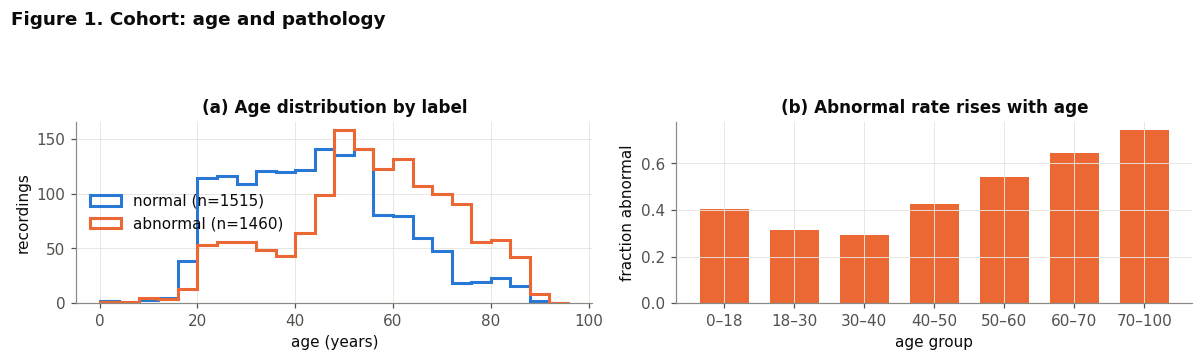

AUROC of age alone for abnormal vs normal: 0.676


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
bins = np.arange(0, 100, 4)
for lab, c in [("normal", C_NORMAL), ("abnormal", C_ABN)]:
    a = age[(meta.label == lab).to_numpy() & age_ok]
    axes[0].hist(a, bins=bins, histtype="step", lw=2, color=c, label=f"{lab} (n={len(a)})")
axes[0].set(xlabel="age (years)", ylabel="recordings", title="Age distribution by label")
axes[0].legend()
dec = pd.cut(meta.age, [0, 18, 30, 40, 50, 60, 70, 100], right=False)
frac = meta.groupby(dec, observed=True).abnormal.mean()
axes[1].bar(range(len(frac)), frac.values, color=C_ABN, width=0.7)
axes[1].set_xticks(range(len(frac)), [f"{int(i.left)}–{int(i.right)}" for i in frac.index])
axes[1].set(xlabel="age group", ylabel="fraction abnormal", title="Abnormal rate rises with age")
finish(fig, axes, 1, "Cohort: age and pathology")

auc_age = stats.mannwhitneyu(age[age_ok & ~normal], age[age_ok & normal]).statistic / (
    (age_ok & ~normal).sum() * (age_ok & normal).sum())
print(f"AUROC of age alone for abnormal vs normal: {auc_age:.3f}")

**Figure 1.** (a) Age histograms of normal and abnormal recordings (all splits). (b) Fraction of abnormal recordings per age group.

**Note:** the age distributions differ by label (Fig. 1a). Abnormal recordings are older,
the abnormal rate rises with age (Fig. 1b), and age alone separates the classes somewhat:
$\text{AUROC}_{\text{age}} = P(\text{age}^{+} > \text{age}^{-})$, printed above. Every pathology model should beat an **age-only
baseline** (§5), and the brain-age gap analysis (§7) needs bias correction.

## 3. Data-preparation audit

### 3.1 What is left in the spectrum after the stored pipeline
`make_TUAB.py` applies a **50 Hz** notch, the European mains frequency. TUH was recorded
in the US, where mains is **60 Hz**, and the 75 Hz low-pass leaves 60 Hz in the signal.
The grand-average PSD (channel-averaged, per recording) shows what actually remains
(Fig. 2a). To quantify the mains line, each recording gets a **60 Hz line index**: the peak
log power within ±0.5 Hz of 60 Hz minus the mean log power 2–4 Hz away on both sides,
$$L_{60} = \max_{\lvert f-60\rvert\le0.5}\log_{10}\bar P(f) \;-\; \operatorname{mean}_{2\le\lvert f-60\rvert\le4}\log_{10}\bar P(f),$$
where $\bar P = \frac1C\sum_c\hat P_c$ is the channel-averaged PSD of the stored signal.
$L_{60} = 1$ means the line is 10× above its neighbourhood (Fig. 2b).

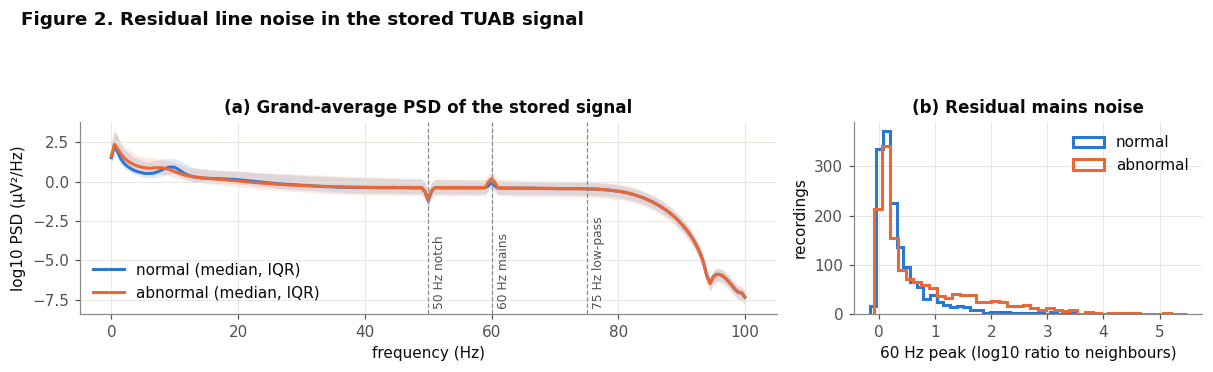

recordings with a 60 Hz peak > 10x neighbours: 19.6%
AUROC of the 60 Hz line-noise level for abnormal vs normal: 0.610
Spearman rho of the 60 Hz level with age: 0.075


In [4]:
freqs_full = D["mean_psd_freqs"][0]
lp = D["mean_psd"]  # [N, 201] log10 µV²/Hz, stored 23-ch signal
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [2, 1]})
for lab, c in [("normal", C_NORMAL), ("abnormal", C_ABN)]:
    m = (meta.label == lab).to_numpy()
    q = np.percentile(lp[m], [25, 50, 75], axis=0)
    axes[0].fill_between(freqs_full, q[0], q[2], color=c, alpha=0.15, lw=0)
    axes[0].plot(freqs_full, q[1], color=c, label=f"{lab} (median, IQR)")
for f0, txt in [(50, "50 Hz notch"), (60, "60 Hz mains"), (75, "75 Hz low-pass")]:
    axes[0].axvline(f0, color="#8a8984", lw=0.8, ls="--")
    axes[0].text(f0 + 0.8, axes[0].get_ylim()[0] + 0.3, txt, fontsize=8, color="#52514e", rotation=90, va="bottom")
axes[0].set(xlabel="frequency (Hz)", ylabel="log10 PSD (µV²/Hz)", title="Grand-average PSD of the stored signal")
axes[0].legend(loc="lower left")

def line_index(f0):
    on = (freqs_full >= f0 - 0.5) & (freqs_full <= f0 + 0.5)
    off = ((freqs_full >= f0 - 4) & (freqs_full <= f0 - 2)) | ((freqs_full >= f0 + 2) & (freqs_full <= f0 + 4))
    return lp[:, on].max(axis=1) - lp[:, off].mean(axis=1)

line60 = line_index(60.0)
meta["line60_log_ratio"] = line60
for lab, c in [("normal", C_NORMAL), ("abnormal", C_ABN)]:
    axes[1].hist(line60[(meta.label == lab).to_numpy()], bins=40, histtype="step", lw=2, color=c, label=lab)
axes[1].set(xlabel="60 Hz peak (log10 ratio to neighbours)", ylabel="recordings", title="Residual mains noise")
axes[1].legend(); finish(fig, axes, 2, "Residual line noise in the stored TUAB signal")

from sklearn.metrics import roc_auc_score
print(f"recordings with a 60 Hz peak > 10x neighbours: {(line60 > 1).mean():.1%}")
print(f"AUROC of the 60 Hz line-noise level for abnormal vs normal: {roc_auc_score(meta.abnormal, line60):.3f}")
print(f"Spearman rho of the 60 Hz level with age: {stats.spearmanr(line60[age_ok], age[age_ok])[0]:.3f}")

**Figure 2.** (a) Channel-averaged Welch PSD $\bar P(f)$ of the stored signal: median (line) and inter-quartile range (band) across recordings, by label. Dashed lines mark the 50 Hz notch, the 60 Hz US mains and the 75 Hz low-pass. (b) Distribution of the 60 Hz line index $L_{60}$ per recording.

**Takeaways.** The 50 Hz notch removes nothing useful (there is no 50 Hz in TUH; the dip at
50 Hz in Fig. 2a is the notch itself). The 60 Hz mains line is still present (Fig. 2a), in a
heavy tail of recordings (Fig. 2b), and its level differs between groups, so it
is a recording-condition **confound**. Any feature that integrates power above 45 Hz picks it
up: total variance, line length, zero crossings, the DWT detail **D1 (50–100 Hz)** and
**D2 (25–50 Hz)**, and the high WPD nodes. The fix is a **low-pass ≤ 45–49 Hz** (or a 60 Hz
notch) before computing features. The reference preparation does this (1–45 Hz); §3.4
measures what it changes.

### 3.2 Artifacts over time: is skipping the first minute justified?

Gemein et al. (2020) discard the first minute of every TUAB recording because set-up
artifacts accumulate there. This section tests that claim on the data, in three steps:
(1) are artifacts more frequent in the first minute, (2) is the signal itself different,
and (3) does it matter once windows are rejected and aggregated robustly?

**Windows and quality statistics.** Recording $r$ is cut into 10 s windows $w = 0,\dots,35$
(window $w$ covers $[10w, 10(w+1))$ s, so $w < 6$ is the first minute). Each window holds
$x_{r,w,c}(t)$, $t = 1..T$, on the **stored** 23-channel signal. Per window:
$$A_{r,w} = \max_{c,\,t}\lvert x_{r,w,c}(t)\rvert, \qquad \sigma_{r,w,c} = \sqrt{\tfrac1T\textstyle\sum_t\bigl(x_{r,w,c}(t)-\bar x_{r,w,c}\bigr)^2}, \qquad m_{r,w} = \operatorname{median}_c\,\sigma_{r,w,c}$$

**Rejection rule.** A window is rejected if any sample exceeds the ±800 µV clipping
threshold of Gemein (2020), or any channel is flat (disconnected electrode):
$$q_{r,w} = \mathbb 1\!\left[A_{r,w} > 800\ \mu\text{V}\ \ \lor\ \ \min_c\sigma_{r,w,c} < 0.5\ \mu\text{V}\right]$$

**(1) Rejection rates.** Over $R$ recordings, the per-window rate and the rates in the first
minute and in minutes 1–6 are
$$\hat p_w = \frac1R\sum_r q_{r,w}, \qquad \hat p_{\text{first}} = \frac{1}{6R}\sum_r\sum_{w<6}q_{r,w}, \qquad \hat p_{\text{rest}} = \frac{1}{30R}\sum_r\sum_{w\ge6}q_{r,w}.$$
Their ratio is the **relative risk** $\text{RR} = \hat p_{\text{first}}/\hat p_{\text{rest}}$, with a 95 % CI from 2,000
bootstrap resamples of *recordings*, since windows within a recording are not independent.
Because recordings differ in quality, the comparison is also made **within recording**:
$$d_r = \bar q_{r,\text{first}} - \bar q_{r,\text{rest}}, \qquad H_0:\ \operatorname{median}(d_r) = 0\quad\text{(Wilcoxon signed-rank test)}.$$

**(2) Amplitude drift.** The ratio of the typical channel amplitude in the first minute to
the rest is $\rho_r = \operatorname{median}_{w<6}m_{r,w}\,/\,\operatorname{median}_{w\ge6}m_{r,w}$. Here $\rho_r > 1$ means a
noisier start.

**(3) Effect on aggregated features.** Suppose a fraction $\varepsilon$ of windows are artifacts with feature
mean $\mu_a$, and the clean windows have mean $\mu_c$. The mean aggregate is then biased
linearly:
$$\mathbb E\bigl[\bar\phi^{\,\text{mean}}_r\bigr] = (1-\varepsilon)\,\mu_c + \varepsilon\,\mu_a \;\Rightarrow\; \text{bias} = \varepsilon(\mu_a-\mu_c).$$
This is unbounded in $\mu_a$. The median has a breakdown point of 1/2: for $\varepsilon < 1/2$ it
stays between the $\tfrac{1/2-\varepsilon}{1-\varepsilon}$ and $\tfrac{1/2}{1-\varepsilon}$ quantiles of the clean windows, whatever the artifacts look
like. This is measured directly as the shift in a recording's aggregated log-power when the
first minute is included:
$$\Delta_r^{\text{agg}} = \operatorname{agg}_{w\in\{0..35\}}\phi_{r,w} - \operatorname{agg}_{w\in\{6..35\}}\phi_{r,w}, \qquad \phi_{r,w} = \tfrac1C\textstyle\sum_c\log_{10}\sigma^2_{r,w,c}, \qquad \text{agg}\in\{\text{mean},\text{median}\}.$$
Here $\Delta_r$ is computed without rejection, i.e. the worst case.

,recordings,p_first,p_rest,RR,RR_CI95,recs d_r>0,recs d_r<0,Wilcoxon p
all,2990,9.7%,3.6%,2.71,"[2.45, 3.00]",26.8%,14.9%,9.4e-91
normal,1521,8.8%,2.6%,3.37,"[2.87, 3.98]",26.0%,14.5%,1.5e-47
abnormal,1469,10.6%,4.6%,2.31,"[2.06, 2.64]",27.6%,15.5%,6.1e-45


,rejected,by amplitude (>800 µV),by flat channel
minute,,,
0,9.69%,9.55%,0.14%
1,3.60%,3.53%,0.07%
2,3.96%,3.89%,0.08%
3,3.63%,3.55%,0.09%
4,3.24%,3.16%,0.08%
5,3.46%,3.38%,0.08%


amplitude ratio rho_r: median 1.034, IQR [0.926, 1.243], recordings with rho > 1.5: 16.0%; Wilcoxon (log rho = 0) p = 2.9e-43
shift of aggregated log10 variance when the first minute is included (mean  ): median |Delta| 0.0243, 95th pct |Delta| 0.2374, max |Delta| 0.408 (log10 units)
shift of aggregated log10 variance when the first minute is included (median): median |Delta| 0.0144, 95th pct |Delta| 0.0835, max |Delta| 0.647 (log10 units)
recordings with no clean window after the skip (fallback: use all windows 6-35): 22


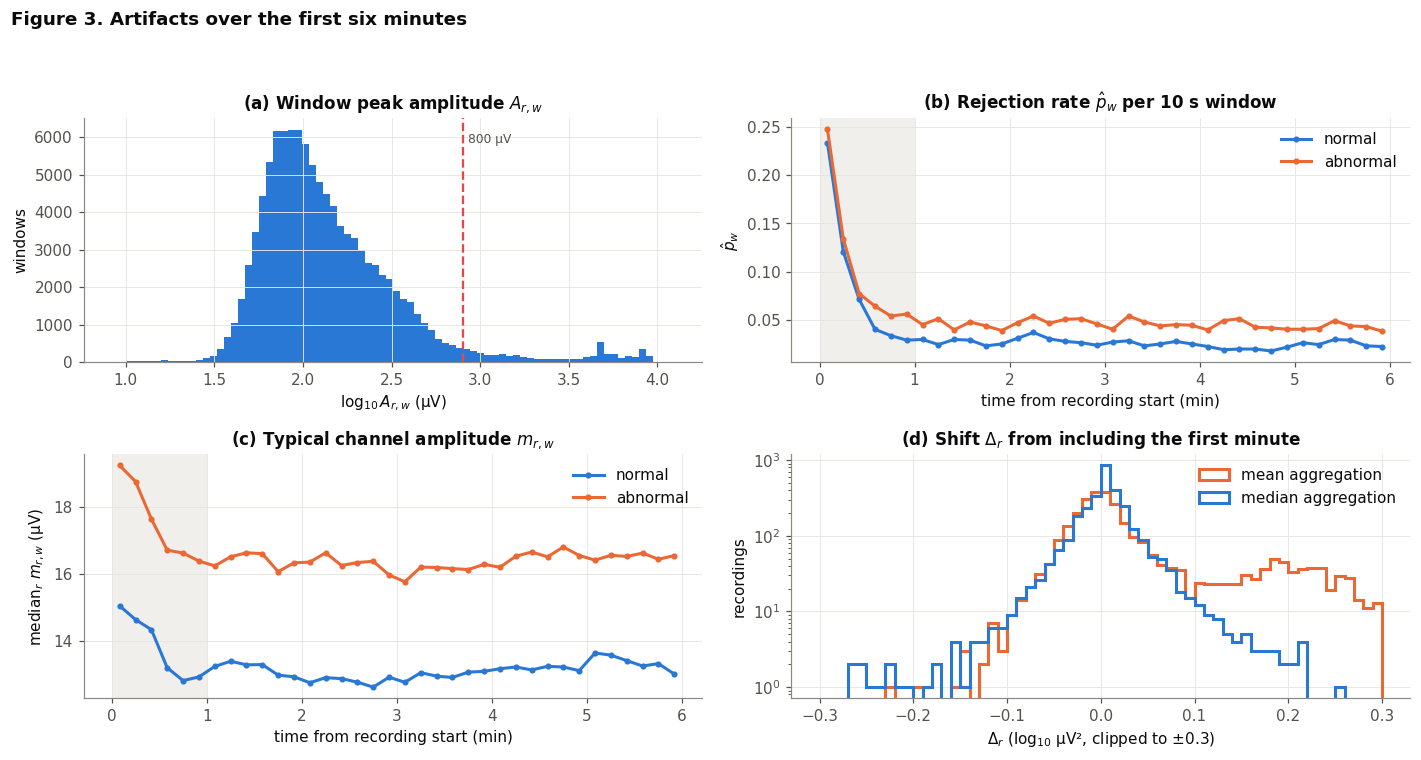

In [5]:
q = D["quality"]  # [N, 36, 4]: A = max|x|, max ptp, min_c sigma, median_c sigma
A, s_min, m_rw = q[..., 0], q[..., 2], q[..., 3]
clean = (A <= tuab.REJECT_ABS_UV) & (s_min >= tuab.FLAT_STD_UV)
rej = ~clean
FIRST, REST = slice(0, 6), slice(6, 36)
lab_arr = meta.label.to_numpy()

def rr_stats(m):
    # Pooled rates, relative risk with recording-bootstrap CI, paired Wilcoxon on d_r.
    r = rej[m]
    p1, p2 = r[:, FIRST].mean(), r[:, REST].mean()
    rng = np.random.default_rng(0)
    boot = []
    for _ in range(2000):
        i = rng.integers(0, len(r), len(r))
        boot.append(r[i][:, FIRST].mean() / max(r[i][:, REST].mean(), 1e-12))
    d = r[:, FIRST].mean(1) - r[:, REST].mean(1)
    nz = d[d != 0]
    p = stats.wilcoxon(nz).pvalue if len(nz) else np.nan
    return {"recordings": int(m.sum()), "p_first": p1, "p_rest": p2, "RR": p1 / p2,
            "RR_CI95": f"[{np.percentile(boot, 2.5):.2f}, {np.percentile(boot, 97.5):.2f}]",
            "recs d_r>0": (d > 0).mean(), "recs d_r<0": (d < 0).mean(), "Wilcoxon p": p}

tab = pd.DataFrame({"all": rr_stats(np.ones(N, bool)), "normal": rr_stats(lab_arr == "normal"),
                    "abnormal": rr_stats(lab_arr == "abnormal")}).T
display(tab.style.format({"p_first": "{:.1%}", "p_rest": "{:.1%}", "RR": "{:.2f}", "recs d_r>0": "{:.1%}",
                          "recs d_r<0": "{:.1%}", "Wilcoxon p": "{:.1e}"}))

# Reason for rejection and per-minute rates
amp, flat = A > tuab.REJECT_ABS_UV, s_min < tuab.FLAT_STD_UV
per_min = pd.DataFrame({
    "minute": np.arange(6),
    "rejected": [rej[:, 6 * k:6 * (k + 1)].mean() for k in range(6)],
    "by amplitude (>800 µV)": [amp[:, 6 * k:6 * (k + 1)].mean() for k in range(6)],
    "by flat channel": [flat[:, 6 * k:6 * (k + 1)].mean() for k in range(6)],
}).set_index("minute")
display(per_min.style.format("{:.2%}"))

# Amplitude drift and aggregated-feature shift
rho = np.median(m_rw[:, FIRST], 1) / np.maximum(np.median(m_rw[:, REST], 1), 1e-6)
rho = rho[np.isfinite(rho) & (rho > 0)]
phi = np.nanmean(D["core/stored_23ch/time"][..., 0], axis=2)  # channel-mean log10 variance, [N, 36]
delta = {"mean": phi.mean(1) - phi[:, REST].mean(1),
         "median": np.median(phi, 1) - np.median(phi[:, REST], 1)}
print(f"amplitude ratio rho_r: median {np.median(rho):.3f}, IQR [{np.percentile(rho, 25):.3f}, {np.percentile(rho, 75):.3f}], "
      f"recordings with rho > 1.5: {(rho > 1.5).mean():.1%}; Wilcoxon (log rho = 0) p = {stats.wilcoxon(np.log(rho)).pvalue:.1e}")
for k, v in delta.items():
    print(f"shift of aggregated log10 variance when the first minute is included ({k:6s}): "
          f"median |Delta| {np.median(np.abs(v)):.4f}, 95th pct |Delta| {np.percentile(np.abs(v), 95):.4f}, max |Delta| {np.abs(v).max():.3f} (log10 units)")
print(f"recordings with no clean window after the skip (fallback: use all windows 6-35): {(~clean[:, 6:].any(axis=1)).sum()}")

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
ax = axes[0, 0]
ax.hist(np.log10(A.ravel()), bins=80, color=PAL[0])
ax.axvline(np.log10(800), color=PAL[7], lw=1.5, ls="--")
ax.text(np.log10(800) + 0.03, ax.get_ylim()[1] * 0.9, "800 µV", color="#52514e", fontsize=8)
ax.set(xlabel=r"$\log_{10} A_{r,w}$ (µV)", ylabel="windows", title=r"Window peak amplitude $A_{r,w}$")
t_min = (np.arange(36) + 0.5) * 10 / 60
for lab, c in [("normal", C_NORMAL), ("abnormal", C_ABN)]:
    m = lab_arr == lab
    axes[0, 1].plot(t_min, rej[m].mean(axis=0), color=c, label=lab, marker="o", ms=3)
    axes[1, 0].plot(t_min, np.median(m_rw[m], axis=0), color=c, label=lab, marker="o", ms=3)
for ax in (axes[0, 1], axes[1, 0]):
    ax.axvspan(0, 1, color="#e6e5e0", alpha=0.6, lw=0); ax.legend()
axes[0, 1].set(xlabel="time from recording start (min)", ylabel=r"$\hat p_w$", title=r"Rejection rate $\hat p_w$ per 10 s window")
axes[1, 0].set(xlabel="time from recording start (min)", ylabel=r"median$_r\ m_{r,w}$ (µV)", title=r"Typical channel amplitude $m_{r,w}$")
bins = np.linspace(-0.3, 0.3, 61)
for (k, v), c in zip(delta.items(), [PAL[1], PAL[0]]):
    axes[1, 1].hist(np.clip(v, -0.3, 0.3), bins=bins, histtype="step", lw=2, color=c, label=f"{k} aggregation")
axes[1, 1].set(yscale="log", xlabel=r"$\Delta_r$ (log$_{10}$ µV², clipped to ±0.3)", ylabel="recordings",
               title=r"Shift $\Delta_r$ from including the first minute")
axes[1, 1].legend()
finish(fig, axes, 3, "Artifacts over the first six minutes")

**Figure 3.** Window quality on the stored 23-channel signal for all 2,990 recordings.
(a) Distribution of the window peak amplitude $A_{r,w}$; the dashed line is the 800 µV
rejection threshold. (b) Rejection rate $\hat p_w$ for each 10 s window, by label; the shaded
area is the first minute. (c) Median over recordings of the typical channel amplitude
$m_{r,w}$. (d) Per-recording shift $\Delta_r$ of the aggregated channel-mean log-variance
when windows 0–5 are included (no rejection), for mean and median aggregation; log y-axis.

**Results.**

**(1) Artifacts concentrate at the start.**
* $\hat p_{\text{first}} = 9.7\%$ vs $\hat p_{\text{rest}} = 3.6\%$, so $\text{RR} = 2.71$ (95 % CI 2.45–3.00).
* By label: 3.4 in normal and 2.3 in abnormal recordings. Abnormal recordings are noisier throughout ($\hat p_{\text{rest}}$ 4.6 % vs 2.6 %).
* Within recordings, 26.8 % have $d_r > 0$ and 14.9 % have $d_r < 0$. The other 58 % have no rejected window in either period. Wilcoxon $p \approx 10^{-90}$.
* The excess is confined to **minute 0**: minutes 1–5 all sit at 3.2–4.0 %. Within minute 0 it decays quickly, with $\hat p_w$ = 24 %, 13 %, 7.5 %, 5.3 %, 4.4 %, 4.3 % for $w = 0..5$ (Fig. 3b). So **the first 20–30 s carry most of it**.
* It is almost entirely **amplitude excursions** (> 800 µV), not flat channels (0.1 %).

**(2) Amplitude drift is small on average but present in a subset.** The median $\rho_r$ is 1.03 (IQR 0.93–1.24): typical amplitude barely changes (Fig. 3c), but 16 % of recordings are ≥ 1.5× louder in their first minute.

**(3) Mean aggregation is sensitive; the median is robust** (Fig. 3d). Including the first minute *without* rejection shifts the channel-mean log-variance by:

| aggregation | median $\lvert\Delta_r\rvert$ | 95th percentile $\lvert\Delta_r\rvert$ | recordings with $\lvert\Delta_r\rvert > 0.05$ |
|---|---|---|---|
| mean | 0.024 | 0.24 (variance ×1.7) | 30 % |
| median | 0.014 | 0.08 | 13 % |

This matches the contamination model: $\varepsilon = 6/36$ windows with $\mu_a \gg \mu_c$ moves the mean by $\varepsilon(\mu_a - \mu_c)$, while the median moves only by a quantile shift.

**Verdict.**
* Skipping the first minute is **justified as a cheap way to remove a real, systematic bias**: artifacts are 2.7× more frequent there, and mean-aggregated features of about a third of recordings move measurably.
* It is **not a large lever for prediction**. In the ablation (Fig. 5) P0 → P1 changes AUROC by 0.000 and age MAE by −0.10 y, and rejection (P1 → P2) adds +0.001 / −0.08 y. Three things combine:
  * only 6 of 36 windows are affected;
  * artifact rates differ only modestly between labels (4.6 % vs 2.6 % after the first minute), so they add mostly noise rather than label signal;
  * standardised linear models down-weight noisy features.
* Practical rule: drop the first **30 s** (where 24 % / 13 % / 7.5 % of windows are bad) or the first minute, reject > 800 µV windows, and aggregate with the median. Any one of these largely protects against the others being skipped.

### 3.3 Channels and reference
TUAB's `01_tcp_ar` EDFs are average-referenced at acquisition and contain 23 channels, including
the ear electrodes **A1/A2** and the non-10-20 anterior-temporal **T1/T2**. Fig. 4 shows the
per-channel amplitude, $\operatorname{median}_r\operatorname{median}_{w\in\mathcal W_r}\log_{10}\sigma^2_{r,w,c}$.
Re-referencing to the 19 scalp channels with $\tilde x_c = x_c - \frac1{19}\sum_{c'}x_{c'}$ removes the
component common to all of them (reference activity, global artifacts), at the cost of
making the 19 signals linearly dependent ($\sum_c\tilde x_c = 0$, rank 18).

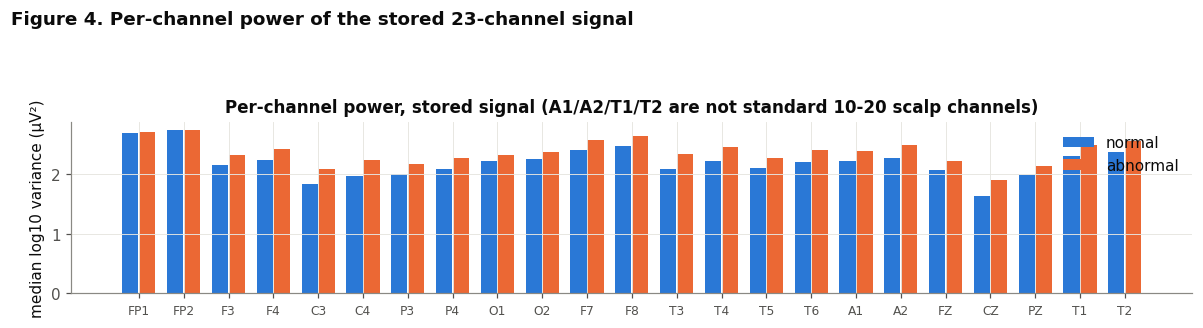

In [6]:
st = D["core/stored_23ch/time"][..., 0]  # log10 variance, [N, 36, 23]
use = clean[:, 6:].copy()
use[~use.any(axis=1)] = True  # same fallback as the extractor: no clean window -> all windows
st_med = np.nanmedian(np.where(use[..., None], st[:, 6:], np.nan), axis=1)
fig, ax = plt.subplots(figsize=(11, 3))
xs = np.arange(len(tuab.STORED_CHANNELS))
for k, (lab, c) in enumerate([("normal", C_NORMAL), ("abnormal", C_ABN)]):
    m = (meta.label == lab).to_numpy()
    ax.bar(xs + (k - 0.5) * 0.38, np.nanmedian(st_med[m], axis=0), width=0.36, color=c, label=lab)
ax.set_xticks(xs, tuab.STORED_CHANNELS, rotation=0, fontsize=8)
ax.set(ylabel="median log10 variance (µV²)", title="Per-channel power, stored signal (A1/A2/T1/T2 are not standard 10-20 scalp channels)")
ax.legend(); finish(fig, ax, 4, "Per-channel power of the stored 23-channel signal")

**Figure 4.** Median over recordings of the per-channel log-variance $\log_{10}\sigma^2$ of the stored signal (clean windows after the first minute), by label.

### 3.4 Preparation ablation
The **core** features (time + spectral + DWT-db4, per channel) are evaluated with the same
linear models and the same subject-grouped 5-fold CV as §5, adding one preparation step at a
time:

| step | channels / reference | filter | windows | rejection | aggregation |
|---|---|---|---|---|---|
| P0 | 23 stored | stored 0.1–75 Hz | 0–35 (incl. first min) | – | mean |
| P1 | 23 stored | stored | **6–35 (skip 1st min)** | – | mean |
| P2 | 23 stored | stored | 6–35 | **±800 µV / flat** | mean |
| P3 | 23 stored | stored | 6–35 | yes | **median** |
| P4 | **19 ch 10-20, CAR** | stored | 6–35 | yes | median |
| P5 | 19 ch, CAR | **1–45 Hz** | 6–35 | yes | median ← *reference* |

Aggregation over the selected windows $\mathcal W_r$ is either
$\bar\phi_r = \frac{1}{\lvert\mathcal W_r\rvert}\sum_{w\in\mathcal W_r}\phi_{r,w}$ (mean) or
$\tilde\phi_r = \operatorname{median}_{w\in\mathcal W_r}\phi_{r,w}$ (median). Fig. 5 shows the cross-validated scores after each step.

In [7]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegressionCV, RidgeCV
from sklearn.metrics import (balanced_accuracy_score, mean_absolute_error, r2_score, roc_auc_score)
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SUBJ = meta.subject.to_numpy()
Y = {"abn": meta.abnormal.to_numpy().astype(float), "age": age}
DEV = {"abn": np.where(pool)[0], "age": np.where(pool & normal & age_ok)[0]}
TEST = {"abn": np.where(test)[0], "age": np.where(test & normal & age_ok)[0]}
TEST_AGE_ABN = np.where(test & ~normal & age_ok)[0]  # held-out abnormal recordings with a known age
FOLDS = {
    "abn": list(StratifiedGroupKFold(5, shuffle=True, random_state=0).split(
        DEV["abn"], Y["abn"][DEV["abn"]], SUBJ[DEV["abn"]])),
    "age": list(GroupKFold(5, shuffle=True, random_state=0).split(DEV["age"], groups=SUBJ[DEV["age"]])),
}
print({t: (len(DEV[t]), len(TEST[t])) for t in DEV}, "(development pool, held-out test)")


def make_model(task, kind="linear"):
    if kind == "linear":
        if task == "abn":
            return make_pipeline(StandardScaler(), LogisticRegressionCV(
                Cs=np.logspace(-4, 0, 9), cv=3, scoring="roc_auc", max_iter=5000, n_jobs=N_JOBS))
        return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 5, 25)))
    params = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=20,
                  l2_regularization=1.0, early_stopping=False, random_state=0)
    if task == "abn":
        return HistGradientBoostingClassifier(**params)
    return HistGradientBoostingRegressor(loss="absolute_error", **params)


def _predict(model, X, task):
    return model.predict_proba(X)[:, 1] if task == "abn" else model.predict(X)


def scores(task, y, p):
    if task == "abn":
        yhat = p >= 0.5
        return {"AUROC": roc_auc_score(y, p), "BAcc": balanced_accuracy_score(y, yhat),
                "Acc": np.mean(yhat == (y == 1)),
                "Sens": np.mean(yhat[y == 1]),     # abnormal recall
                "Spec": np.mean(~yhat[y == 0])}    # normal recall
    return {"MAE": mean_absolute_error(y, p), "R2": r2_score(y, p), "r": stats.pearsonr(y, p)[0],
            "bias": np.mean(p - y)}


def evaluate(X, task, kind="linear", pre=None, run_test=True):
    # Subject-grouped 5-fold CV on the development pool (+ fit on the whole pool -> held-out test).
    # `pre` is an optional unsupervised transformer fitted inside each fold (e.g. tangent space).
    X = np.asarray(X, dtype=np.float64)
    idx, y = DEV[task], Y[task]

    def pipe():
        m = make_model(task, kind)
        return make_pipeline(clone(pre), m) if pre is not None else m

    oof, per_fold = np.full(len(idx), np.nan), []
    with threadpool_limits(N_JOBS):
        for tr, va in FOLDS[task]:
            m = pipe().fit(X[idx[tr]], y[idx[tr]])
            oof[va] = _predict(m, X[idx[va]], task)
            per_fold.append(scores(task, y[idx[va]], oof[va]))
        out = {}
        for k in per_fold[0]:
            v = [s[k] for s in per_fold]
            out[f"cv_{k}"], out[f"cv_{k}_sd"] = np.mean(v), np.std(v)
        test_pred = None
        if run_test:
            m = pipe().fit(X[idx], y[idx])
            test_pred = _predict(m, X[TEST[task]], task)
            out.update({f"test_{k}": v for k, v in scores(task, y[TEST[task]], test_pred).items()})
            if task == "age":  # the same normal-trained model on held-out *abnormal* recordings
                pa = _predict(m, X[TEST_AGE_ABN], task)
                out.update({f"test_abn_{k}": v for k, v in scores("age", age[TEST_AGE_ABN], pa).items()})
    return out, oof, test_pred


def nan_to_median(X):
    # Replace non-finite entries (e.g. log of an exactly-zero band) with the column median.
    X = np.array(X, dtype=np.float64)
    bad = ~np.isfinite(X)
    if bad.any():
        med = np.nanmedian(np.where(bad, np.nan, X), axis=0)
        X[bad] = np.take(med, np.where(bad)[1])
    return X

{'abn': (2714, 276), 'age': (1366, 149)} (development pool, held-out test)


In [8]:
CORE_FAMS = ("time", "spectral", "dwt_db4")


def core_matrix(variant, fams=CORE_FAMS, start=6, reject=True, agg="median", n_windows=None):
    # Per-window core features -> one row per recording.
    sel = np.zeros(36, bool); sel[start:] = True
    mask = sel[None] & (clean if reject else True)
    mask = np.where(mask.any(axis=1, keepdims=True), mask, sel[None])  # fallback: all selected
    if n_windows is not None:
        mask &= np.cumsum(mask, axis=1) <= n_windows
    arr = np.concatenate([D[f"core/{variant}/{f}"] for f in fams], axis=-1)  # [N, 36, C, F]
    arr = np.where(mask[:, :, None, None], arr, np.nan)
    red = np.nanmedian(arr, axis=1) if agg == "median" else np.nanmean(arr, axis=1)
    return nan_to_median(red.reshape(N, -1))


LADDER = [
    ("P0 stored, all windows, mean", dict(variant="stored_23ch", start=0, reject=False, agg="mean")),
    ("P1 + skip 1st minute", dict(variant="stored_23ch", start=6, reject=False, agg="mean")),
    ("P2 + reject artifacts", dict(variant="stored_23ch", start=6, reject=True, agg="mean")),
    ("P3 + median aggregation", dict(variant="stored_23ch", start=6, reject=True, agg="median")),
    ("P4 + 19ch CAR", dict(variant="1020_car", start=6, reject=True, agg="median")),
    ("P5 + 1-45 Hz band-pass", dict(variant="1020_car_1-45Hz", start=6, reject=True, agg="median")),
]
rows = []
t0 = time.time()
for name, kw in LADDER:
    for fams in [CORE_FAMS, ("time",), ("spectral",), ("dwt_db4",)]:
        X = core_matrix(fams=fams, **kw)
        for task in ("abn", "age"):
            r, _, _ = evaluate(X, task, run_test=False)
            rows.append({"prep": name, "features": "+".join(fams), "task": task, **r})
ladder = pd.DataFrame(rows)
print(f"{time.time() - t0:.0f}s")
show = ladder.pivot_table(index="prep", columns=["task", "features"], values=["cv_AUROC", "cv_MAE"], sort=False)
display(show.dropna(axis=1, how="all").round(3))

176s


cv_AUROC                          \
task                                           abn                           
features                     time+spectral+dwt_db4   time spectral dwt_db4   
prep                                                                         
P0 stored, all windows, mean                 0.895  0.812    0.887   0.887   
P1 + skip 1st minute                         0.895  0.813    0.887   0.887   
P2 + reject artifacts                        0.896  0.820    0.888   0.888   
P3 + median aggregation                      0.893  0.827    0.887   0.887   
P4 + 19ch CAR                                0.914  0.849    0.912   0.913   
P5 + 1-45 Hz band-pass                       0.913  0.894    0.910   0.914   

                                            cv_MAE                           
task                                           age                           
features                     time+spectral+dwt_db4    time spectral dwt_db4  
prep                                                                         
P0 stored, all windows, mean                 9.860  12.105    9.846  10.117  
P1 + skip 1st minute                         9.761  12.052    9.860  10.120  
P2 + reject artifacts                        9.682  11.885    9.820  10.082  
P3 + median aggregation                      9.891  12.037   10.114  10.331  
P4 + 19ch CAR                                9.004  11.722    9.038   9.329  
P5 + 1-45 Hz band-pass                       8.827  11.177    8.971   9.139

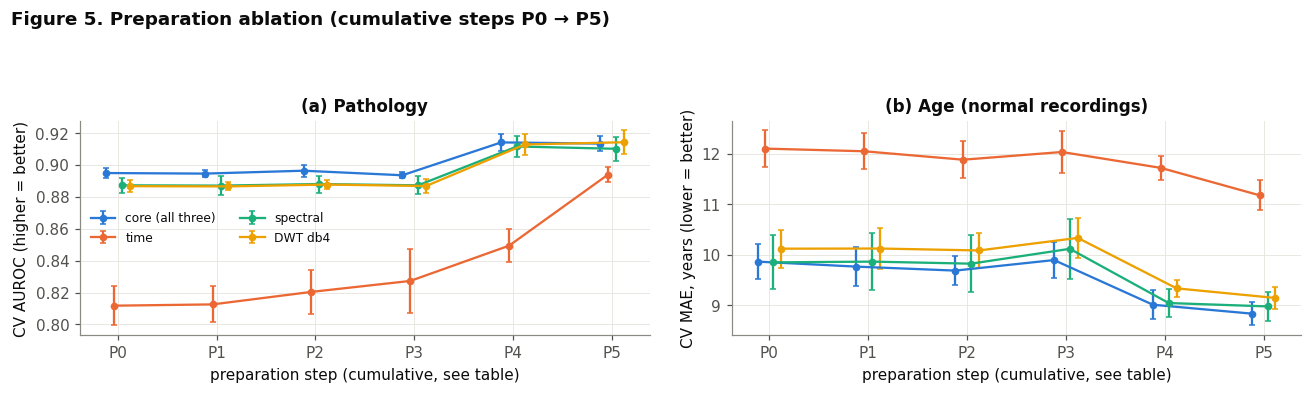

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
fam_order = ["time+spectral+dwt_db4", "time", "spectral", "dwt_db4"]
labels = {"time+spectral+dwt_db4": "core (all three)", "time": "time", "spectral": "spectral", "dwt_db4": "DWT db4"}
for ax, task, metric in [(axes[0], "abn", "cv_AUROC"), (axes[1], "age", "cv_MAE")]:
    for k, fam in enumerate(fam_order):
        d = ladder[(ladder.task == task) & (ladder.features == fam)]
        ax.errorbar(np.arange(len(d)) + (k - 1.5) * 0.08, d[metric], yerr=d[metric + "_sd"],
                    marker="o", ms=4, lw=1.5, capsize=2, color=PAL[k], label=labels[fam])
    ax.set_xticks(range(len(LADDER)), [n.split(" ")[0] for n, _ in LADDER])
    ax.set(xlabel="preparation step (cumulative, see table)",
           ylabel="CV AUROC (higher = better)" if task == "abn" else "CV MAE, years (lower = better)",
           title="Pathology" if task == "abn" else "Age (normal recordings)")
axes[0].legend(ncol=2, fontsize=8)
finish(fig, axes, 5, "Preparation ablation (cumulative steps P0 → P5)")

**Figure 5.** Cross-validated scores of the core features (all three families together and each alone) after each cumulative preparation step P0–P5 (table in §3.4). (a) Pathology AUROC. (b) Age MAE. Error bars: SD over the 5 folds.

### 3.5 How much recording is needed?
Reference preparation, aggregating only the first $n$ clean 10 s windows after the skip,
$\phi_r^{(n)} = \operatorname{median}\{\phi_{r,w} : w \in \mathcal W_r,\ \text{rank}(w) \le n\}$ (Fig. 6). With per-window noise
of variance $\sigma^2$, a mean estimate has standard error $\sigma/\sqrt n$ (≈ $1.25\,\sigma/\sqrt n$ for a median),
so returns diminish once that is small compared with the between-subject spread.

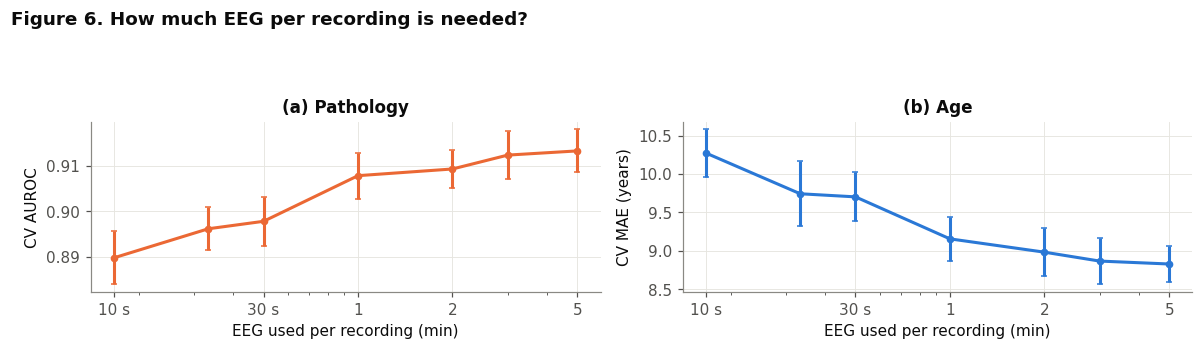

,cv_AUROC,cv_MAE
task,abn,age
windows,,
1,0.890,10.274
2,0.896,9.742
3,0.898,9.702
6,0.908,9.155
12,0.909,8.982
18,0.912,8.866
30,0.913,8.827


In [10]:
rows = []
for n in (1, 2, 3, 6, 12, 18, 30):
    X = core_matrix("1020_car_1-45Hz", n_windows=n)
    for task in ("abn", "age"):
        r, _, _ = evaluate(X, task, run_test=False)
        rows.append({"windows": n, "task": task, **r})
dur = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, task, metric, c in [(axes[0], "abn", "cv_AUROC", C_ABN), (axes[1], "age", "cv_MAE", C_NORMAL)]:
    d = dur[dur.task == task]
    ax.errorbar(d.windows * 10 / 60, d[metric], yerr=d[metric + "_sd"], marker="o", ms=4, capsize=2, color=c)
    ax.set(xscale="log", xlabel="EEG used per recording (min)",
           ylabel="CV AUROC" if task == "abn" else "CV MAE (years)",
           title="Pathology" if task == "abn" else "Age")
    ax.set_xticks([1 / 6, 0.5, 1, 2, 5], ["10 s", "30 s", "1", "2", "5"])
finish(fig, axes, 6, "How much EEG per recording is needed?")
display(dur.pivot(index="windows", columns="task", values=["cv_AUROC", "cv_MAE"]).dropna(axis=1).round(3))

**Figure 6.** Score vs amount of EEG per recording: the first $n$ clean 10 s windows after the skip, reference preparation, core features. (a) Pathology AUROC. (b) Age MAE (log x-axis). Error bars: SD over folds.

## 4. Visual analytics: how features relate to pathology and age
All features from here on use the **reference preparation** (P5) and are
recording-level medians. Fig. 7 shows spectra and DWT energies, and Fig. 8 the physiological
markers (peak alpha frequency, 1/f exponent $\chi$, multiscale PE; definitions in §1.6).

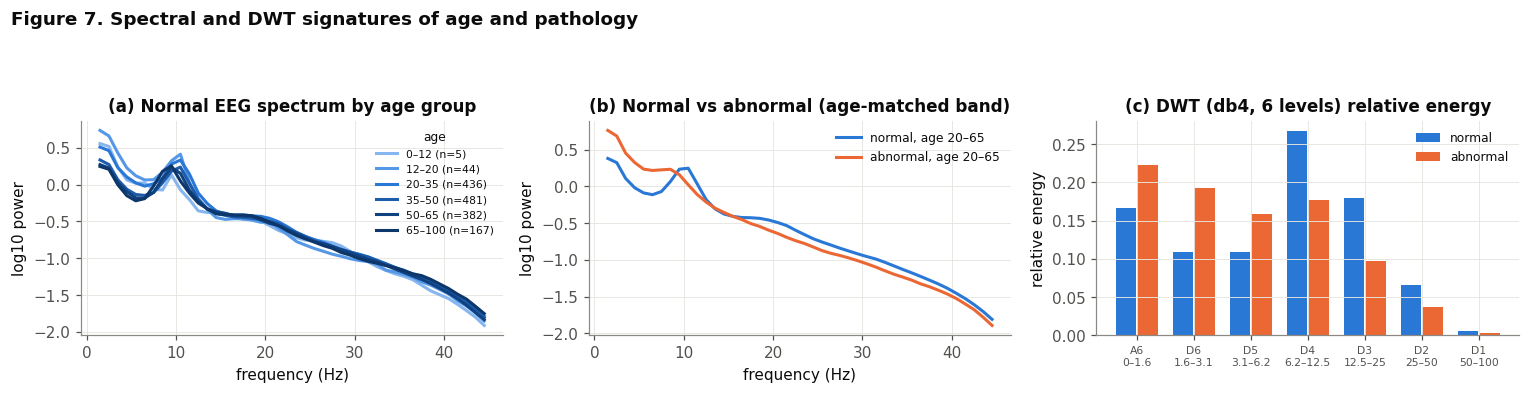

In [11]:
def rec(fam):
    return D[f"rec/{fam}"]  # [N, 19, F]

age_groups = pd.cut(meta.age, [0, 12, 20, 35, 50, 65, 100], right=False)
grp_labels = [f"{int(i.left)}–{int(i.right)}" for i in age_groups.cat.categories]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
f_bins = np.arange(1, 45)
psd = rec("psd_bins").mean(axis=1)  # channel-averaged log PSD, 1 Hz bins
for k, g in enumerate(age_groups.cat.categories):
    m = normal & (age_groups == g).to_numpy()
    if m.sum() < 5:
        continue
    axes[0].plot(f_bins + 0.5, np.median(psd[m], axis=0), color=SEQ[k], label=f"{grp_labels[k]} (n={m.sum()})")
axes[0].set(xlabel="frequency (Hz)", ylabel="log10 power", title="Normal EEG spectrum by age group")
axes[0].legend(fontsize=7, title="age", title_fontsize=8)
for lab, c in [("normal", C_NORMAL), ("abnormal", C_ABN)]:
    m = (meta.label == lab).to_numpy() & (age >= 20) & (age < 65)
    axes[1].plot(f_bins + 0.5, np.median(psd[m], axis=0), color=c, label=f"{lab}, age 20–65")
axes[1].set(xlabel="frequency (Hz)", ylabel="log10 power", title="Normal vs abnormal (age-matched band)")
axes[1].legend(fontsize=8)
# DWT relative energy per level
dn = NAMES["dwt_db4_L6"]
rel_idx = [i for i, n in enumerate(dn) if n.startswith("rel_E_")]
rel = rec("dwt_db4_L6")[..., rel_idx].mean(axis=1)
lev = [dn[i][len("rel_E_"):] for i in rel_idx]
w = 0.38
for k, (lab, c) in enumerate([("normal", C_NORMAL), ("abnormal", C_ABN)]):
    m = (meta.label == lab).to_numpy()
    axes[2].bar(np.arange(len(lev)) + (k - 0.5) * w, np.median(rel[m], axis=0), width=w * 0.95, color=c, label=lab)
axes[2].set_xticks(range(len(lev)), [f"{l}\n{lo:.1f}–{hi:.1f}".replace(".0", "") for l, (lo, hi) in zip(lev, fx.dwt_band_edges(6))], fontsize=7)
axes[2].set(ylabel="relative energy", title="DWT (db4, 6 levels) relative energy")
axes[2].legend(fontsize=8)
finish(fig, axes, 7, "Spectral and DWT signatures of age and pathology")

**Figure 7.** (a) Channel-averaged log power in 1 Hz bins of normal recordings, median per age group (darker = older). (b) Normal vs abnormal recordings, ages 20–65. (c) Median relative DWT-db4 energy $\rho_j$ per level, with nominal band edges in Hz.

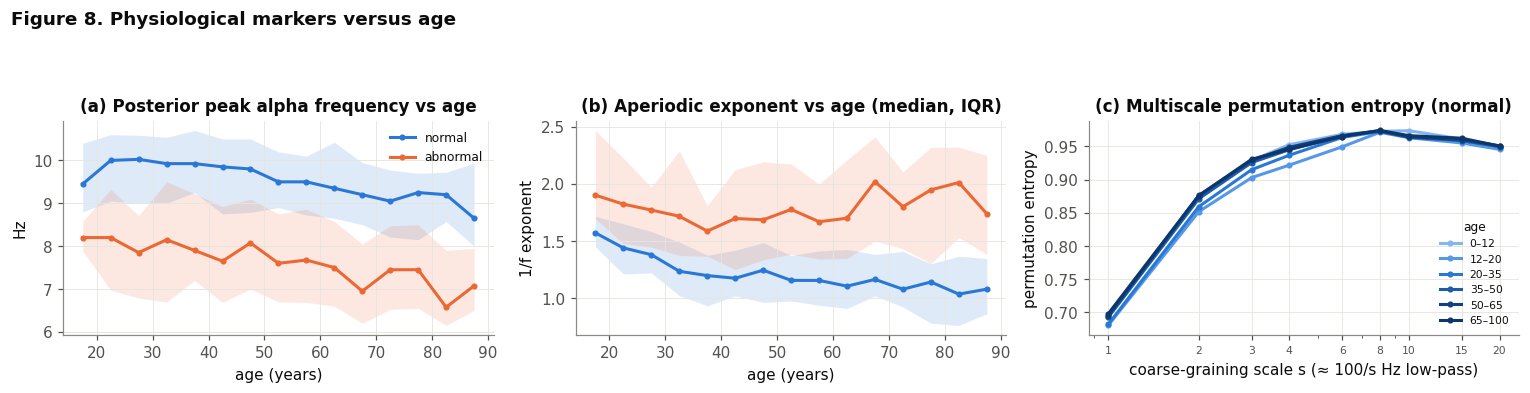

In [12]:
sn = NAMES["spectral"]
paf = rec("spectral")[..., sn.index("peak_alpha_freq")]
chi = rec("spectral")[..., sn.index("aperiodic_exponent")]
post = [CH.index(c) for c in ("O1", "O2", "P3", "P4", "PZ")]
mspe = rec("mspe").mean(axis=1)
scales = [int(n.split("_s")[1]) for n in NAMES["mspe"]]

def binned(ax, x, y, color, label):
    edges = np.arange(0, 95, 5)
    mids, med, lo, hi = [], [], [], []
    for a, b in zip(edges[:-1], edges[1:]):
        s = y[(x >= a) & (x < b)]
        if len(s) >= 10:
            mids.append((a + b) / 2); med.append(np.median(s)); lo.append(np.percentile(s, 25)); hi.append(np.percentile(s, 75))
    ax.fill_between(mids, lo, hi, color=color, alpha=0.15, lw=0)
    ax.plot(mids, med, color=color, marker="o", ms=3, label=label)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for lab, c in [("normal", C_NORMAL), ("abnormal", C_ABN)]:
    m = (meta.label == lab).to_numpy() & age_ok
    binned(axes[0], age[m], paf[m][:, post].mean(axis=1), c, lab)
    binned(axes[1], age[m], chi[m].mean(axis=1), c, lab)
axes[0].set(xlabel="age (years)", ylabel="Hz", title="Posterior peak alpha frequency vs age")
axes[1].set(xlabel="age (years)", ylabel="1/f exponent", title="Aperiodic exponent vs age (median, IQR)")
axes[0].legend(fontsize=8)
for k, g in enumerate(age_groups.cat.categories):
    m = normal & (age_groups == g).to_numpy()
    if m.sum() < 5:
        continue
    axes[2].plot(scales, np.median(mspe[m], axis=0), color=SEQ[k], marker="o", ms=3, label=grp_labels[k])
axes[2].set(xscale="log", xlabel="coarse-graining scale s (≈ 100/s Hz low-pass)", ylabel="permutation entropy",
            title="Multiscale permutation entropy (normal)")
axes[2].set_xticks(scales, scales, fontsize=7); axes[2].legend(fontsize=7, title="age", title_fontsize=8)
finish(fig, axes, 8, "Physiological markers versus age")

**Figure 8.** (a) Posterior (O1, O2, P3, P4, Pz) peak alpha frequency vs age: median (line) and IQR (band) in 5-year bins. (b) Channel-mean aperiodic exponent $\chi$ vs age. (c) Multiscale permutation entropy $\text{PE}_s$ vs coarse-graining scale $s$, by age group (normal recordings).

### 4.1 What the time–frequency decompositions look like
One 30 s excerpt from a normal and an abnormal adult test recording (O1, reference preparation)
is decomposed four ways and shown as heatmaps of log power (Fig. 9, colormap `magma`; columns
share a colour scale, so normal and abnormal are directly comparable). The four tilings differ
in how they trade time against frequency resolution:

| column | transform | time resolution | frequency resolution | tiling |
|---|---|---|---|---|
| (a, e) | STFT, 1 s Hann | $\Delta t = 1$ s | $\Delta f = 1$ Hz | fixed boxes |
| (b, f) | multitaper, 2 s, $NW = 2$, $K = 3$ | $\Delta t = 2$ s | $\pm1$ Hz, lower variance | fixed boxes |
| (c, g) | Morlet CWT, 5.4 cycles | $\sigma_t = \frac{5.4}{2\pi f}$ (0.86 s at 1 Hz, 0.09 s at 10 Hz) | $\sigma_f = f/5.4$ | constant-Q |
| (d, h) | DWT db4, 6 levels | $\Delta t_j = 2^j/f_s$ (0.32 s for D6, 0.01 s for D1) | one octave per level | dyadic |

All four obey the uncertainty bound $\sigma_t\sigma_f \ge 1/(4\pi)$. The STFT uses the same box everywhere;
the wavelets trade time for frequency resolution proportionally to $f$. In the DWT panel, every tile
is one coefficient $u_j[k]$: height = nominal band of level $j$, width = $2^j/f_s$, colour = $\log_{10}u_j[k]^2$.

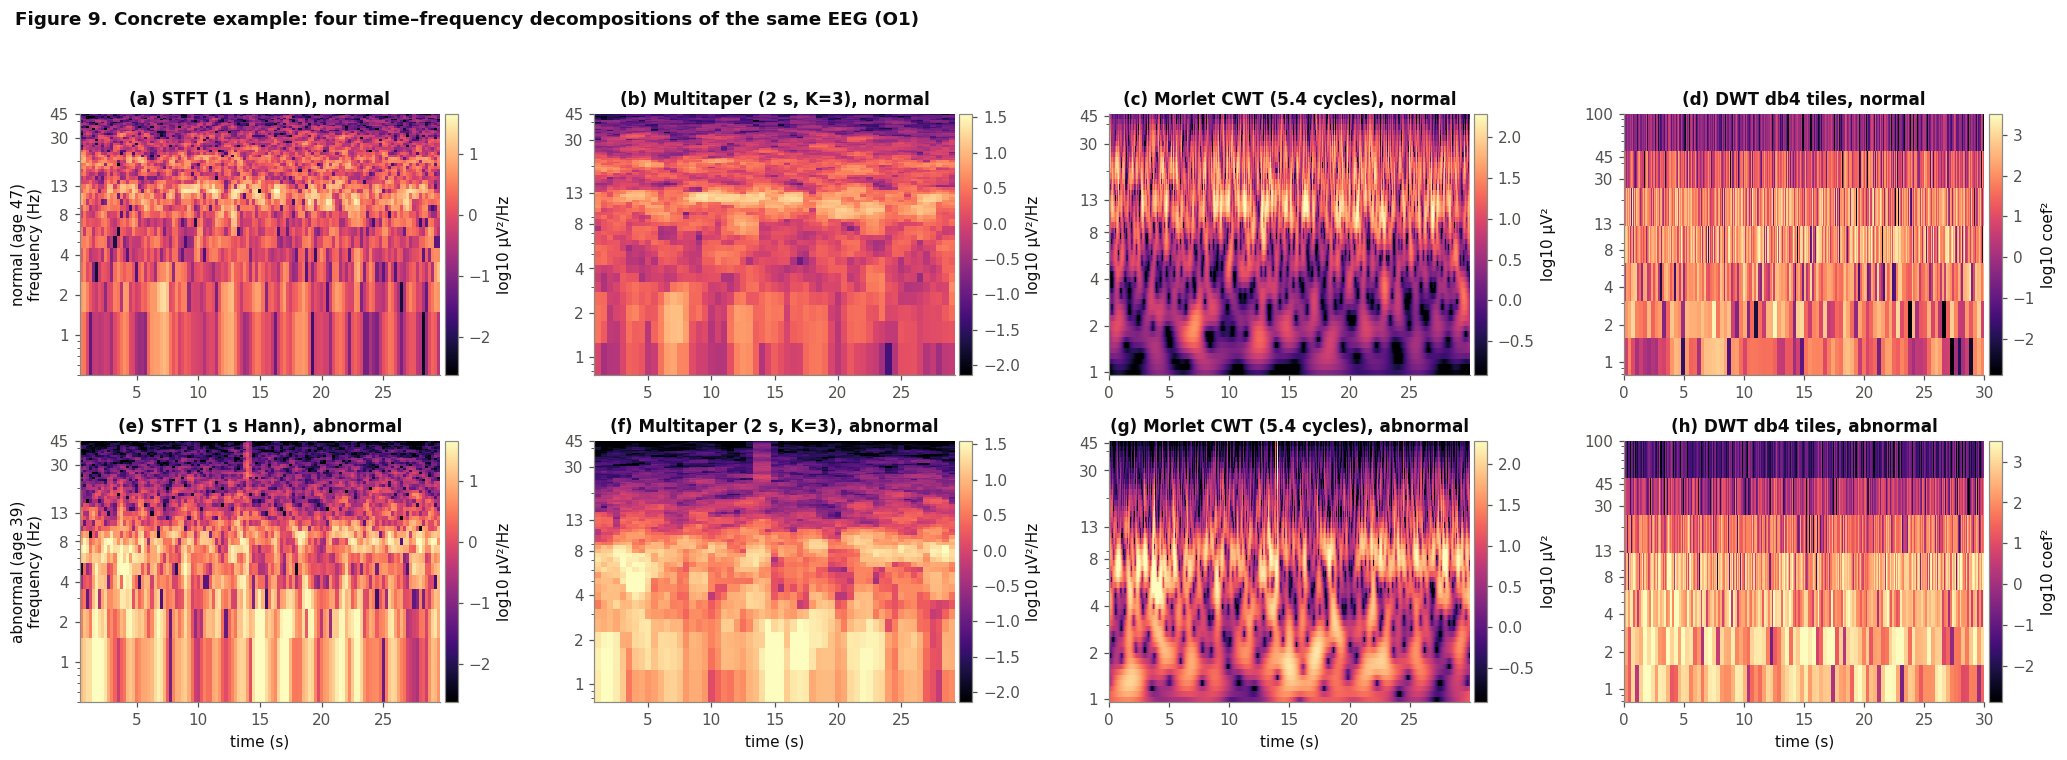

In [13]:
from matplotlib.colors import Normalize
from scipy import signal as sps

HEAT = "magma"
f_cwt = fx.cwt_frequencies(48, 1, 45)


def pick(label, lo=30, hi=50):
    m = (meta.label == label) & meta.age.between(lo, hi) & test
    return meta[m].iloc[0]


def tf_maps(x):
    # The four log-power maps of a 1-D signal (200 Hz): STFT, multitaper, Morlet, DWT tiles.
    f1, t1, s1 = sps.spectrogram(x, fs=200, window="hann", nperseg=200, noverlap=150)
    k1 = (f1 >= 1) & (f1 <= 45)
    tapers = sps.windows.dpss(400, 2.0, Kmax=3)
    sm = None
    for tp in tapers:
        f2, t2, s2 = sps.spectrogram(x, fs=200, window=tp, nperseg=400, noverlap=300)
        sm = s2 if sm is None else sm + s2
    k2 = (f2 >= 1) & (f2 <= 45)
    cw = fx.cwt_log_power(x[None], f_cwt)[:, 0]
    coeffs = pywt.wavedec(x, "db4", level=6, mode="periodization")
    return {"stft": (t1, f1[k1], np.log10(s1[k1] + 1e-12)),
            "mt": (t2, f2[k2], np.log10(sm[k2] / 3 + 1e-12)),
            "cwt": (np.arange(len(x)) / 200, f_cwt, cw),
            "dwt": coeffs}


examples = []
for lab in ["normal", "abnormal"]:
    r = pick(lab)
    seg = tuab.load_segment(os.path.join(NPY_ROOT, "recordings", r.stem + ".npy"), 12)
    x = tuab.prepare(seg, tuab.PREP_REF)[CH.index("O1"), 6 * 2000: 9 * 2000]
    examples.append((lab, r, tf_maps(x)))

# column-wise colour scales shared by both rows
def rng_of(key):
    vals = np.concatenate([(np.log10(np.concatenate([c ** 2 for c in m["dwt"][1:]]) + 1e-12) if key == "dwt"
                            else m[key][2].ravel()) for _, _, m in examples])
    return Normalize(np.percentile(vals, 3), np.percentile(vals, 99.7))
norms = {k: rng_of(k) for k in ("stft", "mt", "cwt", "dwt")}

fig, axes = plt.subplots(2, 4, figsize=(19, 7))
dwt_edges = [(200 / 2 ** 8, 200 / 2 ** 7)] + [(200 / 2 ** (j + 1), 200 / 2 ** j) for j in range(6, 0, -1)]
titles = {"stft": "STFT (1 s Hann)", "mt": "Multitaper (2 s, K=3)",
          "cwt": "Morlet CWT (5.4 cycles)", "dwt": "DWT db4 tiles"}
units = {"stft": "log10 µV²/Hz", "mt": "log10 µV²/Hz", "cwt": "log10 µV²", "dwt": "log10 coef²"}
for row, (lab, r, m) in enumerate(examples):
    for col, key in enumerate(("stft", "mt", "cwt", "dwt")):
        ax = axes[row, col]
        if key == "dwt":
            for (lo, hi), c in zip(dwt_edges, m["dwt"]):
                edges_t = np.linspace(0, 30, len(c) + 1)
                pcm = ax.pcolormesh(edges_t, [lo, hi], np.log10(c[None] ** 2 + 1e-12), cmap=HEAT, norm=norms[key])
            ax.set_ylim(dwt_edges[0][0], 100)
        else:
            t, f, z = m[key]
            pcm = ax.pcolormesh(t, f, z, shading="auto", cmap=HEAT, norm=norms[key])
        ax.set(yscale="log", title=f"{titles[key]}, {lab}")
        ticks = [1, 2, 4, 8, 13, 30, 45] + ([100] if key == "dwt" else [])
        ax.set_yticks(ticks, ticks); ax.grid(False)
        if col == 0:
            ax.set_ylabel(f"{lab} (age {r.age:.0f})\nfrequency (Hz)")
        if row == 1:
            ax.set_xlabel("time (s)")
        plt.colorbar(pcm, ax=ax, pad=0.01, label=units[key])
finish(fig, axes, 9, "Concrete example: four time–frequency decompositions of the same EEG (O1)")

**Figure 9.** The same 30 s of channel O1 from a normal (top, a–d) and an abnormal (bottom, e–h) adult test recording, reference preparation, as log-power heatmaps; each column shares one colour scale across both rows. (a, e) STFT spectrogram, 1 s Hann window (75 % overlap for display). (b, f) Multitaper spectrogram, 2 s DPSS tapers, $NW = 2$, $K = 3$. (c, g) Complex-Morlet scalogram, 5.4 cycles. (d, h) DWT-db4 tiling: each tile is one coefficient (height = nominal octave band, width = its time support $2^j/f_s$); the top tiles (D1, 50–100 Hz) are dark because the signal is band-limited to 45 Hz.

### 4.2 Univariate screening
Each (feature, channel) pair is scored on the development pool: Spearman ρ with age on normal
recordings, and AUROC for abnormal vs normal on all recordings. Below are the strongest
single features of each family, then a channel × feature map for the spectral family (Fig. 10).
* AUROC is the Mann–Whitney probability $\text{AUROC} = P(\phi^{+} > \phi^{-}) = \frac{U}{n^{+}n^{-}}$. Values below 0.5 mean the feature is *lower* in abnormal recordings.
* $\rho$ is Spearman's rank correlation with age.

In [14]:
FAMS_SCREEN = ["time", "spectral", "dwt_db4_L6", "wpd_db4_L5", "cwt_cmor1.5-1.0", "scat_J7_Q8", "mspe",
               "stft_dyn", "cepstral"]
rows = []
ia, ix = DEV["age"], DEV["abn"]
for fam in FAMS_SCREEN:
    arr = rec(fam)
    for j, fn in enumerate(NAMES[fam]):
        for c, ch in enumerate(CH):
            v = arr[:, c, j]
            ok_a, ok_x = np.isfinite(v[ia]), np.isfinite(v[ix])
            rho = stats.spearmanr(v[ia][ok_a], age[ia][ok_a])[0]
            auc = roc_auc_score(Y["abn"][ix][ok_x], v[ix][ok_x])
            rows.append({"family": fam, "feature": fn, "channel": ch, "rho_age": rho, "auroc_abn": auc})
uni = pd.DataFrame(rows)
uni["auc_dist"] = (uni.auroc_abn - 0.5).abs()
best = uni.loc[uni.groupby("family").rho_age.apply(lambda s: s.abs().idxmax())][["family", "feature", "channel", "rho_age"]]
best2 = uni.loc[uni.groupby("family").auc_dist.idxmax()][["family", "feature", "channel", "auroc_abn"]]
display(best.merge(best2, on="family", suffixes=("_age", "_abn")).round(3))
print("Top 12 single features for age:")
display(uni.reindex(uni.rho_age.abs().sort_values(ascending=False).index).head(12)[["family", "feature", "channel", "rho_age", "auroc_abn"]].round(3))
print("Top 12 single features for pathology:")
display(uni.sort_values("auc_dist", ascending=False).head(12)[["family", "feature", "channel", "auroc_abn", "rho_age"]].round(3))

,family,feature_age,channel_age,rho_age,feature_abn,channel_abn,auroc_abn
0,cepstral,cep_mean_c10,T6,0.342,cep_mean_c1,P4,0.806
1,cwt_cmor1.5-1.0,cwt_mean_2.2Hz,FZ,-0.421,cwt_mean_1.6Hz,T3,0.794
2,dwt_db4_L6,log_E_D6,FZ,-0.390,rel_E_D3,O2,0.173
3,mspe,mspe_s1,F3,0.215,mspe_s6,T3,0.198
4,scat_J7_Q8,S1_3.85Hz,CZ,-0.408,S1_1.62Hz,T3,0.790
5,spectral,log_abs_delta,CZ,-0.391,log_theta_alpha,T6,0.849
6,stft_dyn,std_logpow_gamma,F7,-0.202,ac1_logpow_alpha,PZ,0.285
7,time,zero_cross_rate,F4,0.258,hjorth_complexity,O2,0.815
8,wpd_db4_L5,log_E_wp_0-3.125Hz,CZ,-0.363,log_E_wp_0-3.125Hz,T3,0.788


Top 12 single features for age:


,family,feature,channel,rho_age,auroc_abn
1156,cwt_cmor1.5-1.0,cwt_mean_2.2Hz,FZ,-0.421,0.733
1175,cwt_cmor1.5-1.0,cwt_mean_2.6Hz,FZ,-0.419,0.729
1233,cwt_cmor1.5-1.0,cwt_mean_4.2Hz,CZ,-0.415,0.694
1137,cwt_cmor1.5-1.0,cwt_mean_1.9Hz,FZ,-0.414,0.735
1252,cwt_cmor1.5-1.0,cwt_mean_4.9Hz,CZ,-0.411,0.681
1194,cwt_cmor1.5-1.0,cwt_mean_3.0Hz,FZ,-0.410,0.729
2544,scat_J7_Q8,S1_3.85Hz,CZ,-0.408,0.700
1118,cwt_cmor1.5-1.0,cwt_mean_1.6Hz,FZ,-0.408,0.741
1176,cwt_cmor1.5-1.0,cwt_mean_2.6Hz,CZ,-0.407,0.708
1195,cwt_cmor1.5-1.0,cwt_mean_3.0Hz,CZ,-0.406,0.704


Top 12 single features for pathology:


,family,feature,channel,auroc_abn,rho_age
338,spectral,log_theta_alpha,T6,0.849,-0.030
357,spectral,log_slowing_ratio,T6,0.840,-0.102
332,spectral,log_theta_alpha,O2,0.838,0.041
351,spectral,log_slowing_ratio,O2,0.837,-0.009
337,spectral,log_theta_alpha,T5,0.833,-0.025
330,spectral,log_theta_alpha,P4,0.831,-0.058
356,spectral,log_slowing_ratio,T5,0.830,-0.106
331,spectral,log_theta_alpha,O1,0.829,0.031
350,spectral,log_slowing_ratio,O1,0.828,-0.036
325,spectral,log_theta_alpha,F3,0.827,-0.088


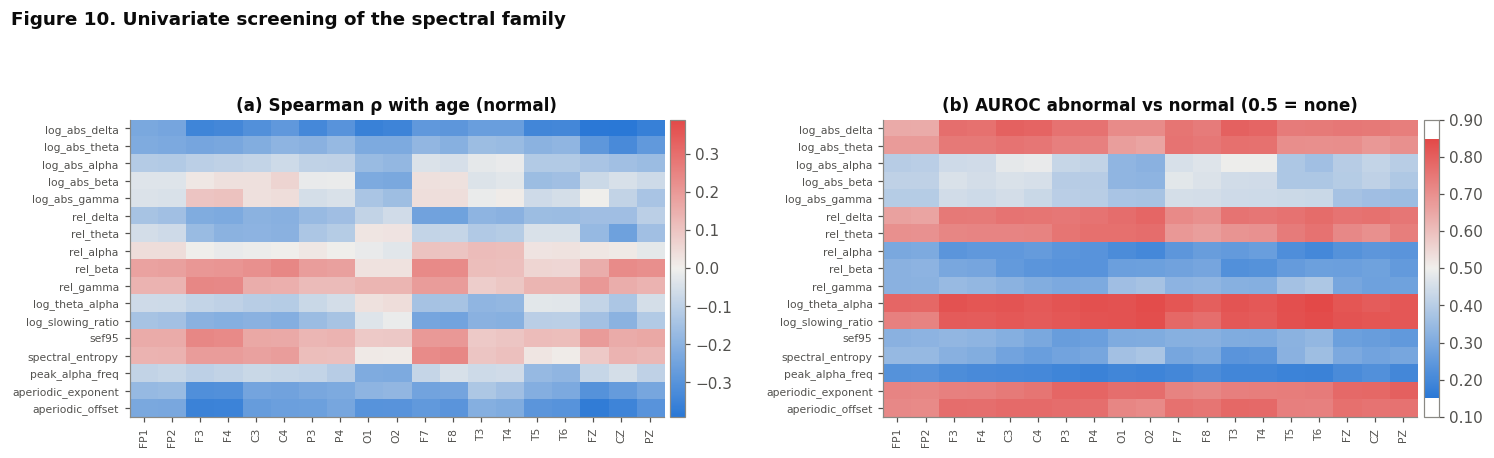

In [15]:
from matplotlib.colors import LinearSegmentedColormap
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
s = uni[uni.family == "spectral"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, col, title, lim in [(axes[0], "rho_age", "Spearman ρ with age (normal)", 0.6),
                            (axes[1], "auroc_abn", "AUROC abnormal vs normal (0.5 = none)", None)]:
    mat = s.pivot(index="feature", columns="channel", values=col).loc[NAMES["spectral"], CH]
    vals = mat.to_numpy() - (0.5 if col == "auroc_abn" else 0)
    lim = np.nanmax(np.abs(vals))
    im = ax.imshow(vals, cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(len(CH)), CH, fontsize=7, rotation=90); ax.set_yticks(range(len(mat)), mat.index, fontsize=7)
    ax.grid(False); ax.set_title(title)
    cb = plt.colorbar(im, ax=ax, pad=0.01)
    if col == "auroc_abn":
        cb.set_ticks(cb.get_ticks()); cb.set_ticklabels([f"{t + 0.5:.2f}" for t in cb.get_ticks()])
finish(fig, axes, 10, "Univariate screening of the spectral family")

**Figure 10.** Univariate association of each spectral feature (rows) on each channel (columns), development pool. (a) Spearman $\rho$ with age (normal recordings). (b) AUROC abnormal vs normal, centred on 0.5.

## 5. Benchmark: one model per feature family
Protocol:
* **Development pool** = TUAB `train` (both labels; 2,714 recordings). Subject-grouped, stratified **5-fold CV** gives mean ± SD across folds.
* **Held-out test** = the official TUAB `eval` set. The model is refit on the whole pool once and scored on test.
* **Age** models are trained on **normal** recordings. They are scored on held-out normal recordings (`test_*`) and, as a stress test, on held-out **abnormal** recordings (`test_abn_*`, which the model never saw in any form).
* **Per-class pathology metrics** at threshold 0.5: sensitivity $= TP/(TP+FN)$ (abnormal recall), specificity $= TN/(TN+FP)$ (normal recall), accuracy $= (TP+TN)/n$.
* **Models:** standardised **linear** models (L2 logistic regression with the C chosen by inner CV; RidgeCV) and **gradient-boosted trees** (`HistGradientBoosting`, fixed hyper-parameters; absolute-error loss for age).
* **Filterbank-Riemann:** six band covariances (1–4, 4–8, 8–13, 13–20, 20–30, 30–45 Hz), projected onto the 18-dim CAR subspace (CAR makes the 19×19 covariance rank 18), then mapped to the **tangent space at the training-fold Riemannian mean** (§1.6).

**Models.** Features $z_i$ are standardised with training-fold statistics.
* L2 logistic regression: $\min_w \sum_i\log\bigl(1+e^{-y_i w^\top z_i}\bigr) + \frac{1}{2C}\lVert w\rVert^2$, with $y_i \in \{\pm1\}$ and $C$ chosen by an inner 3-fold CV on AUROC.
* Ridge: $\min_w\lVert y - Zw\rVert^2 + \alpha\lVert w\rVert^2$, with $\alpha$ chosen by efficient leave-one-out.
* Gradient boosting: 300 trees with 15 leaves each, learning rate 0.05; the age model minimises $\sum_i\lvert y_i-\hat y_i\rvert$.

**Metrics.**
$$\text{AUROC} = P\bigl(\hat s(x^{+}) > \hat s(x^{-})\bigr), \qquad \text{BAcc} = \tfrac12\Bigl(\tfrac{TP}{TP+FN} + \tfrac{TN}{TN+FP}\Bigr), \qquad \text{MAE} = \tfrac1n\textstyle\sum_i\lvert\hat y_i - y_i\rvert, \qquad R^2 = 1 - \frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}$$
CV scores are reported as mean ± SD over the 5 folds (Fig. 11).

In [16]:
from scipy.linalg import null_space
from labram.features.riemann import mean_riemann, tangent_space

U_CAR = null_space(np.ones((1, len(CH))))  # 19 x 18 orthonormal basis orthogonal to the CAR null vector
NB = len(fx.FILTERBANK)


class FBTangentSpace(BaseEstimator, TransformerMixin):
    # Filter-bank covariances (flattened in the last n_bands*19*19 columns) -> tangent vectors.
    # The leading `n_passthrough` columns are passed through unchanged (for combined models).
    def __init__(self, n_passthrough=0, shrink=1e-3):
        self.n_passthrough, self.shrink = n_passthrough, shrink

    def _covs(self, X):
        C = X[:, self.n_passthrough:].reshape(len(X), NB, len(CH), len(CH))
        C = U_CAR.T @ C @ U_CAR  # project onto the 18-dim CAR subspace
        tr = np.trace(C, axis1=-2, axis2=-1)[..., None, None] / C.shape[-1]
        return (1 - self.shrink) * C + self.shrink * tr * np.eye(C.shape[-1])

    def fit(self, X, y=None):
        C = self._covs(X)
        self.refs_ = [mean_riemann(C[:, b]) for b in range(NB)]
        return self

    def transform(self, X):
        C = self._covs(X)
        ts = [tangent_space(C[:, b], self.refs_[b]) for b in range(NB)]
        return np.concatenate([X[:, : self.n_passthrough]] + ts, axis=1)


X_FB = D["fbcov"].reshape(N, -1).astype(np.float64)


def Xrec(*fams):
    return nan_to_median(np.concatenate([rec(f).reshape(N, -1) for f in fams], axis=1))


FAMILIES = {
    "Time (Hjorth, line length, moments)": ("time",),
    "Spectral (bands, ratios, PAF, 1/f)": ("spectral",),
    "Log-PSD, 1 Hz bins": ("psd_bins",),
    "DWT db4, 6 levels": ("dwt_db4_L6",),
    "WPD db4, 3.125 Hz nodes": ("wpd_db4_L5",),
    "CWT Morlet (mean+std over time)": ("cwt_cmor1.5-1.0",),
    "Wavelet scattering (orders 1+2)": ("scat_J7_Q8",),
    "STFT spectrogram (mean+std over time)": ("stft",),
    "Multitaper spectrogram (mean+std)": ("multitaper",),
    "Spectrogram dynamics (variability, flux)": ("stft_dyn",),
    "Cepstral coefficients (MFCC-style)": ("cepstral",),
    "Multiscale permutation entropy": ("mspe",),
    "Filterbank Riemann (tangent space)": "riemann",
}
ALL_FLAT = ("time", "spectral", "psd_bins", "dwt_db4_L6", "wpd_db4_L5", "cwt_cmor1.5-1.0", "scat_J7_Q8", "mspe",
            "stft", "stft_dyn", "cepstral")

In [17]:
def n_features(X, pre):
    # Tangent space of an 18x18 SPD matrix has 18*19/2 = 171 coordinates per band.
    if pre is None:
        return X.shape[1]
    return pre.n_passthrough + NB * 171


bench, PRED = [], {}
t0 = time.time()
for name, fams in list(FAMILIES.items()) + [("All families combined", "all")]:
    if fams == "riemann":
        X, pre = X_FB, FBTangentSpace()
    elif fams == "all":
        Xf = Xrec(*ALL_FLAT)
        X, pre = np.concatenate([Xf, X_FB], axis=1), FBTangentSpace(n_passthrough=Xf.shape[1])
    else:
        X, pre = Xrec(*fams), None
    for kind in ("linear", "hgb"):
        for task in ("abn", "age"):
            r, oof, tp = evaluate(X, task, kind, pre=pre)
            PRED[(name, kind, task)] = (oof, tp)
            bench.append({"family": name, "model": kind, "task": task, "n_features": n_features(X, pre), **r})
    print(f"{name:42s} done ({time.time() - t0:.0f}s)")

# baselines
demo = np.c_[np.nan_to_num(age, nan=np.nanmedian(age)), (meta.sex == "F").astype(float)]
for kind in ("linear", "hgb"):
    r, oof_b, tp_b = evaluate(demo, "abn", kind)
    PRED[("Baseline: age + sex only", kind, "abn")] = (oof_b, tp_b)
    bench.append({"family": "Baseline: age + sex only", "model": kind, "task": "abn", "n_features": 2, **r})
dummy_cv = [mean_absolute_error(Y["age"][DEV["age"]][va], np.full(len(va), np.median(Y["age"][DEV["age"]][tr]))) for tr, va in FOLDS["age"]]
bench.append({"family": "Baseline: predict median age", "model": "dummy", "task": "age", "n_features": 0,
              "cv_MAE": np.mean(dummy_cv), "cv_MAE_sd": np.std(dummy_cv),
              "test_MAE": mean_absolute_error(Y["age"][TEST["age"]], np.full(len(TEST["age"]), np.median(Y["age"][DEV["age"]]))),
              "test_R2": 0.0})
bench = pd.DataFrame(bench)

Time (Hjorth, line length, moments)        done (14s)


Spectral (bands, ratios, PAF, 1/f)         done (38s)


Log-PSD, 1 Hz bins                         done (118s)


DWT db4, 6 levels                          done (149s)


WPD db4, 3.125 Hz nodes                    done (181s)


...

Spectrogram dynamics (variability, flux)   done (1042s)


Cepstral coefficients (MFCC-style)         done (1077s)


Multiscale permutation entropy             done (1093s)


Filterbank Riemann (tangent space)         done (1304s)


All families combined                      done (2261s)


In [18]:
cols_abn = ["family", "model", "n_features", "cv_AUROC", "cv_AUROC_sd", "cv_BAcc", "cv_Sens", "cv_Spec",
            "test_AUROC", "test_BAcc", "test_Acc", "test_Sens", "test_Spec"]
cols_age = ["family", "model", "n_features", "cv_MAE", "cv_MAE_sd", "cv_R2", "test_MAE", "test_R2", "test_bias",
            "test_abn_MAE", "test_abn_R2", "test_abn_bias"]
print("Pathology (abnormal vs normal) - sorted by CV AUROC. Sens = recall of abnormal, Spec = recall of normal (threshold 0.5)")
display(bench[bench.task == "abn"][cols_abn].sort_values("cv_AUROC", ascending=False).round(3).reset_index(drop=True))
print("Age - models trained on normal recordings, sorted by CV MAE (years). test_* = held-out normal, "
      "test_abn_* = held-out abnormal; bias = mean(predicted - true)")
display(bench[bench.task == "age"][cols_age].sort_values("cv_MAE").round(3).reset_index(drop=True))

Pathology (abnormal vs normal) - sorted by CV AUROC. Sens = recall of abnormal, Spec = recall of normal (threshold 0.5)


,family,model,n_features,cv_AUROC,cv_AUROC_sd,cv_BAcc,cv_Sens,cv_Spec,test_AUROC,test_BAcc,test_Acc,test_Sens,test_Spec
0,All families combined,hgb,9728,0.926,0.006,0.846,0.808,0.885,0.930,0.838,0.844,0.770,0.907
1,All families combined,linear,9728,0.922,0.005,0.851,0.810,0.891,0.922,0.824,0.830,0.762,0.887
2,Filterbank Riemann (tangent space),linear,1026,0.922,0.007,0.844,0.811,0.876,0.918,0.831,0.837,0.762,0.900
3,Filterbank Riemann (tangent space),hgb,1026,0.918,0.003,0.842,0.803,0.882,0.917,0.843,0.848,0.786,0.900
4,"DWT db4, 6 levels",hgb,285,0.917,0.009,0.839,0.803,0.876,0.921,0.836,0.841,0.778,0.893
5,"DWT db4, 6 levels",linear,285,0.914,0.007,0.835,0.791,0.879,0.896,0.810,0.815,0.754,0.867
6,CWT Morlet (mean+std over time),hgb,950,0.914,0.006,0.831,0.792,0.871,0.925,0.829,0.833,0.778,0.880
7,"Spectral (bands, ratios, PAF, 1/f)",hgb,323,0.914,0.007,0.833,0.803,0.864,0.924,0.814,0.819,0.754,0.873
8,Multitaper spectrogram (mean+std),hgb,1672,0.914,0.007,0.839,0.800,0.878,0.920,0.833,0.837,0.786,0.880
9,"Spectral (bands, ratios, PAF, 1/f)",linear,323,0.910,0.007,0.830,0.794,0.867,0.899,0.818,0.822,0.762,0.873


Age - models trained on normal recordings, sorted by CV MAE (years). test_* = held-out normal, test_abn_* = held-out abnormal; bias = mean(predicted - true)


,family,model,n_features,cv_MAE,cv_MAE_sd,cv_R2,test_MAE,test_R2,test_bias,test_abn_MAE,test_abn_R2,test_abn_bias
0,All families combined,linear,9728,7.869,0.387,0.580,7.209,0.657,-1.080,12.668,0.072,-7.576
1,Filterbank Riemann (tangent space),linear,1026,8.223,0.353,0.560,7.582,0.640,-0.943,12.424,0.190,-6.936
2,"Log-PSD, 1 Hz bins",linear,836,8.476,0.291,0.533,7.623,0.634,-0.587,14.964,-0.177,-7.856
3,Multitaper spectrogram (mean+std),linear,1672,8.915,0.453,0.485,7.995,0.598,-0.271,15.451,-0.296,-9.785
4,"Spectral (bands, ratios, PAF, 1/f)",linear,323,8.971,0.296,0.483,8.368,0.584,-0.357,14.269,-0.131,-7.214
5,"WPD db4, 3.125 Hz nodes",linear,304,9.054,0.195,0.484,8.439,0.572,0.101,15.103,-0.243,-8.543
6,CWT Morlet (mean+std over time),linear,950,9.066,0.478,0.465,8.296,0.554,-0.647,17.389,-0.593,-12.201
7,Cepstral coefficients (MFCC-style),linear,494,9.133,0.529,0.460,8.342,0.586,-0.420,16.161,-0.424,-11.209
8,"DWT db4, 6 levels",linear,285,9.139,0.216,0.467,8.470,0.566,-0.494,15.475,-0.862,-5.876
9,STFT spectrogram (mean+std over time),linear,1672,9.194,0.323,0.456,8.518,0.527,-0.605,16.473,-0.421,-10.734


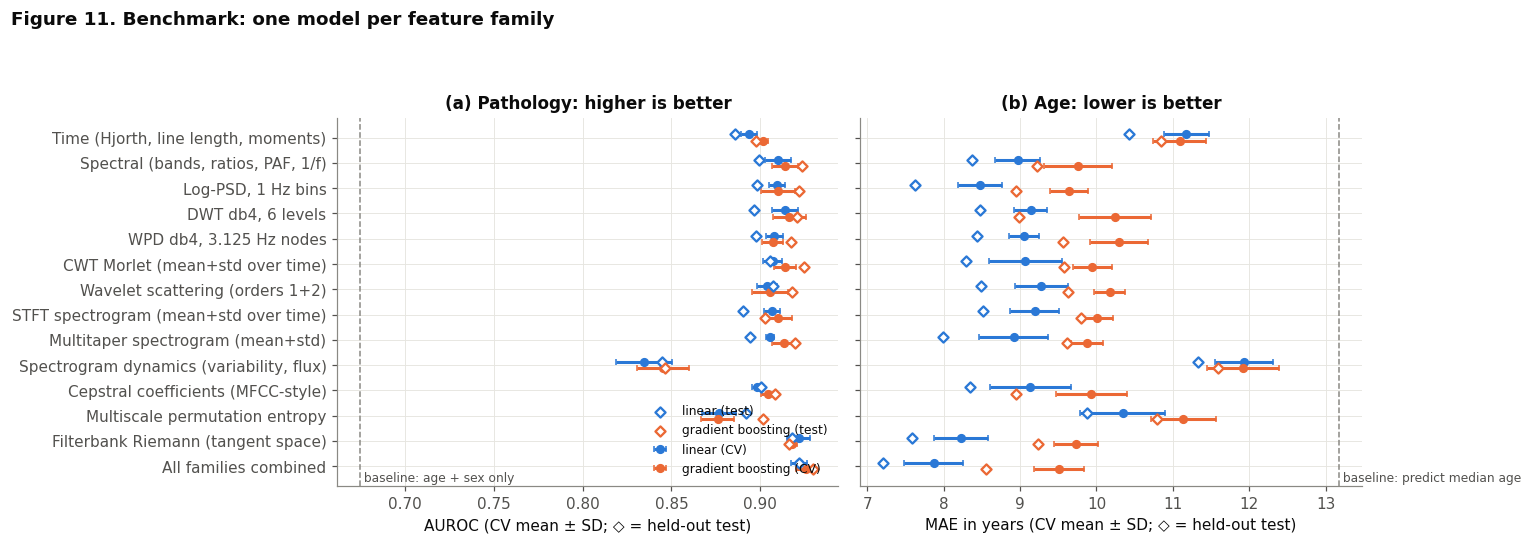

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
order = list(FAMILIES) + ["All families combined"]
yy = np.arange(len(order))
for ax, task, metric, ref in [(axes[0], "abn", "cv_AUROC", None), (axes[1], "age", "cv_MAE", None)]:
    for k, (kind, c) in enumerate([("linear", PAL[0]), ("hgb", PAL[1])]):
        d = bench[(bench.task == task) & (bench.model == kind)].set_index("family").reindex(order)
        ax.errorbar(d[metric], yy + (k - 0.5) * 0.25, xerr=d[metric + "_sd"], fmt="o", ms=5, capsize=2,
                    color=c, label={"linear": "linear (CV)", "hgb": "gradient boosting (CV)"}[kind])
        ax.scatter(d["test_" + metric[3:]], yy + (k - 0.5) * 0.25, marker="D", s=22, facecolor="white",
                   edgecolor=c, linewidth=1.5, zorder=3, label={"linear": "linear (test)", "hgb": "gradient boosting (test)"}[kind])
    base = bench[(bench.task == task) & bench.family.str.startswith("Baseline")]
    bval = base[metric].max() if task == "abn" else base[metric].min()
    ax.axvline(bval, color="#8a8984", ls="--", lw=1)
    ax.text(bval, len(order) - 0.4, " " + base.sort_values(metric).family.iloc[-1 if task == "abn" else 0].replace("Baseline: ", "baseline: "),
            fontsize=8, color="#52514e")
    ax.set_yticks(yy, order)
    ax.set(xlabel="AUROC (CV mean ± SD; ◇ = held-out test)" if task == "abn" else "MAE in years (CV mean ± SD; ◇ = held-out test)",
           title="Pathology: higher is better" if task == "abn" else "Age: lower is better")
axes[0].invert_yaxis(); axes[0].legend(fontsize=8, loc="lower right")
finish(fig, axes, 11, "Benchmark: one model per feature family")

**Figure 11.** Filled markers: CV mean ± SD over 5 folds; open diamonds: held-out test. Blue: linear models; orange: gradient boosting. (a) Pathology AUROC. (b) Age MAE (years). The dashed line is the best baseline.

### 5.1 Comparison with published TUAB results
The published numbers below were checked against the source papers (table or text cited in the
*where* column). They are **not** strictly comparable to each other or to this notebook:
* **Unit of evaluation.** *Recording*-level metrics (one decision per EEG, as here, Gemein 2020 and Schirrmeister 2017) are easier than *window*-level metrics (one decision per 10 s sample, as in BIOT, LaBraM and CBraMod).
* **Corpus version.** v1.1.2, v2.0.0 and v3.0.0 contain mostly the same recordings but are not identical.
* **Validation.** The pathology results use the official TUAB eval set as the test set. Engemann 2022 uses 10-fold CV on 1,385 normal subjects; this notebook uses subject-grouped 5-fold CV on 1,366 normal recordings plus the official eval set.

Our rows are filled in from the benchmark above.

In [20]:
pub_abn = pd.DataFrame([
    # study, model, corpus, unit, Acc, BAcc, Sens, Spec, AUROC, where
    ("Lopez de Diego 2017 (via Schirrmeister 2017)", "cepstral coef. + CNN-MLP", "v1.1.2", "recording", 0.788, np.nan, 0.754, 0.819, np.nan, "Schirrmeister 2017, Table II"),
    ("Schirrmeister et al. 2017", "Deep4 ConvNet", "v1.1.2", "recording", 0.854, np.nan, 0.751, 0.941, np.nan, "Table II"),
    ("Schirrmeister et al. 2017", "Shallow ConvNet", "v1.1.2", "recording", 0.845, np.nan, 0.773, 0.905, np.nan, "Table II"),
    ("Gemein et al. 2020", "Riemannian (RG), features", "v2.0.0", "recording", 0.8587, np.nan, np.nan, np.nan, np.nan, "Fig. 6 / text"),
    ("Gemein et al. 2020", "auto-sklearn (ASC), features", "v2.0.0", "recording", 0.8471, np.nan, np.nan, np.nan, np.nan, "Fig. 6"),
    ("Gemein et al. 2020", "Random forest, features", "v2.0.0", "recording", 0.8406, np.nan, np.nan, np.nan, np.nan, "Fig. 6"),
    ("Gemein et al. 2020", "SVM, features", "v2.0.0", "recording", 0.8080, np.nan, np.nan, np.nan, np.nan, "Fig. 6"),
    ("Gemein et al. 2020", "BD-TCN", "v2.0.0", "recording", 0.8616, np.nan, np.nan, np.nan, np.nan, "Fig. 6"),
    ("Gemein et al. 2020", "BD-Deep4", "v2.0.0", "recording", 0.8457, np.nan, np.nan, np.nan, np.nan, "Fig. 6"),
    ("Roy et al. 2019 (as quoted by Gemein 2020)", "ChronoNet (RNN)", "TUAB", "recording", 0.8657, np.nan, np.nan, np.nan, np.nan, "Gemein 2020, Discussion"),
    ("Yang et al. 2023 (BIOT)", "BIOT", "official split", "10 s window", np.nan, 0.7959, np.nan, np.nan, 0.8815, "LaBraM Table 1"),
    ("Jiang et al. 2024 (LaBraM)", "LaBraM-Base", "official split", "10 s window", np.nan, 0.8140, np.nan, np.nan, 0.9022, "Table 1"),
    ("Jiang et al. 2024 (LaBraM)", "LaBraM-Huge", "official split", "10 s window", np.nan, 0.8258, np.nan, np.nan, 0.9162, "Table 1"),
    ("Wang et al. 2025 (CBraMod)", "CBraMod", "official split", "10 s window", np.nan, 0.8289, np.nan, np.nan, 0.9227, "Table 14"),
    ("Wang et al. 2025 (CBraMod)", "CBraMod (pre-trained without TUAB)", "official split", "10 s window", np.nan, 0.8249, np.nan, np.nan, 0.9156, "Table 14"),
], columns=["study", "model", "corpus", "unit", "Acc", "BAcc", "Sens", "Spec", "AUROC", "where"])

ours = []
for fam, kind in [("All families combined", "hgb"), ("Filterbank Riemann (tangent space)", "linear"),
                  ("Spectral (bands, ratios, PAF, 1/f)", "linear")]:
    r = bench[(bench.family == fam) & (bench.model == kind) & (bench.task == "abn")].iloc[0]
    ours.append(("This notebook (held-out eval set)", f"{fam} / {kind}", "v3.0.0", "recording",
                 r.test_Acc, r.test_BAcc, r.test_Sens, r.test_Spec, r.test_AUROC, "§5"))
pub_abn = pd.concat([pub_abn, pd.DataFrame(ours, columns=pub_abn.columns)], ignore_index=True)
print("Pathology: published results vs this notebook")
display(pub_abn.style.format({c: "{:.3f}" for c in ["Acc", "BAcc", "Sens", "Spec", "AUROC"]}, na_rep="–"))

eng = [("Engemann et al. 2022", m, mae, sd, r2) for m, mae, sd, r2 in [
    ("dummy (median age)", 13.55, 0.82, -0.01), ("handcrafted features", 10.75, 0.64, 0.33),
    ("filterbank Riemann", 8.25, 0.41, 0.56), ("filterbank source", 8.43, 0.57, 0.56),
    ("ShallowNet", 7.80, 0.41, 0.61), ("Deep4", 7.75, 0.56, 0.60)]]
pub_age = pd.DataFrame(eng, columns=["study", "model", "MAE", "MAE_sd", "R2"])
pub_age["protocol"] = "TUAB normal, 1,385 subjects, 10-fold CV"
ours = []
for fam, kind in [("Baseline: predict median age", "dummy"), ("Filterbank Riemann (tangent space)", "linear"),
                  ("All families combined", "linear"), ("Log-PSD, 1 Hz bins", "linear")]:
    r = bench[(bench.family == fam) & (bench.model == kind) & (bench.task == "age")].iloc[0]
    ours.append(("This notebook", f"{fam} / {kind}", r.cv_MAE, r.cv_MAE_sd, r.get("cv_R2", np.nan),
                 f"TUAB v3.0.0 normal, {len(DEV['age'])} recordings, grouped 5-fold CV (test MAE {r.test_MAE:.2f})"))
pub_age = pd.concat([pub_age, pd.DataFrame(ours, columns=pub_age.columns)], ignore_index=True)
print("Age (normal recordings): published results vs this notebook")
display(pub_age.style.format({"MAE": "{:.2f}", "MAE_sd": "{:.2f}", "R2": "{:.2f}"}, na_rep="–"))

Pathology: published results vs this notebook


,study,model,corpus,unit,Acc,BAcc,Sens,Spec,AUROC,where
0,Lopez de Diego 2017 (via Schirrmeister 2017),cepstral coef. + CNN-MLP,v1.1.2,recording,0.788,–,0.754,0.819,–,"Schirrmeister 2017, Table II"
1,Schirrmeister et al. 2017,Deep4 ConvNet,v1.1.2,recording,0.854,–,0.751,0.941,–,Table II
2,Schirrmeister et al. 2017,Shallow ConvNet,v1.1.2,recording,0.845,–,0.773,0.905,–,Table II
3,Gemein et al. 2020,"Riemannian (RG), features",v2.0.0,recording,0.859,–,–,–,–,Fig. 6 / text
4,Gemein et al. 2020,"auto-sklearn (ASC), features",v2.0.0,recording,0.847,–,–,–,–,Fig. 6
5,Gemein et al. 2020,"Random forest, features",v2.0.0,recording,0.841,–,–,–,–,Fig. 6
6,Gemein et al. 2020,"SVM, features",v2.0.0,recording,0.808,–,–,–,–,Fig. 6
7,Gemein et al. 2020,BD-TCN,v2.0.0,recording,0.862,–,–,–,–,Fig. 6
8,Gemein et al. 2020,BD-Deep4,v2.0.0,recording,0.846,–,–,–,–,Fig. 6
9,Roy et al. 2019 (as quoted by Gemein 2020),ChronoNet (RNN),TUAB,recording,0.866,–,–,–,–,"Gemein 2020, Discussion"


Age (normal recordings): published results vs this notebook


,study,model,MAE,MAE_sd,R2,protocol
0,Engemann et al. 2022,dummy (median age),13.55,0.82,-0.01,"TUAB normal, 1,385 subjects, 10-fold CV"
1,Engemann et al. 2022,handcrafted features,10.75,0.64,0.33,"TUAB normal, 1,385 subjects, 10-fold CV"
2,Engemann et al. 2022,filterbank Riemann,8.25,0.41,0.56,"TUAB normal, 1,385 subjects, 10-fold CV"
3,Engemann et al. 2022,filterbank source,8.43,0.57,0.56,"TUAB normal, 1,385 subjects, 10-fold CV"
4,Engemann et al. 2022,ShallowNet,7.80,0.41,0.61,"TUAB normal, 1,385 subjects, 10-fold CV"
5,Engemann et al. 2022,Deep4,7.75,0.56,0.60,"TUAB normal, 1,385 subjects, 10-fold CV"
6,This notebook,Baseline: predict median age / dummy,13.17,0.22,–,"TUAB v3.0.0 normal, 1366 recordings, grouped 5-fold CV (test MAE 13.69)"
7,This notebook,Filterbank Riemann (tangent space) / linear,8.22,0.35,0.56,"TUAB v3.0.0 normal, 1366 recordings, grouped 5-fold CV (test MAE 7.58)"
8,This notebook,All families combined / linear,7.87,0.39,0.58,"TUAB v3.0.0 normal, 1366 recordings, grouped 5-fold CV (test MAE 7.21)"
9,This notebook,"Log-PSD, 1 Hz bins / linear",8.48,0.29,0.53,"TUAB v3.0.0 normal, 1366 recordings, grouped 5-fold CV (test MAE 7.62)"


#### Compact comparison: age prediction on TUAB normal recordings (MAE in years, lower is better)
All rows use the same corpus. Ours: subject-grouped 5-fold CV on 1,366 normal recordings plus the held-out eval set (149). Engemann et al. 2022: 10-fold CV on 1,385 normal subjects. Rows are sorted by CV MAE, and only results with MAE < 9 y are shown.

| Rank | Source | Method | Category | Features (details) | Model | CV MAE | Test MAE |
|---|---|---|---|---|---|---|---|
| 1 | Engemann 2022 | Deep4Net | deep CNN, end-to-end | raw 21-ch EEG, cropped decoding | CNN, L1 loss | **7.75 ± 0.56** | – |
| 2 | Engemann 2022 | ShallowFBCSPNet | deep CNN, end-to-end | raw 21-ch EEG, cropped decoding | CNN, L1 loss | 7.80 ± 0.41 | – |
| 3 | **ours** | All 12 families combined | multi-family | time, Welch, DWT, WPD, CWT, scattering, STFT, dynamics, cepstra, MSPE, Riemann (9,728) | Ridge | **7.87 ± 0.39** | **7.21** |
| 4 | **ours** | Filterbank Riemann | spatial covariance | 6 bands 1–45 Hz, CAR → 18-dim, tangent space (1,026) | Ridge | 8.22 ± 0.35 | 7.58 |
| 5 | Engemann 2022 | Filterbank Riemann | spatial covariance | 7 bands 0.1–49 Hz, rank-20 projection, tangent space | Ridge | 8.25 ± 0.41 | – |
| 6 | **ours** | Multitaper spectrogram | spectrogram | DPSS 2 s, NW = 2, K = 3; mean log-power, 1 Hz bins (836) | Ridge | 8.43 | 7.84 |
| 7 | Engemann 2022 | Filterbank source power | source space | MNE source power, 7 bands, log-diagonal | Ridge | 8.43 ± 0.57 | – |
| 8 | **ours** | Welch log-PSD | Fourier spectrum | 2 s Hann, 1 Hz bins 1–45 Hz (836) | Ridge | 8.48 ± 0.29 | 7.62 |
| 9 | **ours** | Scattering, order 1 | wavelet scattering | Morlet, J = 7, Q = 8 (874) | Ridge | 8.49 | 7.51 |
| 10 | **ours** | STFT spectrogram | spectrogram | 1 s Hann; mean log-power, 1 Hz bins (836) | Ridge | 8.50 | 7.92 |
| 11 | **ours** | Cepstral coefficients | cepstrum | 16 mel-like filters, DCT c₀–c₁₂ (247) | Ridge | 8.53 | 7.96 |
| 12 | **ours** | Morlet CWT | continuous wavelet | cmor5.0-1.0 (9.9 cycles), 25 frequencies; mean log-power (475) | Ridge | 8.67 | 7.71 |
| 13 | **ours** | DWT db8 | discrete wavelet | 6 levels; log/relative energy + wavelet entropy (285) | Ridge | 8.96 | 8.30 |
| 14 | **ours** | Welch band features | clinical bands | δ–γ abs/rel power, ratios, SEF, PAF, 1/f (323) | Ridge | 8.97 ± 0.30 | 8.37 |

*Context from other datasets (not comparable: different populations, age ranges and recording types):*
* Sun et al. 2019: sleep-EEG features, 2,621 MGH patients, MAE 8.1 y.
* Khayretdinova et al. 2022: CNN on resting EEG, TD-BRAIN, MAE 5.96 y in CV.
* Brink-Kjaer et al. 2022: deep network on polysomnograms, 10,699 test PSGs, MAE 5.8 ± 1.6 y.

**Sources** (checked against the papers): Schirrmeister et al. 2017, Table II
([arXiv:1708.08012](https://arxiv.org/abs/1708.08012)); Gemein et al. 2020, Fig. 6 and §3–4
([arXiv:2002.05115](https://arxiv.org/abs/2002.05115), *NeuroImage* 220:117021); Jiang et al. 2024
(LaBraM), Table 1 ([arXiv:2405.18765](https://arxiv.org/abs/2405.18765)); Wang et al. 2025 (CBraMod),
Table 14 ([arXiv:2412.07236](https://arxiv.org/abs/2412.07236)). The CBraMod authors also notch at 60 Hz. The
Engemann et al. 2022 age numbers (*NeuroImage* 262:119521) come from the result files of their public
benchmark repository (`results/benchmark-*_dataset-tuab.csv`): 10 folds, mean ± SD. Model details (bands, RidgeCV, braindecode Deep4/Shallow with L1 loss) are from the same repository's code. Other-dataset age results: Sun et al. 2019 ([arXiv:1805.06391](https://arxiv.org/abs/1805.06391)), Khayretdinova et al. 2022 ([PMC9764861](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC9764861/)), Brink-Kjaer et al. 2022 ([PMC9307657](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC9307657/)).

### 5.2 Performance curves: ROC, precision–recall, REC and calibration
Single numbers hide *where* methods differ. For eight representative methods (linear models,
same predictions as in §5), Fig. 12 shows the following curves.

**Pathology.** For a score $\hat s$ and threshold $\theta$:
$$\text{TPR}(\theta) = P(\hat s \ge \theta \mid \text{abnormal}), \qquad \text{FPR}(\theta) = P(\hat s \ge \theta \mid \text{normal}), \qquad \text{AUROC} = \int_0^1 \text{TPR}\,d\,\text{FPR}$$
The **ROC curve** plots TPR against FPR, on pooled out-of-fold CV predictions (a) and on the held-out test set (b).
The **precision–recall** curve (c) plots precision $= TP/(TP+FP)$ against recall $=$ TPR and is summarised by the average precision
$\text{AP} = \sum_n (R_n - R_{n-1})P_n$. A random classifier has $\text{AP}$ equal to the prevalence (dotted line).
The clinically relevant region is the left part of the ROC (low FPR, i.e. high specificity).

**Age.** The **regression error characteristic** (REC; Bi & Bennett 2003) is the regression analogue of the ROC:
$$\text{REC}(\varepsilon) = \frac1n\sum_i \mathbb 1\bigl[\lvert\hat y_i - y_i\rvert \le \varepsilon\bigr], \qquad \int_0^\infty\bigl(1-\text{REC}(\varepsilon)\bigr)\,d\varepsilon = \text{MAE}.$$
So the area *above* each curve is its MAE, and a curve further up-left is better. Panels (d)
and (e) show CV and the held-out normal test set. Panel (f) is a **calibration curve**, the median
predicted age per 5-year bin of true age: the identity line is perfect, and a flatter slope is the
regression to the mean that §7.2 corrects for.

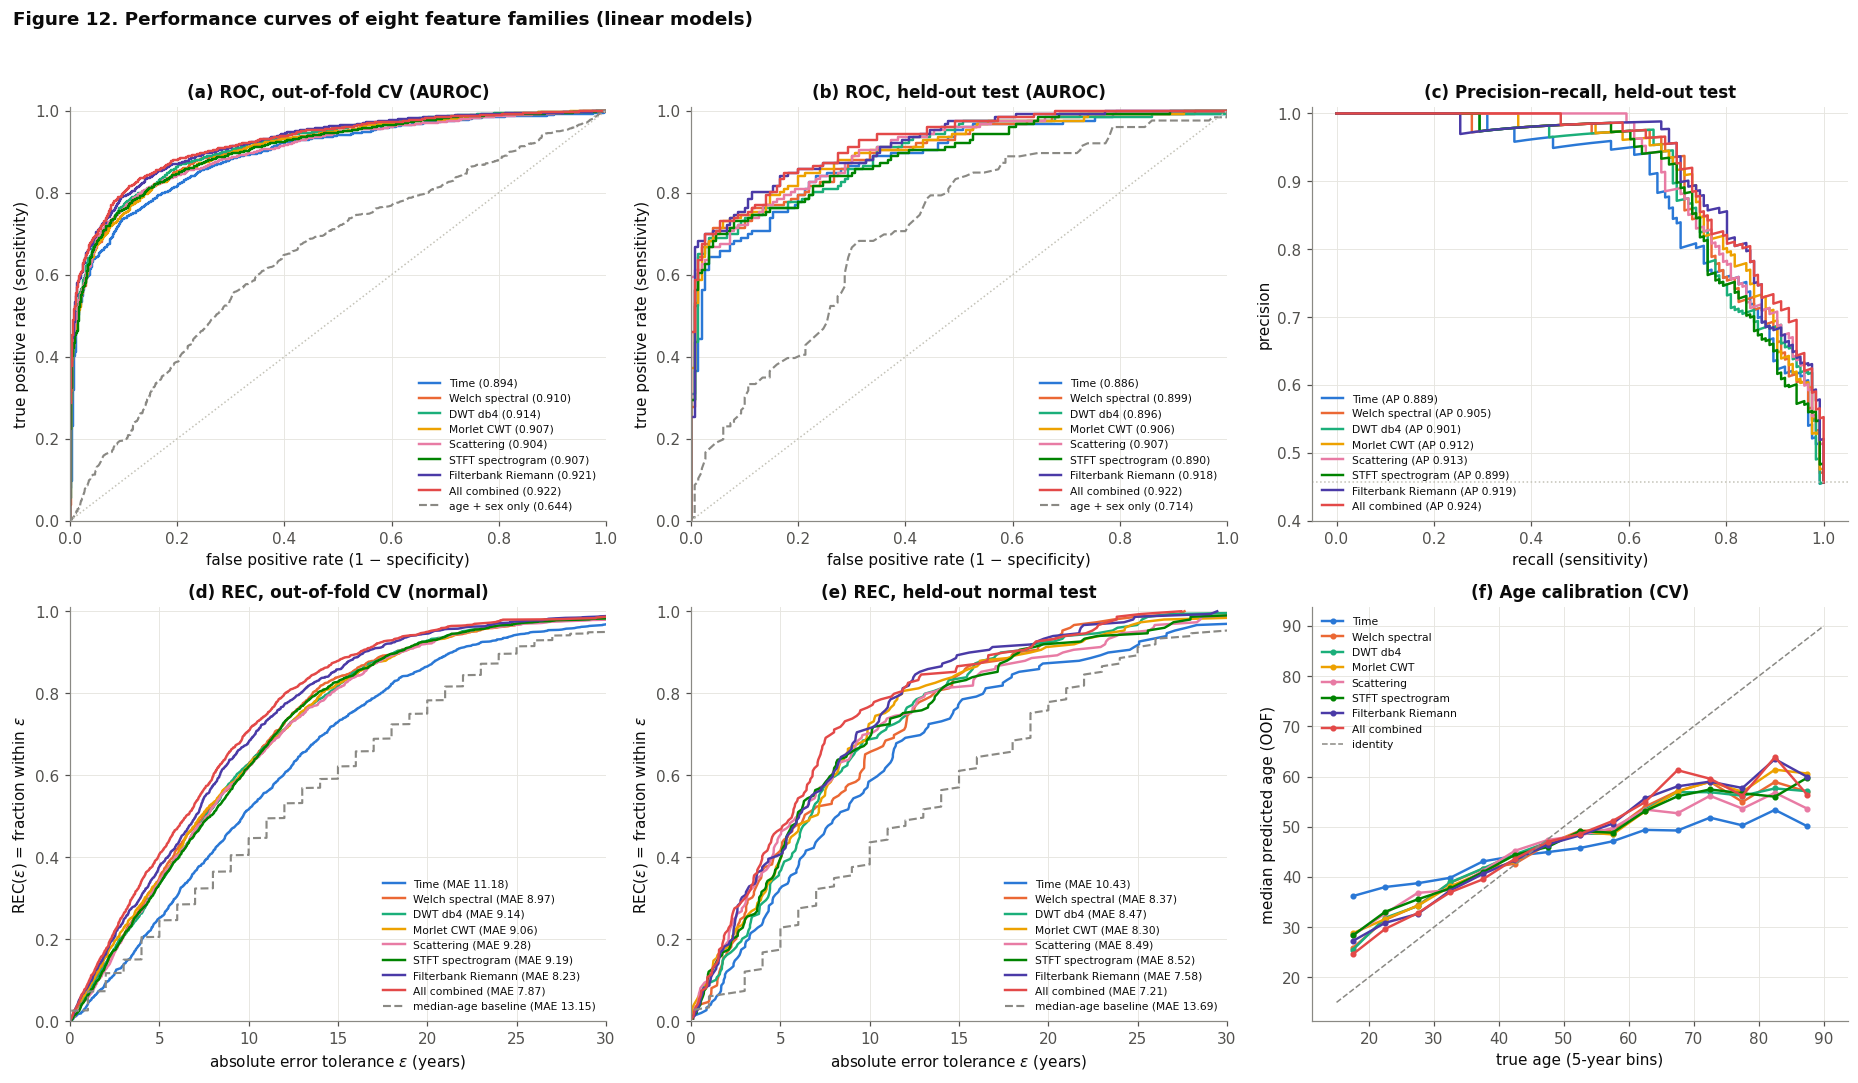

In [21]:
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score

CURVE_FAMS = {
    "Time (Hjorth, line length, moments)": "Time",
    "Spectral (bands, ratios, PAF, 1/f)": "Welch spectral",
    "DWT db4, 6 levels": "DWT db4",
    "CWT Morlet (mean+std over time)": "Morlet CWT",
    "Wavelet scattering (orders 1+2)": "Scattering",
    "STFT spectrogram (mean+std over time)": "STFT spectrogram",
    "Filterbank Riemann (tangent space)": "Filterbank Riemann",
    "All families combined": "All combined",
}
ya, ia_dev, ia_te = Y["abn"], DEV["abn"], TEST["abn"]
ig_dev, ig_te = DEV["age"], TEST["age"]
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for k, (fam, short) in enumerate(CURVE_FAMS.items()):
    c = PAL[k]
    oof, tp = PRED[(fam, "linear", "abn")]
    for ax, yy, pp in [(axes[0, 0], ya[ia_dev], oof), (axes[0, 1], ya[ia_te], tp)]:
        fpr, tpr, _ = roc_curve(yy, pp)
        ax.plot(fpr, tpr, color=c, lw=1.6, label=f"{short} ({roc_auc_score(yy, pp):.3f})")
    prec, rec_, _ = precision_recall_curve(ya[ia_te], tp)
    axes[0, 2].plot(rec_, prec, color=c, lw=1.6, label=f"{short} (AP {average_precision_score(ya[ia_te], tp):.3f})")
    oof_a, tp_a = PRED[(fam, "linear", "age")]
    for ax, yy, pp in [(axes[1, 0], age[ig_dev], oof_a), (axes[1, 1], age[ig_te], tp_a)]:
        e = np.sort(np.abs(pp - yy))
        ax.plot(e, np.arange(1, len(e) + 1) / len(e), color=c, lw=1.6, label=f"{short} (MAE {e.mean():.2f})")
    edges = np.arange(15, 95, 5)
    mids, med = [], []
    for lo_, hi_ in zip(edges[:-1], edges[1:]):
        m = (age[ig_dev] >= lo_) & (age[ig_dev] < hi_)
        if m.sum() >= 10:
            mids.append((lo_ + hi_) / 2); med.append(np.median(oof_a[m]))
    axes[1, 2].plot(mids, med, color=c, lw=1.6, marker="o", ms=3, label=short)

# baselines
oof_b, tp_b = PRED[("Baseline: age + sex only", "linear", "abn")]
for ax, yy, pp in [(axes[0, 0], ya[ia_dev], oof_b), (axes[0, 1], ya[ia_te], tp_b)]:
    fpr, tpr, _ = roc_curve(yy, pp)
    ax.plot(fpr, tpr, color="#8a8984", lw=1.4, ls="--", label=f"age + sex only ({roc_auc_score(yy, pp):.3f})")
    ax.plot([0, 1], [0, 1], color="#c3c2b7", lw=1, ls=":")
    ax.set(xlabel="false positive rate (1 − specificity)", ylabel="true positive rate (sensitivity)", xlim=(0, 1), ylim=(0, 1.01))
axes[0, 0].set_title("ROC, out-of-fold CV (AUROC)"); axes[0, 1].set_title("ROC, held-out test (AUROC)")
prev = ya[ia_te].mean()
axes[0, 2].axhline(prev, color="#c3c2b7", lw=1, ls=":")
axes[0, 2].set(xlabel="recall (sensitivity)", ylabel="precision", title="Precision–recall, held-out test", ylim=(0.4, 1.01))
for ax, yy in [(axes[1, 0], age[ig_dev]), (axes[1, 1], age[ig_te])]:
    e = np.sort(np.abs(np.median(age[ig_dev]) - yy))
    ax.plot(e, np.arange(1, len(e) + 1) / len(e), color="#8a8984", lw=1.4, ls="--", label=f"median-age baseline (MAE {e.mean():.2f})")
    ax.set(xlabel=r"absolute error tolerance $\varepsilon$ (years)", ylabel=r"REC($\varepsilon$) = fraction within $\varepsilon$", xlim=(0, 30), ylim=(0, 1.01))
axes[1, 0].set_title("REC, out-of-fold CV (normal)"); axes[1, 1].set_title("REC, held-out normal test")
axes[1, 2].plot([15, 90], [15, 90], color="#8a8984", lw=1, ls="--", label="identity")
axes[1, 2].set(xlabel="true age (5-year bins)", ylabel="median predicted age (OOF)", title="Age calibration (CV)")
for ax in axes.ravel():
    ax.legend(fontsize=7, loc="lower right")
axes[0, 2].legend(fontsize=7, loc="lower left"); axes[1, 2].legend(fontsize=7, loc="upper left")
finish(fig, axes, 12, "Performance curves of eight feature families (linear models)")

**Figure 12.** Curves for eight feature families (linear models) and baselines (grey dashed). (a) ROC of pooled out-of-fold CV predictions and (b) ROC on the held-out test set, AUROC in the legend; dotted = chance. (c) Precision–recall on the held-out test set, average precision in the legend; dotted = prevalence of abnormal recordings. (d) REC curve (fraction of recordings with absolute age error ≤ ε) for out-of-fold CV predictions on normal recordings and (e) on the held-out normal test set, MAE in the legend; the area above each curve equals its MAE. (f) Age calibration: median out-of-fold predicted age per 5-year bin of true age; dashed = identity.

## 6. Multi-scale deep dive

### 6.1 Which mother wavelet?
First, what the choice does physically. A sine $x(t) = \sin(2\pi f t + \varphi)$ is pushed
through a 6-level DWT. The fraction of its energy that lands in each level,
$$\rho_j(f) = \Bigl\langle\frac{\sum_k u_j[k]^2}{\sum_i\sum_k u_i[k]^2}\Bigr\rangle_{\varphi},$$
is averaged over 6 phases $\varphi$ (Fig. 13). Ideal (brick-wall) filters would give $\rho_j(f) = \mathbb 1[f\in\text{band}_j]$:
clean rectangles between the dashed nominal edges $f_s/2^{j+1}$ and $f_s/2^j$.

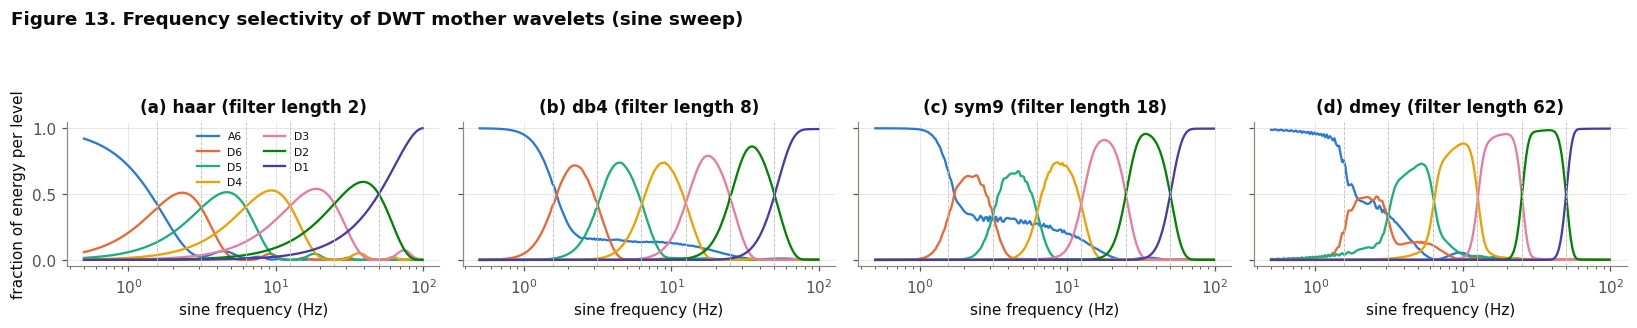

In [22]:
sweep = np.geomspace(0.5, 99, 220)
tt = np.arange(2000) / 200
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, w in zip(axes, ["haar", "db4", "sym9", "dmey"]):
    E = []
    for f in sweep:
        e = np.zeros(7)
        for ph in np.linspace(0, np.pi, 6, endpoint=False):  # average over phases
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                cs = pywt.wavedec(np.sin(2 * np.pi * f * tt + ph), w, level=6)
            ei = np.array([(c ** 2).sum() for c in cs]); e += ei / ei.sum()
        E.append(e / 6)
    E = np.array(E)
    for k in range(7):
        ax.plot(sweep, E[:, k], lw=1.5, color=PAL[k % len(PAL)])
    for lo, hi in fx.dwt_band_edges(6)[1:]:
        ax.axvline(lo, color="#c3c2b7", lw=0.6, ls="--")
    w_obj = pywt.Wavelet(w)
    ax.set(xscale="log", title=f"{w} (filter length {w_obj.dec_len})", xlabel="sine frequency (Hz)")
axes[0].set_ylabel("fraction of energy per level")
axes[0].legend(["A6"] + [f"D{j}" for j in range(6, 0, -1)], fontsize=7, ncol=2)
finish(fig, axes, 13, "Frequency selectivity of DWT mother wavelets (sine sweep)")

**Figure 13.** For each mother wavelet (a: Haar, b: db4, c: sym9, d: dmey), the fraction $\rho_j(f)$ of a sine's energy landing in each DWT level (6 levels, 200 Hz), vs sine frequency, averaged over 6 phases. Dashed lines: nominal dyadic band edges. The filter length is in the panel title.

Short filters (Haar) leak heavily into neighbouring levels. Long filters (sym9, dmey) are close
to ideal, at the cost of boundary effects (dmey's 62-tap filter is longer than the deepest
level's data on a 10 s window). A Daubechies wavelet dbN has $N$ vanishing moments
($\int t^k\psi(t)\,dt = 0$ for $k < N$) and a filter of length $2N$. More vanishing moments give a
steeper roll-off and less leakage.

Does this matter for prediction? Fig. 14 uses the same DWT feature set (log energy, relative
energy, wavelet entropy per level, 19 channels) for each mother wavelet, and for depths
$L = 4..7$ with db4.

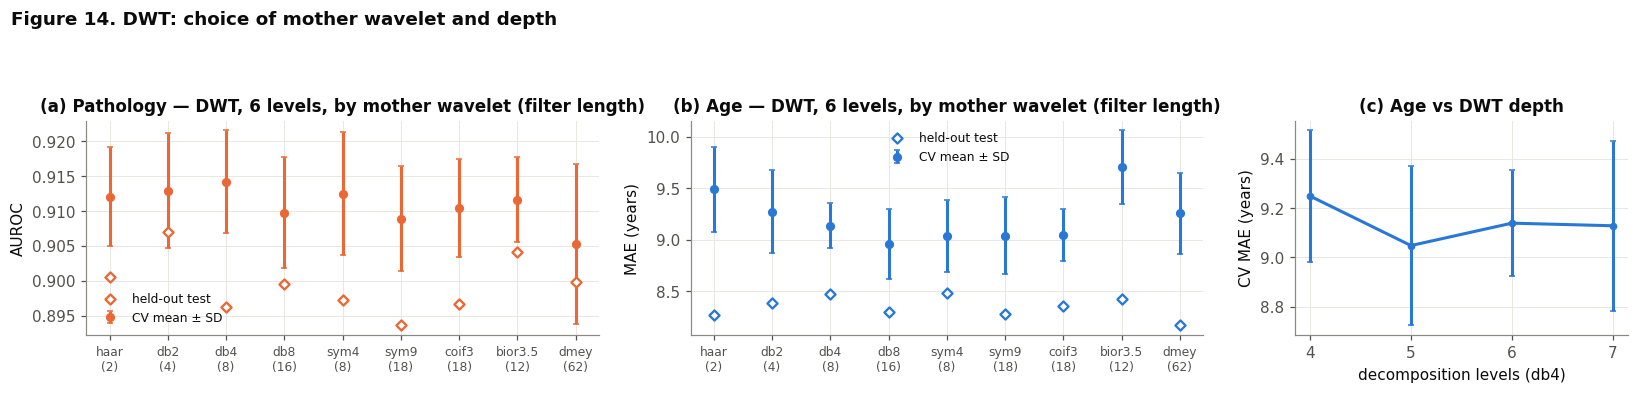

,cv_AUROC,cv_MAE,test_AUROC,test_MAE
task,abn,age,abn,age
wavelet,,,,
haar,0.912,9.490,0.900,8.270
db2,0.913,9.274,0.907,8.384
db4,0.914,9.139,0.896,8.470
db8,0.910,8.960,0.900,8.302
sym4,0.912,9.034,0.897,8.486
sym9,0.909,9.041,0.894,8.286
coif3,0.910,9.043,0.897,8.358
bior3.5,0.912,9.702,0.904,8.430


In [23]:
rows = []
for w in tuab.DWT_WAVELETS:
    X = Xrec(f"dwt_{w}_L6")
    for task in ("abn", "age"):
        r, _, _ = evaluate(X, task)
        rows.append({"wavelet": w, "filter_len": pywt.Wavelet(w).dec_len, "task": task, **r})
wav = pd.DataFrame(rows)
for lev in tuab.DWT_LEVELS:
    X = Xrec(f"dwt_db4_L{lev}")
    for task in ("abn", "age"):
        r, _, _ = evaluate(X, task)
        rows.append({"wavelet": f"db4 L{lev}", "filter_len": 8, "task": task, "level": lev, **r})
wav_all = pd.DataFrame(rows)
lvl = wav_all[wav_all.wavelet.str.startswith("db4 L")]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={"width_ratios": [2, 2, 1.3]})
for ax, task, metric, c in [(axes[0], "abn", "cv_AUROC", C_ABN), (axes[1], "age", "cv_MAE", C_NORMAL)]:
    d = wav[wav.task == task]
    ax.errorbar(range(len(d)), d[metric], yerr=d[metric + "_sd"], fmt="o", ms=5, capsize=2, color=c, label="CV mean ± SD")
    ax.scatter(range(len(d)), d["test_" + metric[3:]], marker="D", s=22, facecolor="white", edgecolor=c, lw=1.5, zorder=3, label="held-out test")
    ax.set_xticks(range(len(d)), [f"{w}\n({L})" for w, L in zip(d.wavelet, d.filter_len)], fontsize=8)
    ax.set(ylabel="AUROC" if task == "abn" else "MAE (years)", title=("Pathology" if task == "abn" else "Age") + " — DWT, 6 levels, by mother wavelet (filter length)")
    ax.legend(fontsize=8)
d_g = lvl[lvl.task == "age"]
axes[2].errorbar(d_g.level, d_g.cv_MAE, yerr=d_g.cv_MAE_sd, marker="o", ms=4, capsize=2, color=C_NORMAL)
axes[2].set(xlabel="decomposition levels (db4)", ylabel="CV MAE (years)", title="Age vs DWT depth")
axes[2].set_xticks(list(tuab.DWT_LEVELS))
finish(fig, axes, 14, "DWT: choice of mother wavelet and depth")
display(wav_all.pivot_table(index="wavelet", columns="task", values=["cv_AUROC", "cv_MAE", "test_AUROC", "test_MAE"], sort=False).dropna(axis=1, how="all").round(3))

**Figure 14.** DWT feature set (log energy, relative energy, wavelet entropy; 19 channels) with linear models. (a) Pathology AUROC and (b) age MAE per mother wavelet (filter length in parentheses); filled = CV mean ± SD, open = held-out test. (c) Age MAE vs decomposition depth $L$ (db4).

### 6.2 DWT vs WPD vs CWT vs Fourier, and what the CWT's time variability adds
All on the same 19 channels and reference preparation (Fig. 15). The CWT is shown with three
Morlet bandwidths, $B \in \{0.5, 1.5, 5\}$, i.e. $n_{\text{cyc}} = \pi\sqrt{2B} \approx 3.1, 5.4, 9.9$ cycles. Each is
used as **mean-only** $\mu(f_0)$ (≈ a smoothed spectrum), **std-only** $s(f_0)$, and **both**.
More cycles mean finer frequency resolution $\sigma_f = f_0/n_{\text{cyc}}$ but coarser time resolution
$\sigma_t = n_{\text{cyc}}/(2\pi f_0)$.

,cv_AUROC,cv_MAE,test_AUROC,test_MAE
task,abn,age,abn,age
representation,,,,
Welch log-PSD (1 Hz bins),0.910,8.476,0.898,7.623
Welch band features,0.910,8.971,0.899,8.368
DWT db4 (6 levels),0.914,9.139,0.896,8.470
WPD db4 (16 nodes),0.908,9.054,0.898,8.439
DWT + WPD,0.914,8.881,0.901,8.335
CWT 3.1 cycles: mean,0.911,9.112,0.906,8.127
CWT 3.1 cycles: std,0.789,11.865,0.819,11.865
CWT 3.1 cycles: mean+std,0.912,9.480,0.915,8.498


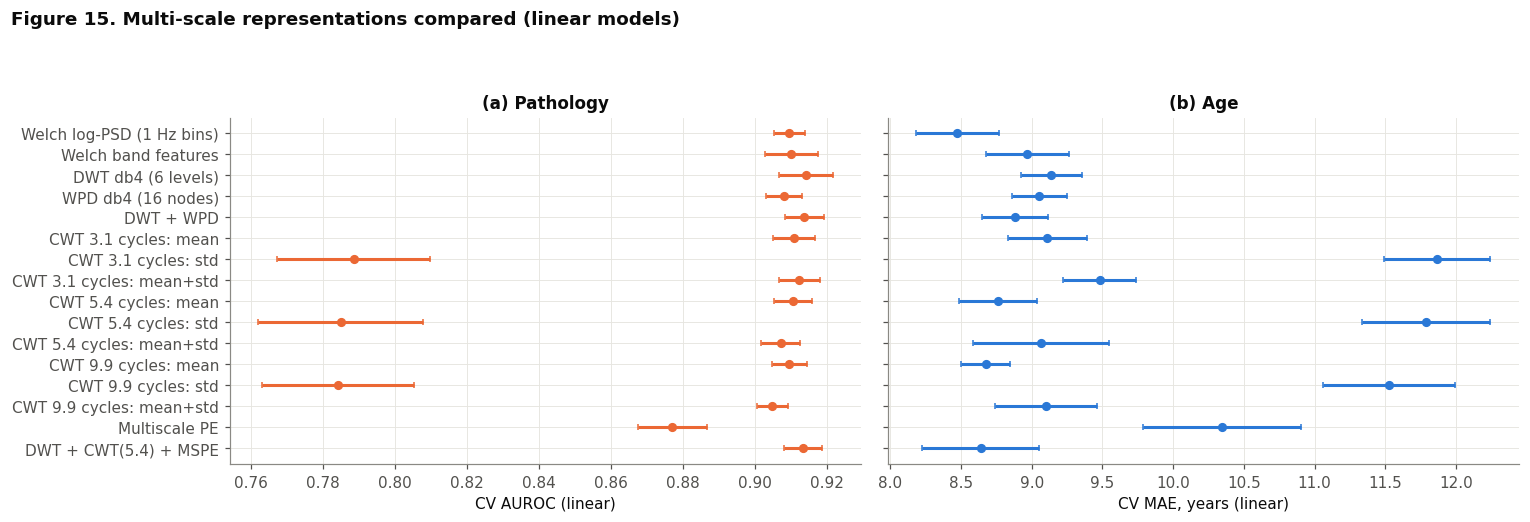

In [24]:
def cwt_part(w, part):
    a = rec(f"cwt_{w}")
    a = a[..., :25] if part == "mean" else (a[..., 25:] if part == "std" else a)
    return nan_to_median(a.reshape(N, -1))

variants = {
    "Welch log-PSD (1 Hz bins)": Xrec("psd_bins"),
    "Welch band features": Xrec("spectral"),
    "DWT db4 (6 levels)": Xrec("dwt_db4_L6"),
    "WPD db4 (16 nodes)": Xrec("wpd_db4_L5"),
    "DWT + WPD": Xrec("dwt_db4_L6", "wpd_db4_L5"),
}
for w, cyc in [("cmor0.5-1.0", 3.1), ("cmor1.5-1.0", 5.4), ("cmor5.0-1.0", 9.9)]:
    variants[f"CWT {cyc} cycles: mean"] = cwt_part(w, "mean")
    variants[f"CWT {cyc} cycles: std"] = cwt_part(w, "std")
    variants[f"CWT {cyc} cycles: mean+std"] = cwt_part(w, "both")
variants["Multiscale PE"] = Xrec("mspe")
variants["DWT + CWT(5.4) + MSPE"] = Xrec("dwt_db4_L6", "cwt_cmor1.5-1.0", "mspe")
rows = []
for name, X in variants.items():
    for task in ("abn", "age"):
        r, _, _ = evaluate(X, task)
        rows.append({"representation": name, "task": task, "n_features": X.shape[1], **r})
ms = pd.DataFrame(rows)
display(ms.pivot_table(index="representation", columns="task", values=["cv_AUROC", "cv_MAE", "test_AUROC", "test_MAE"], sort=False).dropna(axis=1, how="all").round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
names_ = list(variants)
for ax, task, metric, c in [(axes[0], "abn", "cv_AUROC", C_ABN), (axes[1], "age", "cv_MAE", C_NORMAL)]:
    d = ms[ms.task == task].set_index("representation").reindex(names_)
    ax.errorbar(d[metric], range(len(d)), xerr=d[metric + "_sd"], fmt="o", ms=5, capsize=2, color=c)
    ax.set_yticks(range(len(d)), names_ if task == "abn" else [""] * len(d)); ax.invert_yaxis()
    ax.set(xlabel="CV AUROC (linear)" if task == "abn" else "CV MAE, years (linear)", title="Pathology" if task == "abn" else "Age")
finish(fig, axes, 15, "Multi-scale representations compared (linear models)")

**Figure 15.** Linear-model CV scores (mean ± SD) for Fourier (Welch), DWT, WPD, Morlet CWT (3 bandwidths; mean, std or both), MSPE and a multi-scale combination. (a) Pathology AUROC. (b) Age MAE.

### 6.3 Wavelet scattering networks: does the second order help?
Variants (linear models, reference preparation; gradient boosting on orders 1+2 is in §5):
* **order 1** only (log S1, ≈ constant-Q band energies, 8 filters per octave);
* **order 2** only (log S2/S1, envelope-modulation spectra);
* **orders 1+2**;
* each at two averaging scales: **J = 7** (1.28 s, modulations down to ≈0.3 Hz) and **J = 9** (5.1 s, down to ≈0.07 Hz).

They are compared with the Morlet CWT (mean, and mean+std over time), the closest
non-scattering representation (Fig. 16).

At 100 Hz, the averaging window of $2^J$ samples lasts $2^J/100$ s, and the slowest modulation
the second layer can resolve is roughly $\lambda_2^{\min} \approx 100/2^J$ Hz.

n_features         cv_AUROC  cv_MAE  \
task                                       abn     age      abn     age   
representation                                                            
Scattering J=7 (1.28 s): order 1         874.0   874.0    0.909   8.492   
Scattering J=7 (1.28 s): order 2        2451.0  2451.0    0.847  11.128   
Scattering J=7 (1.28 s): orders 1+2     3325.0  3325.0    0.904   9.277   
Scattering J=9 (5.1 s): order 1         1178.0  1178.0    0.908   8.734   
Scattering J=9 (5.1 s): order 2         4503.0  4503.0    0.880  10.179   
Scattering J=9 (5.1 s): orders 1+2      5681.0  5681.0    0.906   9.164   
CWT 5.4 cycles: mean                     475.0   475.0    0.911   8.763   
CWT 5.4 cycles: mean+std                 950.0   950.0    0.907   9.066   
Scattering J=7 1+2 + CWT std            3800.0  3800.0    0.907   9.059   

                                    test_AUROC test_MAE  
task                                       abn      age  
representation                                           
Scattering J=7 (1.28 s): order 1         0.902    7.508  
Scattering J=7 (1.28 s): order 2         0.866   11.640  
Scattering J=7 (1.28 s): orders 1+2      0.907    8.490  
Scattering J=9 (5.1 s): order 1          0.905    7.849  
Scattering J=9 (5.1 s): order 2          0.889   10.443  
Scattering J=9 (5.1 s): orders 1+2       0.911    8.801  
CWT 5.4 cycles: mean                     0.907    7.789  
CWT 5.4 cycles: mean+std                 0.906    8.296  
Scattering J=7 1+2 + CWT std             0.910    8.508

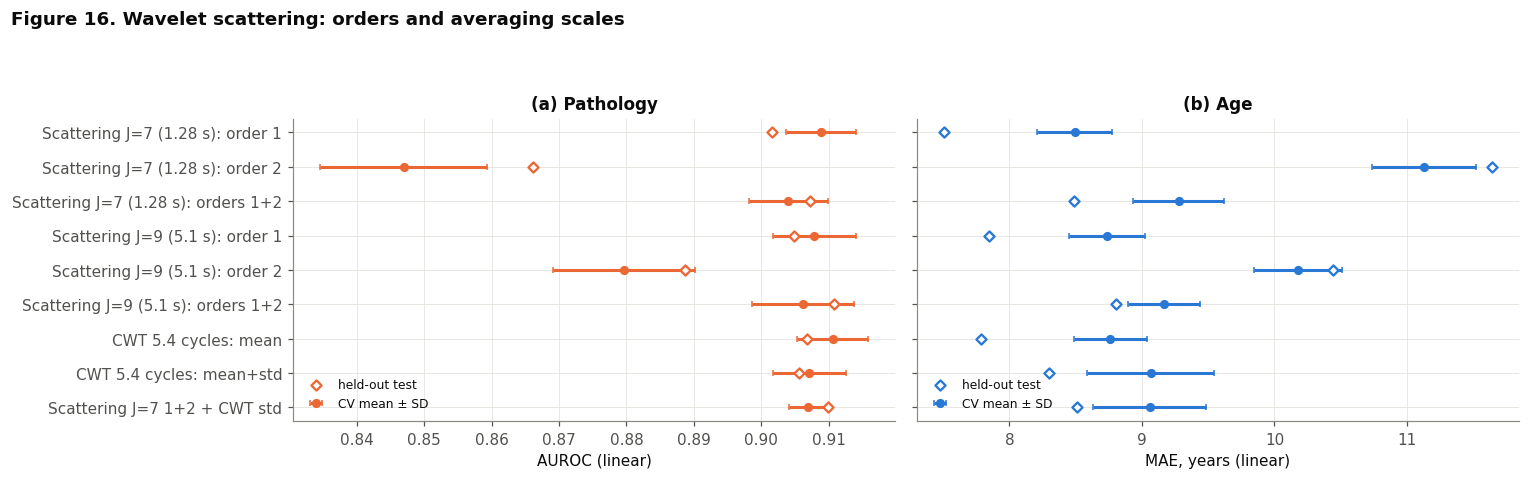

In [25]:
def scat_part(fam, order):
    names_ = NAMES[fam]
    keep = [i for i, n in enumerate(names_) if order == "both" or n.startswith(f"S{order}_")]
    return nan_to_median(rec(fam)[..., keep].reshape(N, -1))

scat_variants = {}
for fam, label in [("scat_J7_Q8", "J=7 (1.28 s)"), ("scat_J9_Q8", "J=9 (5.1 s)")]:
    for order, olab in [("1", "order 1"), ("2", "order 2"), ("both", "orders 1+2")]:
        scat_variants[f"Scattering {label}: {olab}"] = scat_part(fam, order)
scat_variants["CWT 5.4 cycles: mean"] = cwt_part("cmor1.5-1.0", "mean")
scat_variants["CWT 5.4 cycles: mean+std"] = cwt_part("cmor1.5-1.0", "both")
scat_variants["Scattering J=7 1+2 + CWT std"] = np.concatenate([scat_part("scat_J7_Q8", "both"), cwt_part("cmor1.5-1.0", "std")], axis=1)
rows = []
for name, X in scat_variants.items():
    for task in ("abn", "age"):
        r, _, _ = evaluate(X, task)
        rows.append({"representation": name, "task": task, "n_features": X.shape[1], **r})
scat = pd.DataFrame(rows)
display(scat.pivot_table(index="representation", columns="task", values=["n_features", "cv_AUROC", "cv_MAE", "test_AUROC", "test_MAE"], sort=False).dropna(axis=1, how="all").round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
names_ = list(scat_variants)
for ax, task, metric in [(axes[0], "abn", "cv_AUROC"), (axes[1], "age", "cv_MAE")]:
    c = C_ABN if task == "abn" else C_NORMAL
    d = scat[scat.task == task].set_index("representation").reindex(names_)
    ax.errorbar(d[metric], np.arange(len(d)), xerr=d[metric + "_sd"], fmt="o", ms=5, capsize=2, color=c, label="CV mean ± SD")
    ax.scatter(d["test_" + metric[3:]], np.arange(len(d)), marker="D", s=22, facecolor="white", edgecolor=c, lw=1.5, zorder=3, label="held-out test")
    ax.set_yticks(range(len(names_)), names_)
    ax.set(xlabel="AUROC (linear)" if task == "abn" else "MAE, years (linear)", title="Pathology" if task == "abn" else "Age")
    ax.legend(fontsize=8)
axes[0].invert_yaxis()
finish(fig, axes, 16, "Wavelet scattering: orders and averaging scales")

**Figure 16.** Wavelet scattering (order 1, order 2, orders 1+2) at J = 7 (1.28 s) and J = 9 (5.1 s), compared with the Morlet CWT. Linear models: filled = CV mean ± SD, open = held-out test. (a) Pathology AUROC. (b) Age MAE.

Where is the second-order information? Each cell in Fig. 17 is one (rhythm λ1, modulation λ2)
pair of the J = 9 network, scored by the channel-averaged $\log_{10}(S_2/S_1)$. It shows the channel-averaged univariate AUROC for pathology and
the Spearman ρ with age (normal recordings), computed on the development pool.

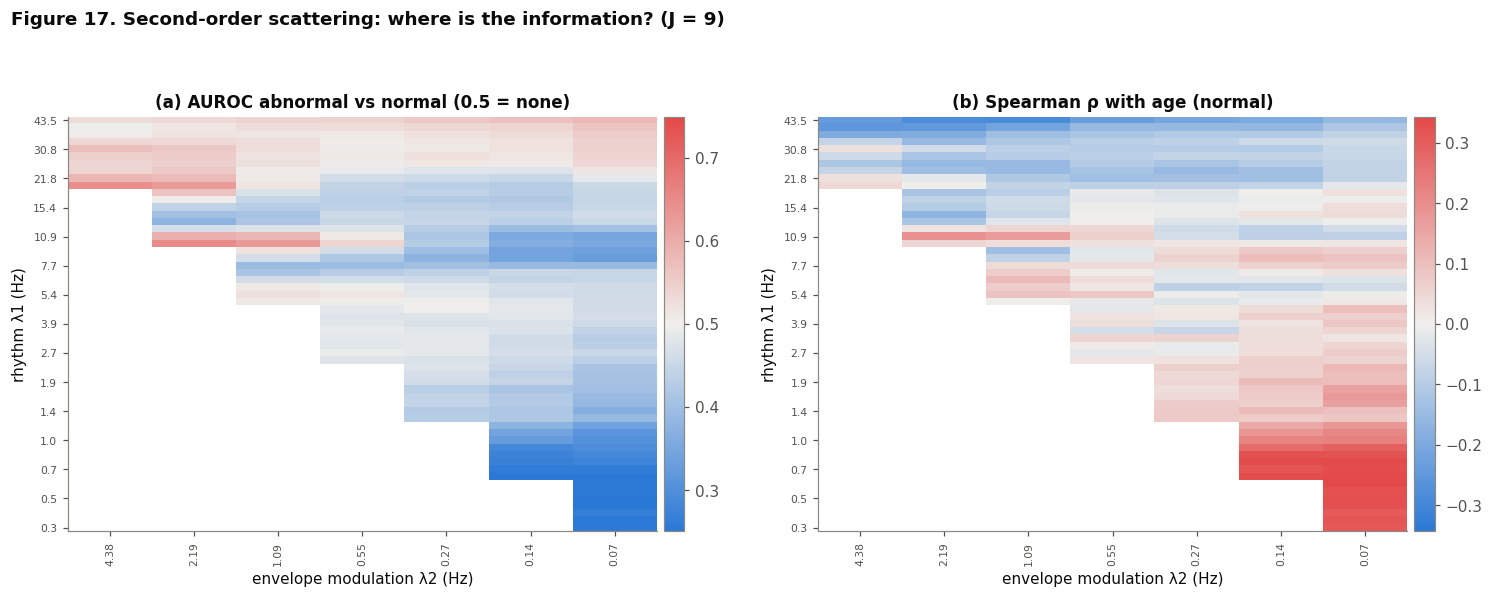

strongest second-order coefficients for pathology: [('0.4 Hz x 0.07 Hz', 0.251), ('0.5 Hz x 0.07 Hz', 0.252), ('0.6 Hz x 0.07 Hz', 0.254), ('0.6 Hz x 0.14 Hz', 0.254), ('0.3 Hz x 0.07 Hz', 0.254)]
strongest second-order coefficients for age: [('0.6 Hz x 0.07 Hz', 0.343), ('0.6 Hz x 0.07 Hz', 0.341), ('0.7 Hz x 0.14 Hz', 0.338), ('0.7 Hz x 0.07 Hz', 0.335), ('0.7 Hz x 0.07 Hz', 0.331)]


In [26]:
fam = "scat_J9_Q8"
names_ = NAMES[fam]
i2 = [i for i, n in enumerate(names_) if n.startswith("S2_")]
f1 = np.array([float(names_[i].split("_")[1][:-2]) for i in i2])
f2 = np.array([float(names_[i].split("mod")[1][:-2]) for i in i2])
vals = rec(fam)[:, :, i2].mean(axis=1)  # channel-averaged log S2/S1
auc2 = np.array([roc_auc_score(Y["abn"][DEV["abn"]], vals[DEV["abn"], j]) for j in range(len(i2))])
rho2 = np.array([stats.spearmanr(vals[DEV["age"], j], age[DEV["age"]])[0] for j in range(len(i2))])
u1, u2 = np.unique(f1)[::-1], np.unique(f2)[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, v, title, centre in [(axes[0], auc2, "AUROC abnormal vs normal (0.5 = none)", 0.5),
                             (axes[1], rho2, "Spearman ρ with age (normal)", 0.0)]:
    M = np.full((len(u1), len(u2)), np.nan)
    for a, b, val in zip(f1, f2, v):
        M[np.searchsorted(-u1, -a), np.searchsorted(-u2, -b)] = val
    lim = np.nanmax(np.abs(M - centre))
    im = ax.imshow(M, cmap=DIV, vmin=centre - lim, vmax=centre + lim, aspect="auto")
    ax.set_yticks(range(0, len(u1), 4), [f"{x:.1f}" for x in u1[::4]], fontsize=7)
    ax.set_xticks(range(len(u2)), [f"{x:.2f}" for x in u2], fontsize=7, rotation=90)
    ax.set(ylabel="rhythm λ1 (Hz)", xlabel="envelope modulation λ2 (Hz)", title=title); ax.grid(False)
    plt.colorbar(im, ax=ax, pad=0.01)
finish(fig, axes, 17, "Second-order scattering: where is the information? (J = 9)")
best = np.argsort(-np.abs(auc2 - 0.5))[:5]
print("strongest second-order coefficients for pathology:",
      [(f"{f1[j]:.1f} Hz x {f2[j]:.2f} Hz", round(auc2[j], 3)) for j in best])
best = np.argsort(-np.abs(rho2))[:5]
print("strongest second-order coefficients for age:",
      [(f"{f1[j]:.1f} Hz x {f2[j]:.2f} Hz", round(rho2[j], 3)) for j in best])

**Figure 17.** Channel-averaged renormalised second-order coefficients $\log_{10}(S_2/S_1)$ of the J = 9 scattering network, per pair (rhythm $\lambda_1$, envelope modulation $\lambda_2$). (a) AUROC abnormal vs normal (blue < 0.5: lower in abnormal). (b) Spearman $\rho$ with age (normal recordings). Blank cells: pairs not computed ($\lambda_2$ above the bandwidth of $\psi_{\lambda_1}$).

### 6.4 Spectrogram features: fixed-resolution time–frequency
Variants (linear models, reference preparation; definitions in §1.6):
* STFT log-spectrogram, mean over time (≈ Welch), std over time (temporal variability), and both;
* multitaper (DPSS) spectrogram, mean and mean+std;
* band-power dynamics (variability, lag-1 persistence, spectral flux);
* cepstral coefficients, mean and mean+std.

They are compared with the Welch 1 Hz bins and the Morlet CWT mean (Fig. 18).

n_features         cv_AUROC  cv_MAE test_AUROC  \
task                             abn     age      abn     age        abn   
representation                                                             
Welch log-PSD (1 Hz bins)      836.0   836.0    0.910   8.476      0.898   
CWT 5.4 cycles: mean           475.0   475.0    0.911   8.763      0.907   
STFT: mean                     836.0   836.0    0.909   8.501      0.902   
STFT: std                      836.0   836.0    0.778  12.307      0.769   
STFT: mean+std                1672.0  1672.0    0.906   9.194      0.890   
Multitaper: mean               836.0   836.0    0.908   8.432      0.902   
Multitaper: mean+std          1672.0  1672.0    0.906   8.915      0.894   
Spectrogram dynamics           209.0   209.0    0.835  11.927      0.845   
STFT mean + dynamics          1045.0  1045.0    0.915   8.750      0.916   
Cepstral: mean                 247.0   247.0    0.905   8.532      0.898   
Cepstral: mean+std             494.0   494.0    0.898   9.133      0.901   

                          test_MAE test_abn_MAE  
task                           age          age  
representation                                   
Welch log-PSD (1 Hz bins)    7.623       14.964  
CWT 5.4 cycles: mean         7.789       15.363  
STFT: mean                   7.924       15.236  
STFT: std                   12.757       17.099  
STFT: mean+std               8.518       16.473  
Multitaper: mean             7.844       15.120  
Multitaper: mean+std         7.995       15.451  
Spectrogram dynamics        11.334       17.137  
STFT mean + dynamics         7.621       15.601  
Cepstral: mean               7.963       15.330  
Cepstral: mean+std           8.342       16.161

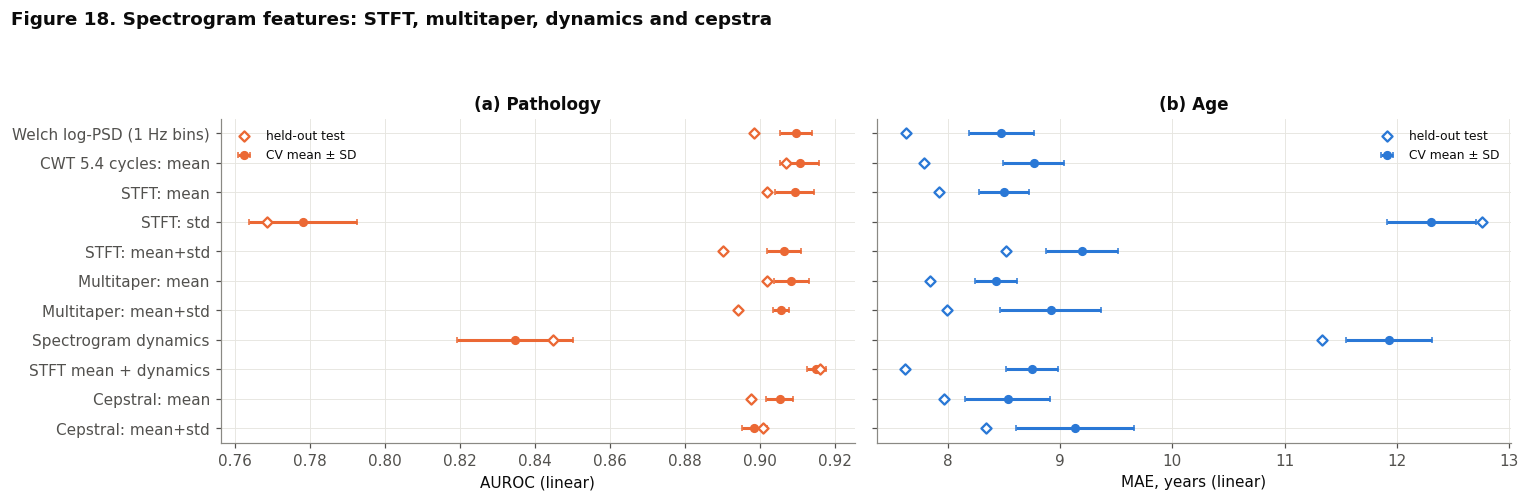

In [27]:
def half(fam, part):
    a = rec(fam)
    n = a.shape[-1] // 2
    a = a[..., :n] if part == "mean" else (a[..., n:] if part == "std" else a)
    return nan_to_median(a.reshape(N, -1))

spec_variants = {
    "Welch log-PSD (1 Hz bins)": Xrec("psd_bins"),
    "CWT 5.4 cycles: mean": cwt_part("cmor1.5-1.0", "mean"),
    "STFT: mean": half("stft", "mean"),
    "STFT: std": half("stft", "std"),
    "STFT: mean+std": half("stft", "both"),
    "Multitaper: mean": half("multitaper", "mean"),
    "Multitaper: mean+std": half("multitaper", "both"),
    "Spectrogram dynamics": Xrec("stft_dyn"),
    "STFT mean + dynamics": np.concatenate([half("stft", "mean"), Xrec("stft_dyn")], axis=1),
    "Cepstral: mean": half("cepstral", "mean"),
    "Cepstral: mean+std": half("cepstral", "both"),
}
rows = []
for name, X in spec_variants.items():
    for task in ("abn", "age"):
        r, _, _ = evaluate(X, task)
        rows.append({"representation": name, "task": task, "n_features": X.shape[1], **r})
spec_res = pd.DataFrame(rows)
display(spec_res.pivot_table(index="representation", columns="task",
                             values=["n_features", "cv_AUROC", "cv_MAE", "test_AUROC", "test_MAE", "test_abn_MAE"],
                             sort=False).dropna(axis=1, how="all").round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
names_ = list(spec_variants)
for ax, task, metric in [(axes[0], "abn", "cv_AUROC"), (axes[1], "age", "cv_MAE")]:
    c = C_ABN if task == "abn" else C_NORMAL
    d = spec_res[spec_res.task == task].set_index("representation").reindex(names_)
    ax.errorbar(d[metric], np.arange(len(d)), xerr=d[metric + "_sd"], fmt="o", ms=5, capsize=2, color=c, label="CV mean ± SD")
    ax.scatter(d["test_" + metric[3:]], np.arange(len(d)), marker="D", s=22, facecolor="white", edgecolor=c, lw=1.5, zorder=3, label="held-out test")
    ax.set_yticks(range(len(names_)), names_)
    ax.set(xlabel="AUROC (linear)" if task == "abn" else "MAE, years (linear)", title="Pathology" if task == "abn" else "Age")
    ax.legend(fontsize=8)
axes[0].invert_yaxis()
finish(fig, axes, 18, "Spectrogram features: STFT, multitaper, dynamics and cepstra")

**Figure 18.** Linear-model scores of spectrogram-based representations, with the Welch 1 Hz bins and the Morlet CWT mean as references. Filled: CV mean ± SD over 5 folds; open diamonds: held-out test. (a) Pathology AUROC. (b) Age MAE.

## 7. Combined model, family ablation, and the brain-age gap

### 7.1 Leave-one-family-out
Starting from the full feature set (linear models), each family $F$ is dropped in turn:
$$\Delta_F = \text{score}(\text{all}\setminus F) - \text{score}(\text{all}).$$
A negative $\Delta$AUROC or a positive $\Delta$MAE means family $F$ carries information that the others do not.

In [28]:
flat_fams = list(ALL_FLAT)
full = {t: bench[(bench.family == "All families combined") & (bench.model == "linear") & (bench.task == t)].iloc[0] for t in ("abn", "age")}
rows = []
for drop in flat_fams + ["riemann"]:
    keep = [f for f in flat_fams if f != drop]
    Xf = Xrec(*keep)
    if drop == "riemann":
        X, pre = Xf, None
    else:
        X, pre = np.concatenate([Xf, X_FB], axis=1), FBTangentSpace(n_passthrough=Xf.shape[1])
    for task in ("abn", "age"):
        r, _, _ = evaluate(X, task, pre=pre, run_test=False)
        rows.append({"dropped": drop, "task": task, **r})
abl = pd.DataFrame(rows)
abl["delta"] = np.where(abl.task == "abn", abl.cv_AUROC - full["abn"].cv_AUROC, abl.cv_MAE - full["age"].cv_MAE)
display(abl.pivot(index="dropped", columns="task", values="delta").rename(
    columns={"abn": "Δ AUROC (neg = family helps)", "age": "Δ MAE (pos = family helps)"}).round(4))

task,Δ AUROC (neg = family helps),Δ MAE (pos = family helps)
dropped,,
cepstral,0.0008,0.1071
cwt_cmor1.5-1.0,-0.0005,0.0270
dwt_db4_L6,-0.0004,0.0251
mspe,0.0000,0.0525
psd_bins,0.0001,0.0146
riemann,-0.0064,0.3426
scat_J7_Q8,0.0032,-0.0820
spectral,0.0002,0.0029
stft,-0.0001,0.0391


### 7.2 Brain-age gap of abnormal EEGs
The best age model (by CV MAE) is trained on normal recordings and then applied to the held-out
test set: normals *and* abnormals. Brain-age estimates regress towards the mean, so the gap
(predicted − chronological age) is **bias-corrected** with a linear fit of the out-of-fold gap
on age in the training pool (Smith et al. 2019 / de Lange & Cole 2020):
$$\Delta_i = \hat y_i - y_i, \qquad (\alpha,\beta) = \arg\min\sum_{i\in\text{train}}\bigl(\Delta^{\text{OOF}}_i - \alpha y_i - \beta\bigr)^2, \qquad \Delta^{\text{corr}}_i = \hat y_i - y_i - (\alpha y_i + \beta).$$
A negative $\alpha$ is the regression to the mean: young subjects are over-estimated and old subjects under-estimated.
Group separation is the Mann–Whitney AUROC of $\Delta^{\text{corr}}$ (Fig. 19).

best age model: All families combined / linear (CV MAE 7.87, test MAE 7.21)


bias fit on training OOF: gap = -0.43*age + 18.5
test normal  : MAE 7.21 y, corrected gap mean -0.63 y
test abnormal: MAE 12.67 y, corrected gap mean -1.77 y
AUROC of the corrected brain-age gap for abnormal vs normal: 0.468 (Mann-Whitney p=0.36)


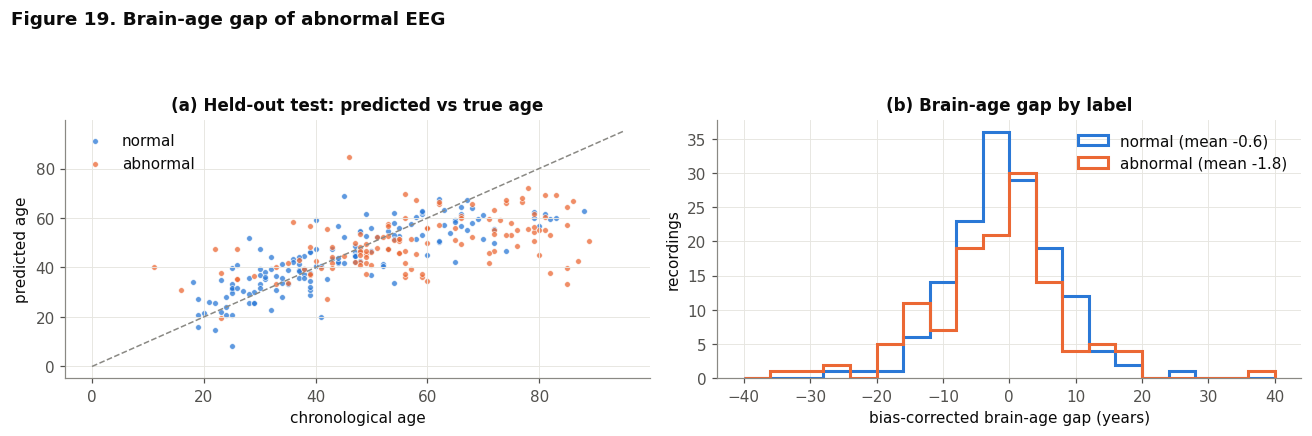

In [29]:
age_bench = bench[(bench.task == "age") & ~bench.family.str.startswith("Baseline")]
best_row = age_bench.sort_values("cv_MAE").iloc[0]
print(f"best age model: {best_row.family} / {best_row.model} (CV MAE {best_row.cv_MAE:.2f}, test MAE {best_row.test_MAE:.2f})")
fams = FAMILIES.get(best_row.family, "all")
if fams == "riemann":
    X, pre = X_FB, FBTangentSpace()
elif fams == "all":
    Xf = Xrec(*ALL_FLAT); X, pre = np.concatenate([Xf, X_FB], axis=1), FBTangentSpace(n_passthrough=Xf.shape[1])
else:
    X, pre = Xrec(*fams), None
oof = PRED[(best_row.family, best_row.model, "age")][0]
idx = DEV["age"]
slope, icpt = np.polyfit(age[idx], oof - age[idx], 1)  # gap = slope*age + icpt in training (OOF)
model = make_model("age", best_row.model)
model = (make_pipeline(clone(pre), model) if pre is not None else model)
with threadpool_limits(N_JOBS):
    model.fit(X[idx], age[idx])
te = np.where(test & age_ok)[0]
pred = model.predict(X[te])
gap = pred - age[te] - (slope * age[te] + icpt)
is_abn = meta.abnormal.to_numpy()[te] == 1
print(f"bias fit on training OOF: gap = {slope:.2f}*age + {icpt:.1f}")
print(f"test normal  : MAE {np.abs(pred[~is_abn] - age[te][~is_abn]).mean():.2f} y, corrected gap mean {gap[~is_abn].mean():+.2f} y")
print(f"test abnormal: MAE {np.abs(pred[is_abn] - age[te][is_abn]).mean():.2f} y, corrected gap mean {gap[is_abn].mean():+.2f} y")
u = stats.mannwhitneyu(gap[is_abn], gap[~is_abn])
print(f"AUROC of the corrected brain-age gap for abnormal vs normal: {u.statistic / (is_abn.sum() * (~is_abn).sum()):.3f} (Mann-Whitney p={u.pvalue:.2g})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for m, lab, c in [(~is_abn, "normal", C_NORMAL), (is_abn, "abnormal", C_ABN)]:
    axes[0].scatter(age[te][m], pred[m], s=14, color=c, alpha=0.75, label=lab, edgecolor="white", linewidth=0.5)
    axes[1].hist(gap[m], bins=np.arange(-40, 41, 4), histtype="step", lw=2, color=c, label=f"{lab} (mean {gap[m].mean():+.1f})")
axes[0].plot([0, 95], [0, 95], color="#8a8984", lw=1, ls="--")
axes[0].set(xlabel="chronological age", ylabel="predicted age", title="Held-out test: predicted vs true age"); axes[0].legend()
axes[1].set(xlabel="bias-corrected brain-age gap (years)", ylabel="recordings", title="Brain-age gap by label"); axes[1].legend()
finish(fig, axes, 19, "Brain-age gap of abnormal EEG")

**Figure 19.** Best age model (trained on normal recordings) applied to held-out test recordings. (a) Predicted vs chronological age; dashed line is the identity. (b) Bias-corrected brain-age gap $\Delta^{\text{corr}}$ by label.

## 8. Conclusions and recommendations

### What the data say

**Data preparation (§3)**
1. **Re-reference first.** Moving from the stored 23-channel montage to the 19 scalp channels with a common average reference was the largest single gain: pathology AUROC 0.893 → 0.914, age MAE 9.89 → 9.00 years (core features; Fig. 5, P3 → P4).
2. **Low-pass at 45 Hz, or notch at 60 Hz.** `make_TUAB.py` notches **50 Hz**, but TUH was recorded in the US. The 60 Hz line survives, is strong in 20% of recordings, and its level differs by label (AUROC 0.61; Fig. 2). Band-limiting to 1–45 Hz improved time features by +0.045 AUROC and age by 0.07–0.55 years depending on the family. The same 60 Hz content is in LaBraM's own fine-tuning input (0.1–75 Hz).
3. **Cropping and rejection have small effects on prediction.** The first minute has 2.7× more rejected windows, concentrated in its first 30 s (9.7% vs 3.6%; Fig. 3b, §3.2), but skipping it and rejecting ±800 µV windows changed AUROC by ≤ 0.01 and age MAE by ≤ 0.25 y. Once artifact windows are rejected, median aggregation was no better than the mean, and slightly worse for age, unlike Gemein 2020. Without rejection the median is the safer choice: it shrinks the 95th-percentile feature shift from 0.24 to 0.08 log units (Fig. 3d).
4. **Length.** 10 s of EEG already gives AUROC 0.89. Pathology saturates after about 2–3 min. Age keeps improving up to the 5 min used here (10.3 → 8.8 y), so use as much clean EEG as possible for brain age (Fig. 6).

**Feature families (§4–5)**
5. The best single **pathology** features are posterior and temporal **θ/α and (δ+θ)/(α+β) ratios** (AUROC up to 0.85), i.e. background slowing. The best single **age** features are frontal-central δ/low-θ power, which falls with age. Peak alpha frequency (≈10 Hz in normals, slowing after 50; ≈8 Hz in abnormal EEG) and the **1/f exponent** (flattening with age in normals; steeper in abnormal EEG) behave as the literature predicts (Fig. 8; channel maps in Fig. 10).
6. **Filterbank-Riemann is the best single family for both targets** (0.922 AUROC; 8.22 y, matching Engemann et al.'s 8.25 y on TUAB; Fig. 11). In the leave-one-family-out analysis it is also the family carrying the most unique information (−0.006 AUROC, +0.34 y when removed). Spatial covariance (coupling) is information that per-channel features lack.
7. Every spectral-type representation (Welch bands or bins, DWT, WPD, CWT, scattering S1, STFT/multitaper spectrograms, cepstra) lands at **0.90–0.92 AUROC**. This is consistent with Gemein's "plateau" and with label noise limiting TUAB. Combining all 12 families reaches **0.926 CV / 0.930 test AUROC** (balanced accuracy 0.846 / 0.838; gradient boosting) and **7.87 CV / 7.21 test MAE** (ridge). The age result is within 0.1 y of the end-to-end ConvNets of Engemann et al. 2022 (7.75–7.80 y; table in §5.1).
7b. **Per class**, every model makes more errors on abnormal recordings: for the spectral, wavelet and Riemann families the test sensitivity is 0.73–0.80 vs specificity 0.85–0.91 (the combined model has 0.77 / 0.91). This is the same asymmetry as Schirrmeister et al. 2017 (Deep4: 75.1 % / 94.1 %). The ROC curves (Fig. 12a, b) show that the families differ mostly at low false-positive rates, where Riemann and the combined model lead.
7c. **Normal-trained age models break on abnormal EEG:** on held-out abnormal recordings the MAE is 12.4–18.6 y, and every model is biased *young*, by −5.9 to −14.8 y (§5 table). The combined model is −7.6 y.
8. **Linear models beat gradient boosting for age**, by 0.8–1.5 y on every family except the time-domain one. For pathology they are on par, with boosting slightly ahead on the held-out set.

**Multi-scale methods (§6)**
9. **Mother wavelet:** irrelevant for pathology (spread 0.009 AUROC ≈ 1 fold SD). For age, short or poorly selective wavelets (Haar 9.49 y, bior3.5 9.70 y) are worst, and longer orthogonal ones (db8 8.96, sym4/sym9/coif3 ≈ 9.04) are best. Fig. 13 shows why: Haar leaks energy across levels (scores in Fig. 14). On the 149-recording test set the ranking is noisy (8.2–8.5 y), so treat differences under 0.3 y as ties. **Depth:** 4 levels is too shallow at 200 Hz (A4 = 0–6 Hz merges δ and θ); 5–7 are equivalent.
10. **CWT:** the time-averaged log scalogram is what carries the signal, and more cycles (finer frequency resolution) are better for age (9.9 cycles: 8.67 y vs 3.1 cycles: 9.11 y). The within-window variability (std over time) is informative on its own (AUROC 0.79) but **redundant** with the mean, and adding it slightly hurts (Fig. 15).
11. **Wavelet scattering:** order-1 coefficients (8 wavelets/octave) are the best wavelet representation for age (8.49 y CV, 7.51 y test), on par with 1 Hz Welch bins. Second-order (envelope-modulation) coefficients alone reach 0.85–0.88 AUROC but add nothing on top of order 1 at recording level, and removing scattering from the combined model *improves* age MAE by 0.08 y. Their largest effects are **slow-delta (0.3–1 Hz) envelope modulations at 0.07–0.14 Hz**, which are lower (less bursty) in abnormal EEG and higher with age. Those bands sit at the edge of the 1 Hz high-pass, so they may also reflect slow drifts or eye movements. **Alpha modulated at ~2 Hz** is higher in abnormal EEG. A longer averaging scale (J = 9) helps order 2 (0.880 vs 0.847 AUROC), as expected for slow modulations (Fig. 16, 17).
11b. **Spectrograms (§6.4):**
   * The mean log-spectrogram is as good as Welch for age: multitaper 8.43 y (its lower variance helps slightly), STFT 8.50 y.
   * 247 **cepstral coefficients** (8.53 y) compress the 836-bin spectrum with no loss, a compact alternative.
   * Adding the **std over time** makes age 0.5–0.7 y worse.
   * **Band-power dynamics** (variability, persistence, flux) are weak alone (AUROC 0.84, 11.9 y), but add pathology information: STFT mean + dynamics gives 0.915 / 0.916 vs 0.909 / 0.902 without (Fig. 18). Intermittent vs sustained rhythms matter clinically.
12. **Multiscale permutation entropy** shows the expected developmental shift (children have lower fine-scale entropy), but it is the weakest family.

**Brain-age gap (§7)**
13. The combined ridge model trained on normal recordings predicts normal test ages with MAE 7.2 y, but abnormal ages with MAE 12.7 y. Its bias-corrected gap does **not** separate abnormal from normal (corrected gap −1.8 y vs −0.6 y, AUROC 0.47, p = 0.36; Fig. 19), and if anything abnormal recordings look *younger*. Pathological slowing (more δ/θ, steeper 1/f) resembles the developmental end of the age axis. So a brain-age gap built on these features is not a pathology marker on TUAB. It would need features that are age-specific but pathology-invariant, or a different reference population.

### Recommendations
* **Pipeline:** 19 × 10-20 channels → CAR → 1–45 Hz (or 0.1–45 Hz + 60 Hz notch) → 200 Hz → skip 1 min → reject > 800 µV / flat windows → features per 10 s window → mean/median per recording → log power → standardise. Train age models on normals. Use subject-grouped CV.
* **Pathology:** a Welch band-ratio set (≈ 300 features) already gets 0.91 AUROC. Add filterbank-Riemann and spectrogram dynamics for the last 1–2 points. Tune the decision threshold for sensitivity if missed abnormal EEGs are the costly error.
* **Age:** filterbank-Riemann + a fine-resolution spectrum (multitaper or 1 Hz Welch bins, or scattering S1), with a ridge regression, on ≥ 5 min of clean EEG. Do not apply a normal-trained age model to abnormal recordings without accounting for its strong young bias.
* **If you use wavelets:** DWT with db8 / sym4–9 / coif3 at 5–7 levels (log + relative energy + wavelet entropy). CWT with complex Morlet at 7–10 cycles on log-spaced frequencies, summarised by mean log power. Wavelet scattering: order 1 with Q = 8 as a compact constant-Q spectrum. Keep order 2 for **window-level / event** tasks (seizures, spikes, intermittent slowing), where envelope dynamics matter more than in recording-level averages.
* **For the LaBraM pipeline:** revisit the 50 Hz notch in `make_TUAB.py` for TUH (use 60 Hz, or low-pass ≤ 45 Hz), and consider CAR. The ablation suggests both matter more than the choice of representation. The numbers here (0.926 AUROC / 7.9 y at recording level) are the classical-ML bar a fine-tuned LaBraM should clear, once its window predictions are aggregated per recording.